# Corpus de hojas: aprendizaje no supervisado y supervisado

---

## Descripción de la base de datos

El corpus de hojas fue construido por el equipo durante el curso. Las hojas fueron recolectadas a mano por Juan Pablo Martha, integrante del equipo, a inicios de octubre. Se incluyeron hojas de tres tipos de árbol: **Limón**, **Ocozote** y **Fresno**.

Cada hoja se fotografió junto a una regla, que sirvió como escala de referencia. Las medidas de la mayoría de las hojas se obtuvieron a partir de estas fotografías con ayuda de herramientas de inteligencia artificial (Gemini y ChatGPT); unas pocas se midieron directamente con la regla. El alto se midió desde el inicio de la hoja, sin contar el pecíolo.

La etiqueta de cada hoja corresponde al árbol del que fue recolectada. Cada hoja se representa con dos características numéricas:

- **Alto (cm):** longitud de la hoja, sin contar el pecíolo.
- **Ancho (cm):** ancho de la hoja.

La columna `ID hoja` es únicamente un identificador, por lo que no se utiliza como característica.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
datos = pd.read_csv("../data/hojasRazonamiento.csv", encoding="utf-8")

caracteristicas = ["Alto (cm)", "Ancho (cm)"]
columna_clase = "Árbol"

# Orden fijo de las clases: define la codificación 0, 1 y 2
# (este orden afecta al MAE de los modelos supervisados)
CLASES = ["Limón", "Fresno", "Ocozote"]

X = datos[caracteristicas].to_numpy()
y = datos[columna_clase].map({clase: i for i, clase in enumerate(CLASES)}).to_numpy()

# Verificar que se cargó el corpus de hojas completo
if X.shape != (150, 2):
    raise ValueError(
        f"Se esperaba X con forma (150, 2) y se obtuvo {X.shape}. "
        "Verifica que se cargó data/hojasRazonamiento.csv."
    )

if np.isnan(y.astype(float)).any() or datos.isna().any().any():
    raise ValueError("Existen etiquetas desconocidas o valores faltantes.")

# Colores fijos por clase, utilizados en todas las figuras
COLORES_CLASE = {
    "Limón": "forestgreen",
    "Fresno": "darkorange",
    "Ocozote": "royalblue"
}

# Colores para los clústeres (distintos a los de las clases)
COLORES_CLUSTER = [
    "mediumpurple", "teal", "goldenrod",
    "hotpink", "sienna", "slategray"
]

print("Tamaño de X:", X.shape)
print("Tamaño de y:", y.shape)
print("Clases (código):", {i: clase for i, clase in enumerate(CLASES)})
print("Características:", caracteristicas)
print("Valores faltantes:", datos.isna().sum().sum())

Tamaño de X: (150, 2)
Tamaño de y: (150,)
Clases (código): {0: 'Limón', 1: 'Fresno', 2: 'Ocozote'}
Características: ['Alto (cm)', 'Ancho (cm)']
Valores faltantes: 0


In [3]:
datos.head()

,ID hoja,Árbol,Alto (cm),Ancho (cm)
0,1,Limón,4.7,2.5
1,2,Limón,6.8,3.7
2,3,Limón,5.4,2.7
3,4,Limón,7.0,3.6
4,5,Limón,4.7,2.3


In [4]:
decimales = (datos[caracteristicas] * 10 % 1).abs().round(6)
pares_repetidos = datos.duplicated(subset=caracteristicas).sum()

print("Medidas con más de un decimal:", int((decimales > 0).sum().sum()))
print("Hojas con un par (Alto, Ancho) idéntico a otra hoja:", pares_repetidos)
print()
print("Rango de ID por clase:")
print(datos.groupby(columna_clase)["ID hoja"].agg(["min", "max"]).loc[CLASES])

Medidas con más de un decimal: 0
Hojas con un par (Alto, Ancho) idéntico a otra hoja: 10

Rango de ID por clase:
         min  max
Árbol            
Limón      1   50
Fresno   101  150
Ocozote   51  100


## Distribución por clase

In [5]:
distribucion = (
    datos[columna_clase]
    .value_counts()
    .reindex(CLASES)
    .rename("Número de hojas")
    .to_frame()
)

distribucion["Porcentaje (%)"] = (
    distribucion["Número de hojas"] / len(datos) * 100
).round(2)

print("Número total de hojas:", len(datos))
print("Número de clases:", len(CLASES))
distribucion

Número total de hojas: 150
Número de clases: 3


,Número de hojas,Porcentaje (%)
Árbol,,
Limón,50,33.33
Fresno,50,33.33
Ocozote,50,33.33


La base contiene **150 hojas** distribuidas en **3 clases** con **50 hojas cada una** (33.33 %). Al ser una base balanceada, ninguna clase domina el entrenamiento y las métricas con promedio macro dan el mismo peso a las tres clases.

## Estadísticas descriptivas por clase

Para cada clase se calculan la media, la desviación estándar, el mínimo y el máximo de las dos características.

In [6]:
estadisticas = (
    datos
    .groupby(columna_clase)[caracteristicas]
    .agg(["mean", "std", "min", "max"])
    .loc[CLASES]
    .round(2)
)

estadisticas = estadisticas.rename(
    columns={
        "mean": "Media",
        "std": "Desv. estándar",
        "min": "Mínimo",
        "max": "Máximo"
    },
    level=1
)

estadisticas

Alto (cm)                              Ancho (cm)                 \
            Media Desv. estándar Mínimo Máximo      Media Desv. estándar   
Árbol                                                                      
Limón        6.02           0.89    4.3    7.6       3.05           0.45   
Fresno      10.94           1.85    7.6   14.3       3.45           0.73   
Ocozote     12.81           2.75    8.0   17.7      12.10           1.97   

                       
        Mínimo Máximo  
Árbol                  
Limón      2.2    3.9  
Fresno     2.1    4.8  
Ocozote    8.0   15.9

In [7]:
estadisticas_globales = (
    datos[caracteristicas]
    .agg(["mean", "std", "min", "max"])
    .rename(index={
        "mean": "Media",
        "std": "Desv. estándar",
        "min": "Mínimo",
        "max": "Máximo"
    })
    .round(2)
)

estadisticas_globales

,Alto (cm),Ancho (cm)
Media,9.93,6.20
Desv. estándar,3.48,4.37
Mínimo,4.30,2.10
Máximo,17.70,15.90


## Gráficas exploratorias

Todas las gráficas se presentan en el espacio original de las dos características, medidas en centímetros. No se aplica PCA a esta base.

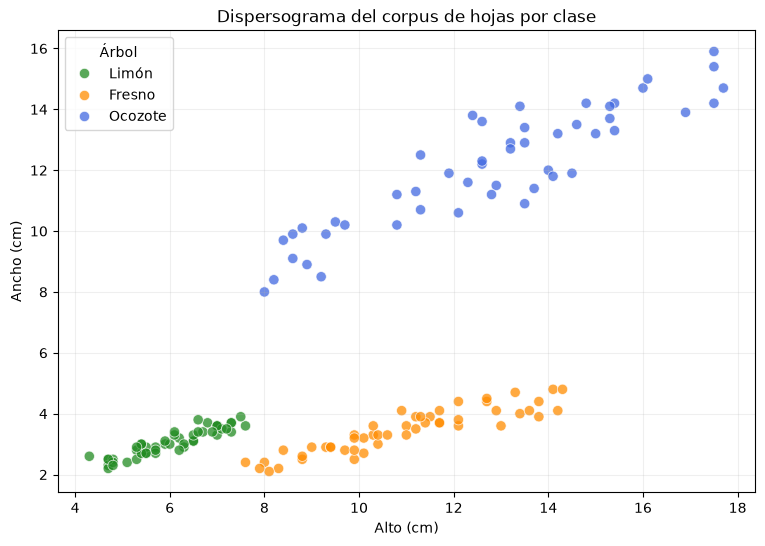

In [8]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=datos,
    x="Alto (cm)",
    y="Ancho (cm)",
    hue=columna_clase,
    hue_order=CLASES,
    palette=COLORES_CLASE,
    alpha=0.75,
    s=55
)

plt.title("Dispersograma del corpus de hojas por clase")
plt.xlabel("Alto (cm)")
plt.ylabel("Ancho (cm)")
plt.legend(title="Árbol")
plt.grid(alpha=0.2)
plt.show()

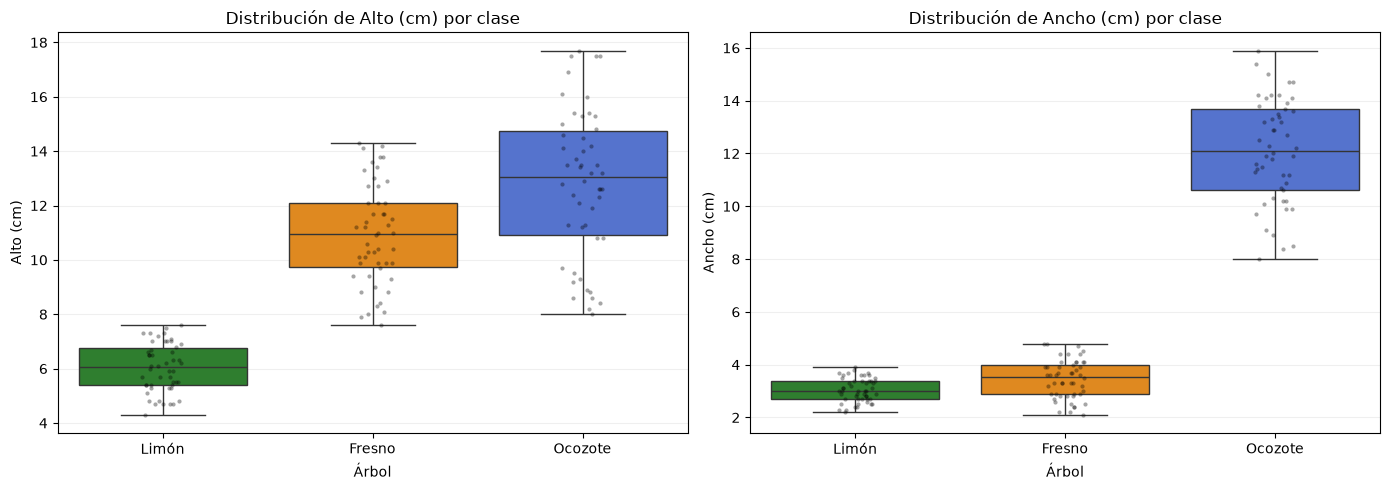

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, caracteristica in zip(axes, caracteristicas):
    sns.boxplot(
        data=datos,
        x=columna_clase,
        y=caracteristica,
        hue=columna_clase,
        order=CLASES,
        hue_order=CLASES,
        palette=COLORES_CLASE,
        legend=False,
        ax=ax
    )

    sns.stripplot(
        data=datos,
        x=columna_clase,
        y=caracteristica,
        order=CLASES,
        color="black",
        alpha=0.35,
        size=3,
        ax=ax
    )

    ax.set_title(f"Distribución de {caracteristica} por clase")
    ax.set_xlabel("Árbol")
    ax.set_ylabel(caracteristica)
    ax.grid(alpha=0.2, axis="y")

plt.tight_layout()
plt.show()

In [10]:
# Traslape de rangos entre clases para cada característica
for caracteristica in caracteristicas:
    print(f"{caracteristica}:")

    for i, clase_a in enumerate(CLASES):
        for clase_b in CLASES[i + 1:]:
            a = datos.loc[datos[columna_clase] == clase_a, caracteristica]
            b = datos.loc[datos[columna_clase] == clase_b, caracteristica]

            inicio = max(a.min(), b.min())
            fin = min(a.max(), b.max())

            if inicio <= fin:
                en_traslape = (
                    a.between(inicio, fin).sum()
                    + b.between(inicio, fin).sum()
                )
                print(
                    f"  {clase_a} y {clase_b}: traslape de {inicio:.1f} a {fin:.1f} cm "
                    f"({en_traslape} de {len(a) + len(b)} hojas dentro del traslape)"
                )
            else:
                print(f"  {clase_a} y {clase_b}: sin traslape")
    print()

Alto (cm):
  Limón y Fresno: traslape de 7.6 a 7.6 cm (2 de 100 hojas dentro del traslape)
  Limón y Ocozote: sin traslape
  Fresno y Ocozote: traslape de 8.0 a 14.3 cm (83 de 100 hojas dentro del traslape)

Ancho (cm):
  Limón y Fresno: traslape de 2.2 a 3.9 cm (86 de 100 hojas dentro del traslape)
  Limón y Ocozote: sin traslape
  Fresno y Ocozote: sin traslape



In [11]:
# Relación entre alto y ancho dentro de cada clase
relacion = pd.DataFrame({
    "Correlación Alto-Ancho": datos.groupby(columna_clase).apply(
        lambda g: g["Alto (cm)"].corr(g["Ancho (cm)"]),
        include_groups=False
    ),
    "Proporción Alto/Ancho (media)": (
        datos["Alto (cm)"] / datos["Ancho (cm)"]
    ).groupby(datos[columna_clase]).mean()
}).loc[CLASES].round(2)

relacion

,Correlación Alto-Ancho,Proporción Alto/Ancho (media)
Árbol,,
Limón,0.92,1.98
Fresno,0.91,3.21
Ocozote,0.91,1.05


### Interpretación del análisis exploratorio

La gráfica de dispersión muestra que **Ocozote** se separa claramente de las otras dos clases por su ancho: sus hojas miden entre 8.0 y 15.9 cm de ancho, mientras que ninguna hoja de Limón o Fresno supera los 4.8 cm. No existe traslape en el ancho entre Ocozote y las demás clases.

**Limón** y **Fresno** se traslapan casi por completo en el ancho: 86 de sus 100 hojas se encuentran dentro del intervalo común de 2.2 a 3.9 cm. Su diferencia principal está en el alto: las hojas de Limón miden entre 4.3 y 7.6 cm y las de Fresno entre 7.6 y 14.3 cm, por lo que solamente coinciden en el valor de 7.6 cm (2 hojas). En consecuencia, la frontera entre ambas clases depende sobre todo del alto y se ubica alrededor de los 7.6 cm, donde ambas clases quedan muy próximas.

En el alto, Fresno y Ocozote sí presentan un traslape amplio (de 8.0 a 14.3 cm, con 83 de 100 hojas dentro del intervalo), pero esto no afecta su separación, porque el ancho las distingue por completo.

Ocozote es la clase con mayor dispersión en ambas variables (desviación estándar de 2.75 cm en el alto y 1.97 cm en el ancho), mientras que Limón es la más compacta (0.89 y 0.45 cm). Dentro de cada clase, el alto y el ancho están positivamente correlacionados: las hojas más largas también tienden a ser más anchas, con correlaciones de 0.92 en Limón, 0.91 en Fresno y 0.91 en Ocozote. La proporción alto/ancho promedio es de 1.05 en Ocozote (hojas casi tan anchas como largas), 1.98 en Limón y 3.21 en Fresno (hojas alargadas).

Las dos variables tienen escalas diferentes (desviación estándar global de 3.48 cm en el alto y 4.37 cm en el ancho), por lo que los métodos basados en distancias se aplicarán sobre las variables estandarizadas.

Las medidas se registraron con un decimal y 10 hojas comparten exactamente el mismo par (alto, ancho) con otra hoja. Estos valores repetidos se conservan, ya que corresponden a hojas distintas y son esperables con una resolución de 0.1 cm. Finalmente, los identificadores están ordenados por clase (Limón del 1 al 50, Ocozote del 51 al 100 y Fresno del 101 al 150), por lo que las particiones de validación cruzada deberán barajar los datos.

---

# Modelo 1: Clustering jerárquico

El modelo se entrenará utilizando las 2 características del corpus de hojas (alto y ancho) **estandarizadas**. Ambas variables se miden en centímetros, pero tienen rangos y dispersiones distintas, por lo que sin estandarizar la variable con mayor dispersión dominaría el cálculo de distancias.

Se probarán diferentes números de clústeres (de 2 a 6), métodos de enlace y métricas de distancia. La mejor configuración se seleccionará mediante el coeficiente de silueta.

Las etiquetas reales no se utilizarán durante el entrenamiento; solamente servirán posteriormente para interpretar los grupos obtenidos.

---

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Datos originales:", X.shape)
print("Datos estandarizados:", X_scaled.shape)
print("Media después de estandarizar:", X_scaled.mean(axis=0).round(6))
print("Desviación estándar después de estandarizar:", X_scaled.std(axis=0).round(6))

Datos originales: (150, 2)
Datos estandarizados: (150, 2)
Media después de estandarizar: [0. 0.]
Desviación estándar después de estandarizar: [1. 1.]


## Búsqueda de la configuración

Para cada configuración se calculan dos coeficientes de silueta:

- **Silueta euclidiana:** se calcula con la distancia euclidiana sobre las variables estandarizadas para todas las configuraciones. Es el criterio de selección, porque permite comparar configuraciones con métricas distintas en una misma escala y también comparar el resultado con K-means.
- **Silueta con la métrica propia:** se calcula con la misma métrica utilizada por el enlace. Se reporta como referencia, pero no se usa para seleccionar, ya que los valores obtenidos con distancias diferentes no son comparables entre sí.

También se registra el tamaño del clúster más pequeño, para detectar configuraciones que solamente aíslan unas pocas hojas extremas.

**Diferencia con el notebook de cáncer de mama:** en cáncer de mama la silueta de cada configuración se calculó con su propia métrica de distancia, y la configuración seleccionada utilizó distancia coseno. En este notebook se ajustó el procedimiento: todas las configuraciones se comparan con la silueta euclidiana sobre las variables estandarizadas, ya que siluetas calculadas con métricas distintas no están en la misma escala. Por ello, las siluetas del clustering jerárquico de ambas bases no son directamente comparables.

In [14]:
resultados_jerarquico = []

configuraciones = [
    ("ward", "euclidean"),
    ("complete", "euclidean"),
    ("complete", "manhattan"),
    ("complete", "cosine"),
    ("average", "euclidean"),
    ("average", "manhattan"),
    ("average", "cosine"),
    ("single", "euclidean"),
    ("single", "manhattan"),
    ("single", "cosine")
]

for linkage_method, distance_metric in configuraciones:
    for n_clusters in range(2, 7):

        modelo = AgglomerativeClustering(
            n_clusters=n_clusters,
            linkage=linkage_method,
            metric=distance_metric
        )

        etiquetas_cluster = modelo.fit_predict(X_scaled)
        tamanos = np.bincount(etiquetas_cluster)

        resultados_jerarquico.append({
            "linkage": linkage_method,
            "metrica": distance_metric,
            "n_clusters": n_clusters,
            "silueta_euclidiana": silhouette_score(
                X_scaled,
                etiquetas_cluster,
                metric="euclidean"
            ),
            "silueta_metrica_propia": silhouette_score(
                X_scaled,
                etiquetas_cluster,
                metric=distance_metric
            ),
            "cluster_mas_pequeno": tamanos.min(),
            "tamanos": sorted(tamanos.tolist(), reverse=True)
        })

resultados_df = pd.DataFrame(resultados_jerarquico)

resultados_df = resultados_df.sort_values(
    by="silueta_euclidiana",
    ascending=False
).reset_index(drop=True)

resultados_df.head(10)

,linkage,metrica,n_clusters,silueta_euclidiana,silueta_metrica_propia,cluster_mas_pequeno,tamanos
0,ward,euclidean,4,0.614365,0.614365,11,"[59, 41, 39, 11]"
1,complete,euclidean,5,0.609669,0.609669,11,"[59, 41, 24, 15, 11]"
2,complete,manhattan,5,0.600555,0.589518,11,"[62, 38, 24, 15, 11]"
3,ward,euclidean,2,0.596540,0.596540,39,"[111, 39]"
4,average,manhattan,2,0.596540,0.627596,39,"[111, 39]"
5,average,euclidean,2,0.596540,0.596540,39,"[111, 39]"
6,ward,euclidean,5,0.593362,0.593362,7,"[59, 41, 32, 11, 7]"
7,average,euclidean,4,0.582661,0.582661,11,"[50, 50, 39, 11]"
8,complete,cosine,2,0.580049,0.722074,50,"[100, 50]"
9,complete,manhattan,2,0.580049,0.615633,50,"[100, 50]"


In [15]:
# Mejor configuración para cada número de clústeres
mejor_por_k_jerarquico = (
    resultados_df
    .loc[resultados_df.groupby("n_clusters")["silueta_euclidiana"].idxmax()]
    .reset_index(drop=True)
)

mejor_por_k_jerarquico

,linkage,metrica,n_clusters,silueta_euclidiana,silueta_metrica_propia,cluster_mas_pequeno,tamanos
0,ward,euclidean,2,0.596540,0.596540,39,"[111, 39]"
1,ward,euclidean,3,0.570427,0.570427,39,"[59, 52, 39]"
2,ward,euclidean,4,0.614365,0.614365,11,"[59, 41, 39, 11]"
3,complete,euclidean,5,0.609669,0.609669,11,"[59, 41, 24, 15, 11]"
4,complete,euclidean,6,0.576381,0.576381,11,"[59, 29, 24, 15, 12, 11]"


In [16]:
# Composición de las mejores configuraciones con 2 y 3 clústeres (solo para interpretar)
for _, fila in mejor_por_k_jerarquico[
    mejor_por_k_jerarquico["n_clusters"].isin([2, 3])
].iterrows():
    etiquetas_k = AgglomerativeClustering(
        n_clusters=int(fila["n_clusters"]),
        linkage=fila["linkage"],
        metric=fila["metrica"]
    ).fit_predict(X_scaled)

    print(
        f"{fila['linkage']} + {fila['metrica']}, k = {fila['n_clusters']} "
        f"(silueta = {fila['silueta_euclidiana']:.4f}):"
    )
    display(pd.crosstab(
        etiquetas_k,
        np.array(CLASES)[y],
        rownames=["Cluster"],
        colnames=["Árbol real"]
    )[CLASES])

ward + euclidean, k = 2 (silueta = 0.5965):


Árbol real,Limón,Fresno,Ocozote
Cluster,,,
0,50,50,11
1,0,0,39


ward + euclidean, k = 3 (silueta = 0.5704):


Árbol real,Limón,Fresno,Ocozote
Cluster,,,
0,0,41,11
1,0,0,39
2,50,9,0


In [17]:
# Configuraciones con mayor silueta usando su propia métrica (solo como referencia)
resultados_df.sort_values(
    by="silueta_metrica_propia",
    ascending=False
).head(5)

,linkage,metrica,n_clusters,silueta_euclidiana,silueta_metrica_propia,cluster_mas_pequeno,tamanos
19,average,cosine,5,0.565412,0.860237,11,"[50, 39, 26, 24, 11]"
33,average,cosine,6,0.532439,0.850700,2,"[50, 39, 26, 24, 9, 2]"
16,complete,cosine,4,0.572255,0.840791,11,"[69, 39, 31, 11]"
32,complete,cosine,5,0.539154,0.837893,11,"[50, 39, 31, 19, 11]"
29,complete,cosine,6,0.544616,0.837328,11,"[50, 39, 19, 18, 13, 11]"


In [18]:
# Se descartan configuraciones cuyo clúster más pequeño tenga menos del 5 % de las hojas
tamano_minimo = int(np.ceil(0.05 * len(X_scaled)))

candidatas = resultados_df[
    resultados_df["cluster_mas_pequeno"] >= tamano_minimo
]

mejor_config_jerarquico = candidatas.iloc[0]

print("Configuraciones evaluadas:", len(resultados_df))
print("Tamaño mínimo aceptado por clúster:", tamano_minimo)
print("Configuraciones descartadas:", len(resultados_df) - len(candidatas))
print()
print("Configuración seleccionada:")
print(mejor_config_jerarquico)

Configuraciones evaluadas: 50
Tamaño mínimo aceptado por clúster: 8
Configuraciones descartadas: 14

Configuración seleccionada:
linkage                               ward
metrica                          euclidean
n_clusters                               4
silueta_euclidiana                0.614365
silueta_metrica_propia            0.614365
cluster_mas_pequeno                     11
tamanos                   [59, 41, 39, 11]
Name: 0, dtype: object


## Selección de la mejor configuración

Se evaluaron 50 configuraciones, resultado de combinar 10 pares de enlace y métrica con 2 a 6 clústeres. Se descartaron 14 configuraciones porque formaban algún clúster con menos de 8 hojas (5 % del corpus), es decir, solo aislaban unas pocas hojas extremas.

La configuración seleccionada utiliza enlace **ward**, distancia **euclidiana** y **4 clústeres**. Obtuvo una silueta de **0.6144** y formó grupos de **59, 41, 39 y 11 hojas**.

Las configuraciones con distancia coseno obtuvieron las siluetas más altas cuando se evaluaron con su propia métrica. La mejor, con enlace average y 5 clústeres, llegó a 0.8602, pero con la silueta euclidiana baja a 0.5654. Con solo dos variables estandarizadas, la distancia coseno compara la dirección de cada hoja respecto a la media del corpus e ignora qué tan lejos está de ella. Por eso divide el plano en sectores angulares y su silueta no es comparable con la de las demás métricas.

La silueta **no favorece 3 clústeres**, aunque el corpus contiene tres árboles. La mejor configuración con k = 3 (ward) obtuvo 0.5704, menos que k = 4 (0.6144) y que k = 2 (0.5965):

- Con **k = 2**, el modelo separa 39 hojas de Ocozote y deja en el otro grupo todas las hojas de Limón y Fresno junto con 11 de Ocozote.
- Con **k = 3**, Limón queda en un grupo con 9 hojas de Fresno, y las 11 hojas de Ocozote se unen a las 41 hojas restantes de Fresno.

Por lo tanto, ninguna de estas configuraciones recupera las tres clases. Se conserva la configuración de 4 clústeres indicada por la silueta, sin forzar k = 3.

In [19]:
mejor_modelo_jerarquico = AgglomerativeClustering(
    n_clusters=int(mejor_config_jerarquico["n_clusters"]),
    linkage=mejor_config_jerarquico["linkage"],
    metric=mejor_config_jerarquico["metrica"],
    compute_distances=True
)

clusters_jerarquico = mejor_modelo_jerarquico.fit_predict(X_scaled)
k_jerarquico = mejor_modelo_jerarquico.n_clusters_

valores, cantidades = np.unique(
    clusters_jerarquico,
    return_counts=True
)

print("Clústeres:", valores)
print("Cantidad de hojas por clúster:", cantidades)

Clústeres: [0 1 2 3]
Cantidad de hojas por clúster: [39 41 59 11]


## Dendrograma del clustering jerárquico

El dendrograma representa cómo las hojas se fusionan progresivamente para formar los clústeres. Se utiliza la configuración final. La línea horizontal representa el corte del árbol que produce el número de clústeres seleccionado.

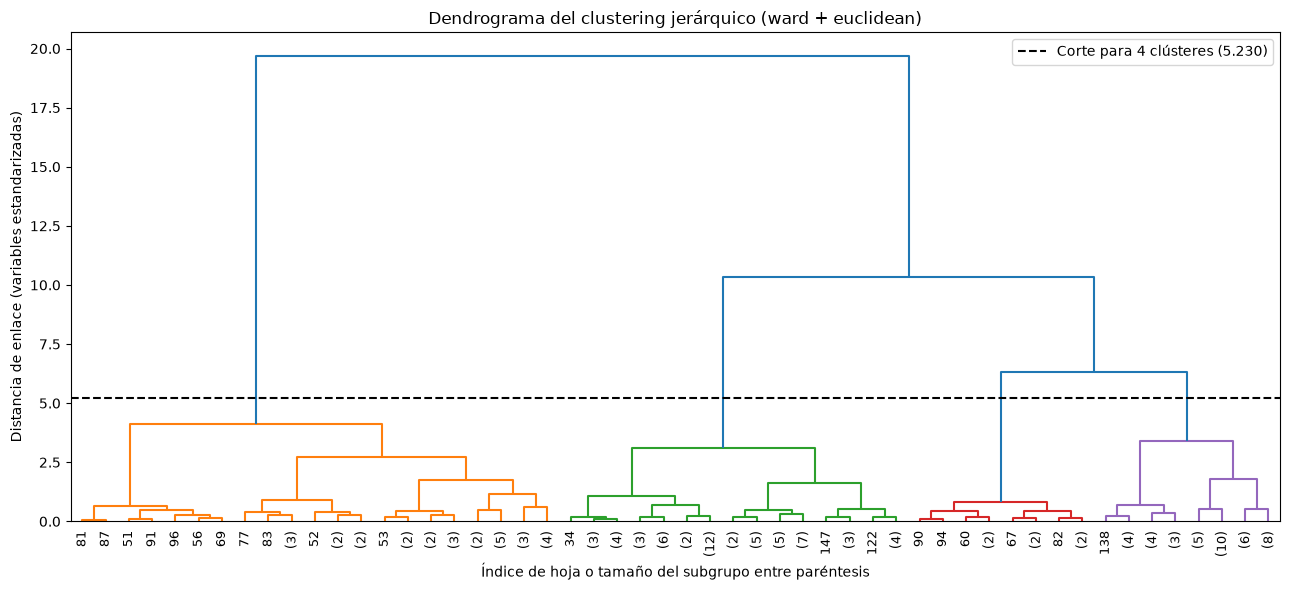

Distancias de las últimas 5 fusiones: [ 3.398  4.128  6.333 10.341 19.702]


In [20]:
from scipy.cluster.hierarchy import dendrogram

def matriz_para_dendrograma(modelo):
    n_muestras = len(modelo.labels_)
    tamanos = np.zeros(len(modelo.children_), dtype=int)

    for i, hijos in enumerate(modelo.children_):
        for hijo in hijos:
            if hijo < n_muestras:
                tamanos[i] += 1
            else:
                tamanos[i] += tamanos[hijo - n_muestras]

    matriz = np.column_stack([
        modelo.children_,
        modelo.distances_,
        tamanos
    ]).astype(float)

    return matriz


matriz_jerarquica = matriz_para_dendrograma(
    mejor_modelo_jerarquico
)

# El corte se ubica entre las dos últimas fusiones que separan k clústeres
corte_jerarquico = matriz_jerarquica[
    [-k_jerarquico, -(k_jerarquico - 1)], 2
].mean()

fig, ax = plt.subplots(figsize=(13, 6))

dendrogram(
    matriz_jerarquica,
    truncate_mode="level",
    p=5,
    leaf_font_size=9,
    color_threshold=corte_jerarquico,
    ax=ax
)

ax.axhline(
    y=corte_jerarquico,
    color="black",
    linestyle="--",
    label=f"Corte para {k_jerarquico} clústeres ({corte_jerarquico:.3f})"
)

ax.set_title(
    "Dendrograma del clustering jerárquico "
    f"({mejor_config_jerarquico['linkage']} + {mejor_config_jerarquico['metrica']})"
)

ax.set_xlabel(
    "Índice de hoja o tamaño del subgrupo entre paréntesis"
)

ax.set_ylabel("Distancia de enlace (variables estandarizadas)")
ax.legend()

plt.tight_layout()
plt.show()

print("Distancias de las últimas 5 fusiones:", matriz_jerarquica[-5:, 2].round(3))

### Interpretación del dendrograma

El dendrograma representa el proceso de agrupamiento de las hojas mediante enlace **ward** y distancia **euclidiana** sobre las variables estandarizadas. Al realizar el corte en una distancia de **5.230**, el árbol queda dividido en cuatro ramas, correspondientes a los cuatro clústeres seleccionados.

Las últimas cinco fusiones ocurren a distancias de 3.398, 4.128, 6.333, 10.341 y 19.702. El corte se ubica entre 4.128 y 6.333; la fusión a 6.333 reduciría los grupos a tres. El salto más grande ocurre en la última fusión (de 10.341 a 19.702), que separa un grupo de 39 hojas del resto. Este salto corresponde a la división en dos grupos, pero la silueta favorece la división en cuatro, porque esos grupos son más compactos.

La gráfica se presenta de forma truncada para facilitar su lectura; los valores entre paréntesis indican la cantidad de hojas contenidas en cada subgrupo.

## Visualización de los clústeres en el plano Alto × Ancho

El modelo fue ajustado con las variables estandarizadas, pero los clústeres se grafican en el **espacio original de las dos características, en centímetros**. Como la estandarización solo cambia la escala de cada eje, la forma de los grupos se conserva. No se utiliza PCA.

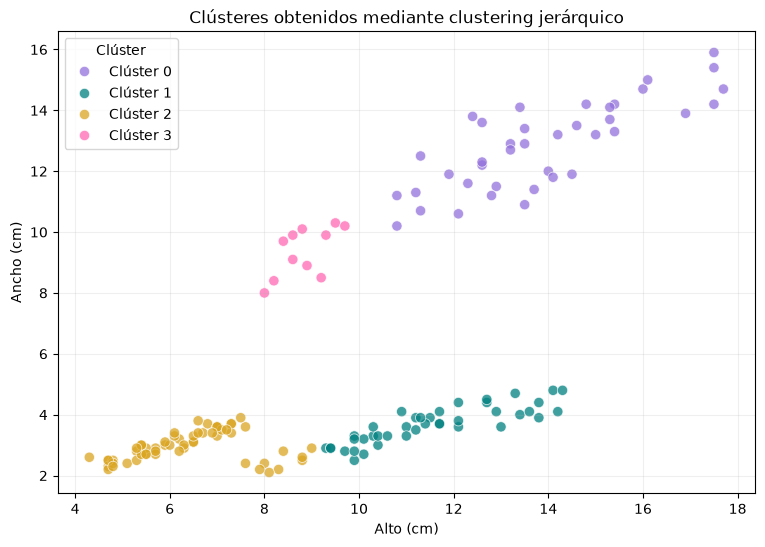

Alto (cm)             Ancho (cm)            
               mean   min   max       mean   min   max
Clúster 0     13.93  10.8  17.7      12.87  10.2  15.9
Clúster 1     11.52   9.3  14.3       3.67   2.5   4.8
Clúster 2      6.37   4.3   9.0       2.96   2.1   3.9
Clúster 3      8.84   8.0   9.7       9.36   8.0  10.3

In [21]:
nombres_cluster_jerarquico = np.array(
    [f"Clúster {c}" for c in clusters_jerarquico]
)

orden_cluster_jerarquico = [f"Clúster {c}" for c in range(k_jerarquico)]

paleta_cluster_jerarquico = dict(
    zip(orden_cluster_jerarquico, COLORES_CLUSTER)
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=nombres_cluster_jerarquico,
    hue_order=orden_cluster_jerarquico,
    palette=paleta_cluster_jerarquico,
    alpha=0.75,
    s=55
)

plt.title("Clústeres obtenidos mediante clustering jerárquico")
plt.xlabel("Alto (cm)")
plt.ylabel("Ancho (cm)")
plt.legend(title="Clúster")
plt.grid(alpha=0.2)
plt.show()

resumen_clusters_jerarquico = (
    pd.DataFrame(X, columns=caracteristicas)
    .groupby(nombres_cluster_jerarquico)
    .agg(["mean", "min", "max"])
    .round(2)
)

resumen_clusters_jerarquico

### Interpretación de la visualización

El clustering se ajustó con las variables estandarizadas, pero la gráfica muestra los clústeres sobre el alto y el ancho en centímetros. Los grupos ocupan regiones bien definidas del plano:

- **Clúster 0:** hojas grandes y anchas (alto de 10.8 a 17.7 cm y ancho de 10.2 a 15.9 cm).
- **Clúster 3:** hojas anchas pero más cortas (alto de 8.0 a 9.7 cm y ancho de 8.0 a 10.3 cm).
- **Clúster 1:** hojas alargadas y angostas (alto de 9.3 a 14.3 cm y ancho de 2.5 a 4.8 cm).
- **Clúster 2:** las hojas más pequeñas (alto de 4.3 a 9.0 cm y ancho de 2.1 a 3.9 cm).

El modelo separa primero las hojas anchas (clústeres 0 y 3) de las angostas (clústeres 1 y 2), lo cual coincide con la separación por ancho observada en el análisis exploratorio. Las hojas anchas se dividen en dos grupos por un hueco en el alto entre 9.7 y 10.8 cm. Las hojas angostas se dividen según el alto alrededor de 9 cm, ya que el clúster 2 llega hasta 9.0 cm y el clúster 1 comienza en 9.3 cm.

In [22]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

comparacion_jerarquico = pd.DataFrame({
    "Cluster": clusters_jerarquico,
    "Árbol real": np.array(CLASES)[y]
})

tabla_comparacion = pd.crosstab(
    comparacion_jerarquico["Cluster"],
    comparacion_jerarquico["Árbol real"]
)[CLASES]

ari_jerarquico = adjusted_rand_score(
    y,
    clusters_jerarquico
)

nmi_jerarquico = normalized_mutual_info_score(
    y,
    clusters_jerarquico
)

silueta_jerarquico = silhouette_score(
    X_scaled,
    clusters_jerarquico
)

print("Comparación entre clústeres y árboles reales:")
display(tabla_comparacion)

print("Coeficiente de silueta (euclidiana):", silueta_jerarquico)
print("Índice Rand ajustado:", ari_jerarquico)
print("Información mutua normalizada:", nmi_jerarquico)

Comparación entre clústeres y árboles reales:


Árbol real,Limón,Fresno,Ocozote
Cluster,,,
0,0,0,39
1,0,41,0
2,50,9,0
3,0,0,11


Coeficiente de silueta (euclidiana): 0.6143648648694832
Índice Rand ajustado: 0.7407438389854611
Información mutua normalizada: 0.7879944588753116


### Evaluación frente a las etiquetas reales

Tres de los cuatro clústeres contienen hojas de un solo árbol: el clúster 0 agrupó 39 hojas de Ocozote, el clúster 3 agrupó 11 hojas de Ocozote y el clúster 1 agrupó 41 hojas de Fresno. El único clúster mixto es el 2, que reunió las 50 hojas de Limón y 9 hojas de Fresno.

El índice Rand ajustado fue de 0.7407 y la información mutua normalizada fue de 0.7880. Estos resultados indican una correspondencia considerable entre los grupos encontrados y los árboles reales, a pesar de que las etiquetas no se utilizaron para entrenar el modelo. El ARI no es más alto por dos razones: Ocozote quedó dividido en dos clústeres y 9 hojas de Fresno quedaron junto a las de Limón.

El modelo no sustituye a un clasificador supervisado, pero muestra que el alto y el ancho contienen una estructura natural muy relacionada con el tipo de árbol.

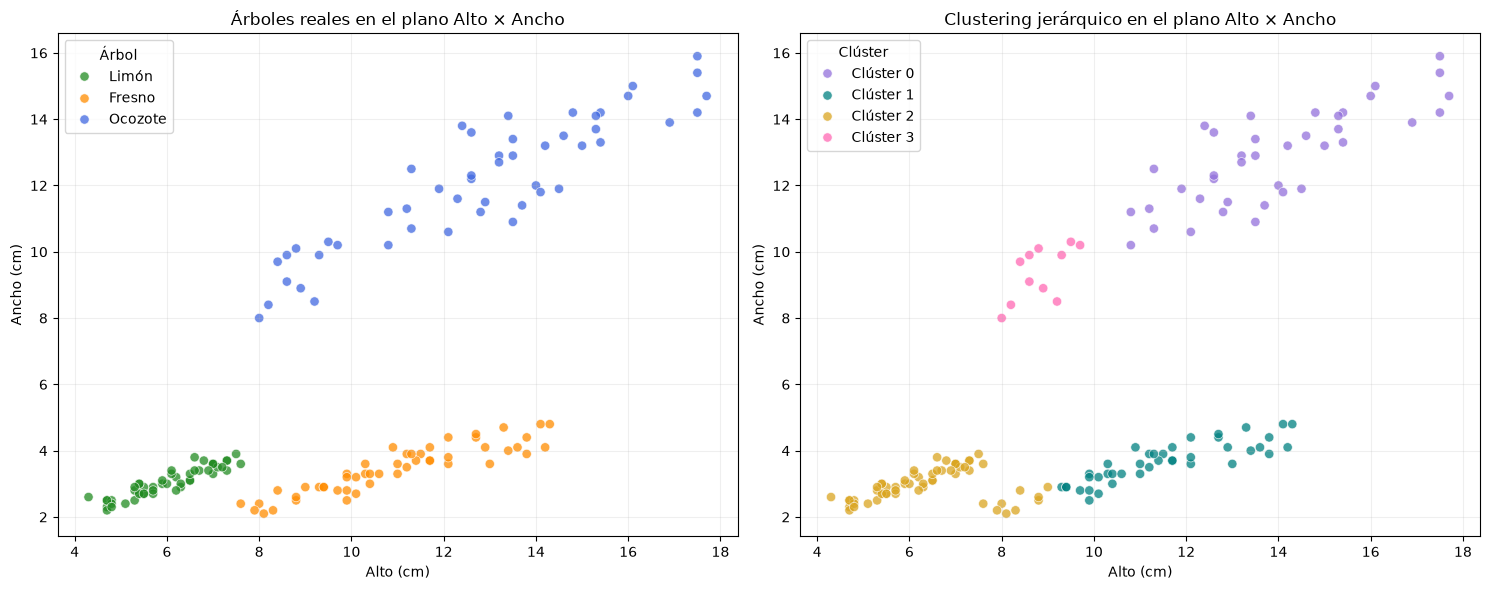

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Clases reales
sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=np.array(CLASES)[y],
    hue_order=CLASES,
    palette=COLORES_CLASE,
    alpha=0.75,
    s=45,
    ax=axes[0]
)

axes[0].set_title("Árboles reales en el plano Alto × Ancho")
axes[0].set_xlabel("Alto (cm)")
axes[0].set_ylabel("Ancho (cm)")
axes[0].legend(title="Árbol")
axes[0].grid(alpha=0.2)

# Clústeres obtenidos
sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=nombres_cluster_jerarquico,
    hue_order=orden_cluster_jerarquico,
    palette=paleta_cluster_jerarquico,
    alpha=0.75,
    s=45,
    ax=axes[1]
)

axes[1].set_title("Clustering jerárquico en el plano Alto × Ancho")
axes[1].set_xlabel("Alto (cm)")
axes[1].set_ylabel("Ancho (cm)")
axes[1].legend(title="Clúster")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Comparación visual con las etiquetas reales

Al comparar ambas gráficas se observa que los clústeres siguen de cerca a los árboles reales. Las diferencias aparecen en dos zonas:

1. **Hojas de Ocozote más pequeñas:** las hojas de Ocozote con alto menor a 10 cm forman un grupo propio (clúster 3), separado del resto de su clase por un hueco en el alto. El clustering no puede saber que ambos grupos pertenecen al mismo árbol; solamente detecta que forman dos regiones compactas.
2. **Frontera entre Limón y Fresno:** las 9 hojas de Fresno asignadas al clúster 2 son las más cortas de su clase y se encuentran junto a las hojas de Limón, en la zona donde ambas clases casi se tocan en el alto. Como también tienen anchos similares, el modelo no tiene información suficiente para separarlas.

El clustering se ajustó en el espacio de las dos características originales estandarizadas, y las gráficas se muestran en ese mismo espacio expresado en centímetros, sin PCA.

---

# Modelo 2: Clustering K-means

En esta sección se aplicará el algoritmo **K-means** al corpus de hojas.

El modelo se ajustará utilizando las **2 características estandarizadas** (las mismas variables `X_scaled` del clustering jerárquico). Se probarán diferentes números de clústeres, dos métodos de inicialización y distintos números de reinicios, y se calculará el **coeficiente de silueta** para seleccionar la configuración final.

Las etiquetas reales de los árboles no se utilizarán durante el entrenamiento; solamente se emplearán posteriormente para comparar y evaluar los agrupamientos obtenidos.

**Diferencia con el notebook de cáncer de mama:** en cáncer de mama K-means se ajustó con una sola configuración de inicialización (k-means++ con 20 reinicios) y solo se varió el número de clústeres. En este notebook también se exploran la inicialización y el número de reinicios, como lo pide el enunciado. Para cada número de clústeres se conserva la solución con menor inercia, y el número de clústeres se elige por silueta.

---

In [24]:
from sklearn.cluster import KMeans

resultados_kmeans = []

for inicializacion in ["k-means++", "random"]:
    for reinicios in [1, 10, 20]:
        for n_clusters in range(2, 7):

            modelo_kmeans = KMeans(
                n_clusters=n_clusters,
                init=inicializacion,
                n_init=reinicios,
                random_state=42
            )

            etiquetas_kmeans = modelo_kmeans.fit_predict(X_scaled)

            silueta = silhouette_score(
                X_scaled,
                etiquetas_kmeans
            )

            valores, cantidades = np.unique(
                etiquetas_kmeans,
                return_counts=True
            )

            resultados_kmeans.append({
                "init": inicializacion,
                "n_init": reinicios,
                "n_clusters": n_clusters,
                "silueta": silueta,
                "inercia": modelo_kmeans.inertia_,
                "distribucion": sorted(cantidades.tolist(), reverse=True)
            })

resultados_kmeans_df = pd.DataFrame(resultados_kmeans)

print("Configuraciones evaluadas:", len(resultados_kmeans_df))

# Resumen por número de clústeres con la inicialización k-means++ y 20 reinicios
resultados_kmeans_df[
    (resultados_kmeans_df["init"] == "k-means++")
    & (resultados_kmeans_df["n_init"] == 20)
].reset_index(drop=True)

Configuraciones evaluadas: 30


,init,n_init,n_clusters,silueta,inercia,distribucion
0,k-means++,20,2,0.595809,104.894367,"[108, 42]"
1,k-means++,20,3,0.570948,52.375853,"[58, 53, 39]"
2,k-means++,20,4,0.610609,29.344702,"[58, 42, 32, 18]"
3,k-means++,20,5,0.611521,21.553204,"[58, 42, 23, 14, 13]"
4,k-means++,20,6,0.563927,14.251385,"[51, 26, 23, 23, 14, 13]"


In [25]:
# Efecto de la inicialización y los reinicios sobre la silueta y la inercia
tabla_inicializacion = resultados_kmeans_df.pivot_table(
    index="n_clusters",
    columns=["init", "n_init"],
    values=["silueta", "inercia"]
).round(4)

tabla_inicializacion

inercia                                                    \
init       k-means++                        random                       
n_init            1         10        20        1         10        20   
n_clusters                                                               
2           104.8944  104.8944  104.8944  104.8944  104.8944  104.8944   
3            52.3759   52.3759   52.3759   52.3759   52.3759   52.3759   
4            29.3880   29.3447   29.3447   29.3880   29.3447   29.3447   
5            22.0862   21.5548   21.5532   22.0862   21.5532   21.5532   
6            14.2514   14.2514   14.2514   18.6437   14.2514   14.2514   

             silueta                                          
init       k-means++                  random                  
n_init            1       10      20      1       10      20  
n_clusters                                                    
2             0.5958  0.5958  0.5958  0.5958  0.5958  0.5958  
3             0.5709  0.5709  0.5709  0.5709  0.5709  0.5709  
4             0.6072  0.6106  0.6106  0.6072  0.6106  0.6106  
5             0.5588  0.6131  0.6115  0.5588  0.6115  0.6115  
6             0.5639  0.5639  0.5639  0.5190  0.5639  0.5639

## Evaluación del número de clústeres

Para seleccionar el número de clústeres se comparan dos criterios:

- **Método del codo:** analiza la reducción de la inercia.
- **Coeficiente de silueta:** mide qué tan compactos y separados están los grupos. Un valor mayor representa una mejor agrupación.

Las curvas corresponden a la inicialización k-means++ con 20 reinicios.

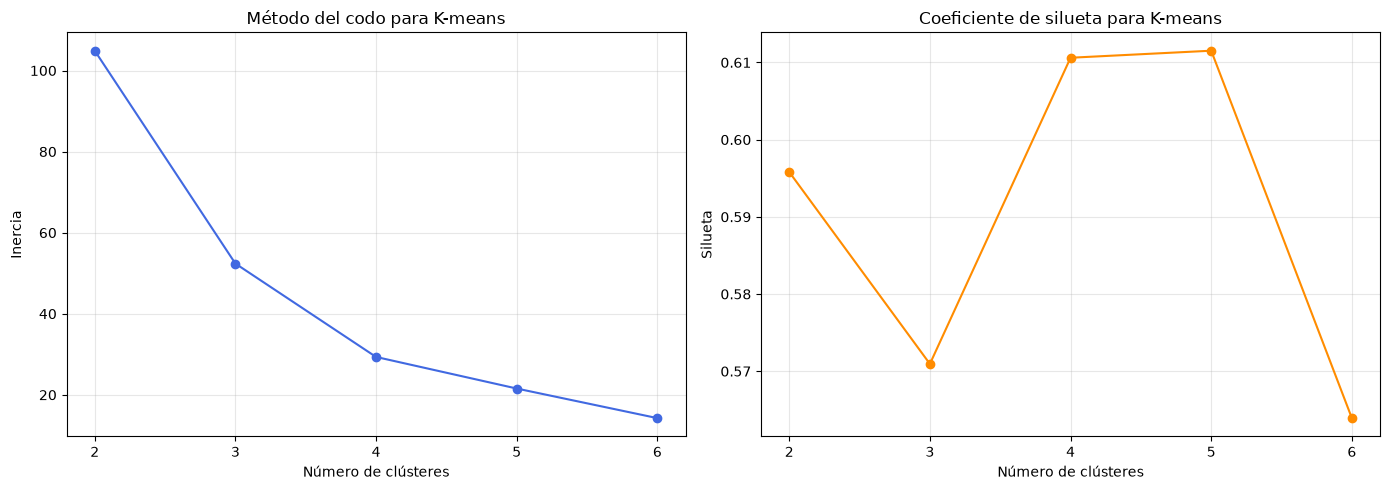

Reducción relativa de la inercia al agregar un clúster (%): [50.07, 43.97, 26.55, 33.88]


In [26]:
curvas_kmeans = resultados_kmeans_df[
    (resultados_kmeans_df["init"] == "k-means++")
    & (resultados_kmeans_df["n_init"] == 20)
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Método del codo
axes[0].plot(
    curvas_kmeans["n_clusters"],
    curvas_kmeans["inercia"],
    marker="o",
    color="royalblue"
)

axes[0].set_title("Método del codo para K-means")
axes[0].set_xlabel("Número de clústeres")
axes[0].set_ylabel("Inercia")
axes[0].set_xticks(curvas_kmeans["n_clusters"])
axes[0].grid(alpha=0.3)

# Coeficiente de silueta
axes[1].plot(
    curvas_kmeans["n_clusters"],
    curvas_kmeans["silueta"],
    marker="o",
    color="darkorange"
)

axes[1].set_title("Coeficiente de silueta para K-means")
axes[1].set_xlabel("Número de clústeres")
axes[1].set_ylabel("Silueta")
axes[1].set_xticks(curvas_kmeans["n_clusters"])
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(
    "Reducción relativa de la inercia al agregar un clúster (%):",
    (-curvas_kmeans["inercia"].pct_change() * 100).round(2).tolist()[1:]
)

In [27]:
# Paso 1: para cada k se conserva la solución con menor inercia (objetivo de K-means).
# La inicialización y los reinicios sirven para alcanzar ese mínimo; en caso de empate
# se prefiere k-means++ y el mayor número de reinicios.
tamano_minimo = int(np.ceil(0.05 * len(X_scaled)))

candidatas_kmeans = resultados_kmeans_df[
    resultados_kmeans_df["distribucion"].apply(min) >= tamano_minimo
].copy()

candidatas_kmeans["inercia_redondeada"] = candidatas_kmeans["inercia"].round(4)
candidatas_kmeans["es_kmeanspp"] = candidatas_kmeans["init"] == "k-means++"

mejor_por_k_kmeans = (
    candidatas_kmeans
    .sort_values(
        by=["n_clusters", "inercia_redondeada", "es_kmeanspp", "n_init"],
        ascending=[True, True, False, False]
    )
    .groupby("n_clusters")
    .head(1)
    .reset_index(drop=True)
)

# Paso 2: entre esas soluciones se elige el número de clústeres con mayor silueta
mejor_config_kmeans = mejor_por_k_kmeans.loc[
    mejor_por_k_kmeans["silueta"].idxmax()
]

print("Configuraciones descartadas por clústeres pequeños:",
      len(resultados_kmeans_df) - len(candidatas_kmeans))
display(mejor_por_k_kmeans[["init", "n_init", "n_clusters", "silueta", "inercia", "distribucion"]])

print("Configuración seleccionada:")
print(mejor_config_kmeans[["init", "n_init", "n_clusters", "silueta", "inercia", "distribucion"]])

Configuraciones descartadas por clústeres pequeños: 0


,init,n_init,n_clusters,silueta,inercia,distribucion
0,k-means++,20,2,0.595809,104.894367,"[108, 42]"
1,k-means++,20,3,0.570948,52.375853,"[58, 53, 39]"
2,k-means++,20,4,0.610609,29.344702,"[58, 42, 32, 18]"
3,k-means++,20,5,0.611521,21.553204,"[58, 42, 23, 14, 13]"
4,k-means++,20,6,0.563927,14.251385,"[51, 26, 23, 23, 14, 13]"


Configuración seleccionada:
init                       k-means++
n_init                            20
n_clusters                         5
silueta                     0.611521
inercia                    21.553204
distribucion    [58, 42, 23, 14, 13]
Name: 3, dtype: object


In [28]:
# Composición de K-means con 2 y 3 clústeres (solo para interpretar)
for n_clusters in [2, 3]:
    etiquetas_k = KMeans(
        n_clusters=n_clusters,
        init="k-means++",
        n_init=20,
        random_state=42
    ).fit_predict(X_scaled)

    print(f"K-means con k = {n_clusters}:")
    display(pd.crosstab(
        etiquetas_k,
        np.array(CLASES)[y],
        rownames=["Cluster"],
        colnames=["Árbol real"]
    )[CLASES])

K-means con k = 2:


Árbol real,Limón,Fresno,Ocozote
Cluster,,,
0,0,0,42
1,50,50,8


K-means con k = 3:


Árbol real,Limón,Fresno,Ocozote
Cluster,,,
0,0,0,39
1,50,8,0
2,0,42,11


## Selección de la configuración final

Se evaluaron 30 configuraciones, resultado de combinar 2 métodos de inicialización (k-means++ y aleatoria), 3 números de reinicios (1, 10 y 20) y de 2 a 6 clústeres. Ninguna configuración formó clústeres con menos de 8 hojas.

La inicialización y los reinicios no modifican el resultado con 2 y 3 clústeres. Con 4 o más clústeres, un solo reinicio puede quedar en un mínimo local con mayor inercia: por ejemplo, con 5 clústeres la inercia fue de 22.0862 con un reinicio y de 21.5532 con 20 reinicios. Por ello, para cada número de clústeres se conservó la solución con menor inercia, que es el objetivo que K-means busca minimizar, y entre esas soluciones se eligió el número de clústeres con mayor silueta. No se eligieron los reinicios directamente por silueta, porque eso puede favorecer una solución que K-means no alcanzó correctamente.

El método del codo no presenta un punto de quiebre definido. La inercia se reduce 50.07 % al pasar de 2 a 3 clústeres y 43.97 % al pasar de 3 a 4. Después la reducción es menor (26.55 % de 4 a 5 y 33.88 % de 5 a 6).

El coeficiente de silueta alcanza su valor máximo con **5 clústeres**, con un resultado de **0.6115**, prácticamente igual al obtenido con 4 clústeres (0.6106). Con 3 clústeres la silueta baja a 0.5709, por debajo también de 2 clústeres (0.5958). Al igual que en el clustering jerárquico, la silueta no favorece 3 clústeres:

- Con **k = 2**, K-means separa 42 hojas de Ocozote y agrupa las demás (50 de Limón, 50 de Fresno y 8 de Ocozote).
- Con **k = 3**, un grupo contiene 39 hojas de Ocozote, otro las 50 de Limón con 8 de Fresno, y el tercero 42 de Fresno con 11 de Ocozote.

Se seleccionó la configuración final de **K-means con 5 clústeres, inicialización k-means++ y 20 reinicios**, que produjo grupos de **58, 42, 23, 14 y 13 hojas**. La selección se realizó utilizando únicamente las características estandarizadas y métricas internas del agrupamiento, sin utilizar los árboles reales.

In [29]:
mejor_modelo_kmeans = KMeans(
    n_clusters=int(mejor_config_kmeans["n_clusters"]),
    init=mejor_config_kmeans["init"],
    n_init=int(mejor_config_kmeans["n_init"]),
    random_state=42
)

clusters_kmeans = mejor_modelo_kmeans.fit_predict(X_scaled)
k_kmeans = mejor_modelo_kmeans.n_clusters

valores_kmeans, cantidades_kmeans = np.unique(
    clusters_kmeans,
    return_counts=True
)

silueta_kmeans = silhouette_score(
    X_scaled,
    clusters_kmeans
)

print("Clústeres:", valores_kmeans)
print("Cantidad de hojas por clúster:", cantidades_kmeans)
print("Coeficiente de silueta:", silueta_kmeans)
print("Inercia:", mejor_modelo_kmeans.inertia_)

Clústeres: [0 1 2 3 4]
Cantidad de hojas por clúster: [58 23 42 13 14]
Coeficiente de silueta: 0.6115213928894707
Inercia: 21.553203920359458


## Visualización de K-means en el plano Alto × Ancho

El modelo K-means fue ajustado utilizando las 2 características estandarizadas. Para representar los resultados, las hojas y los centroides se grafican en el **espacio original, en centímetros**; los centroides se regresan a centímetros invirtiendo la estandarización. No se utiliza PCA.

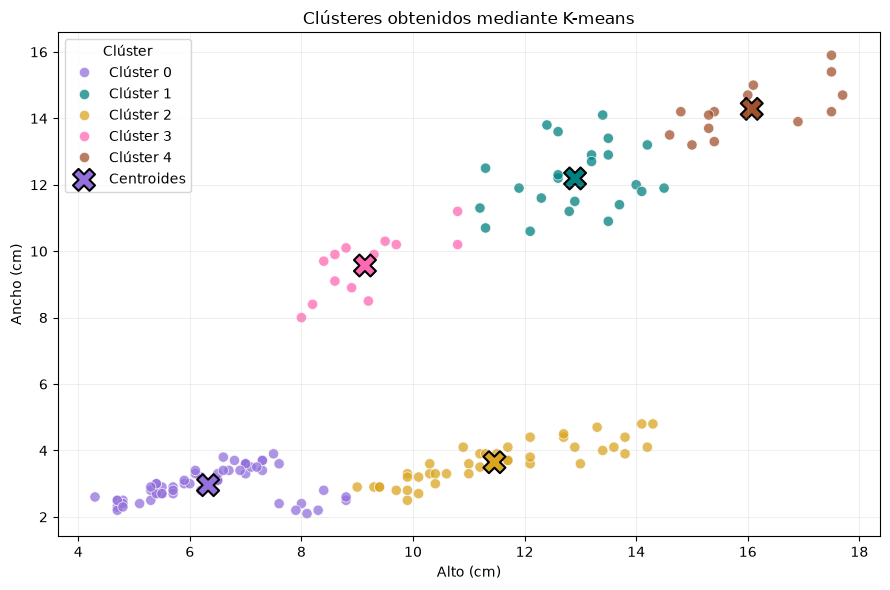

,Alto (cm),Ancho (cm)
Clúster 0,6.33,2.96
Clúster 1,12.90,12.19
Clúster 2,11.46,3.65
Clúster 3,9.14,9.57
Clúster 4,16.07,14.29


In [30]:
# Centroides regresados a centímetros
centroides_kmeans_cm = scaler.inverse_transform(
    mejor_modelo_kmeans.cluster_centers_
)

nombres_cluster_kmeans = np.array(
    [f"Clúster {c}" for c in clusters_kmeans]
)

orden_cluster_kmeans = [f"Clúster {c}" for c in range(k_kmeans)]

paleta_cluster_kmeans = dict(
    zip(orden_cluster_kmeans, COLORES_CLUSTER)
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=nombres_cluster_kmeans,
    hue_order=orden_cluster_kmeans,
    palette=paleta_cluster_kmeans,
    alpha=0.75,
    s=55
)

# Dibujar los centroides
plt.scatter(
    centroides_kmeans_cm[:, 0],
    centroides_kmeans_cm[:, 1],
    marker="X",
    s=250,
    c=COLORES_CLUSTER[:k_kmeans],
    edgecolor="black",
    linewidth=1.5,
    label="Centroides"
)

plt.title("Clústeres obtenidos mediante K-means")
plt.xlabel("Alto (cm)")
plt.ylabel("Ancho (cm)")
plt.legend(title="Clúster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

pd.DataFrame(
    centroides_kmeans_cm,
    columns=caracteristicas,
    index=orden_cluster_kmeans
).round(2)

### Interpretación de la visualización

La gráfica muestra los cinco clústeres sobre el alto y el ancho en centímetros. Las marcas en forma de X representan los centroides calculados por K-means, regresados a centímetros.

Dos clústeres ocupan la región de hojas angostas:

- **Clúster 0**, con centroide en 6.33 cm de alto y 2.96 cm de ancho (las hojas más pequeñas).
- **Clúster 2**, con centroide en 11.46 cm de alto y 3.65 cm de ancho (hojas alargadas).

Los otros tres clústeres dividen la región de hojas anchas a lo largo de la diagonal:

- **Clúster 3**, con centroide en 9.14 × 9.57 cm.
- **Clúster 1**, con centroide en 12.90 × 12.19 cm.
- **Clúster 4**, con centroide en 16.07 × 14.29 cm.

K-means asigna cada hoja al centroide más cercano, por lo que tiende a formar grupos compactos y de tamaño similar. La región de hojas anchas es la más dispersa del corpus y está alargada en diagonal, porque el alto y el ancho crecen juntos. Por eso K-means la corta en tres segmentos en lugar de tratarla como un solo grupo.

In [31]:
arboles_reales = pd.Series(
    np.array(CLASES)[y],
    name="Árbol real"
)

clusters_kmeans_serie = pd.Series(
    clusters_kmeans,
    name="Clúster"
)

tabla_comparacion_kmeans = pd.crosstab(
    clusters_kmeans_serie,
    arboles_reales
)[CLASES]

ari_kmeans = adjusted_rand_score(
    y,
    clusters_kmeans
)

nmi_kmeans = normalized_mutual_info_score(
    y,
    clusters_kmeans
)

print("Comparación entre clústeres y árboles reales:")
display(tabla_comparacion_kmeans)

print("Índice Rand ajustado:", ari_kmeans)
print("Información mutua normalizada:", nmi_kmeans)

Comparación entre clústeres y árboles reales:


Árbol real,Limón,Fresno,Ocozote
Clúster,,,
0,50,8,0
1,0,0,23
2,0,42,0
3,0,0,13
4,0,0,14


Índice Rand ajustado: 0.671149601827592
Información mutua normalizada: 0.7419442749299275


## Evaluación frente a las etiquetas reales

Cuatro de los cinco clústeres contienen hojas de un solo árbol: el clúster 2 agrupó 42 hojas de Fresno, y los clústeres 1, 3 y 4 agruparon 23, 13 y 14 hojas de Ocozote, respectivamente. El único clúster mixto es el 0, que reunió las 50 hojas de Limón y 8 hojas de Fresno.

El índice Rand ajustado fue de 0.6711 y la información mutua normalizada fue de 0.7419. Estos resultados indican una correspondencia considerable entre los grupos encontrados por K-means y los árboles reales, aunque Ocozote quedó repartido en tres clústeres, lo cual reduce ambos índices.

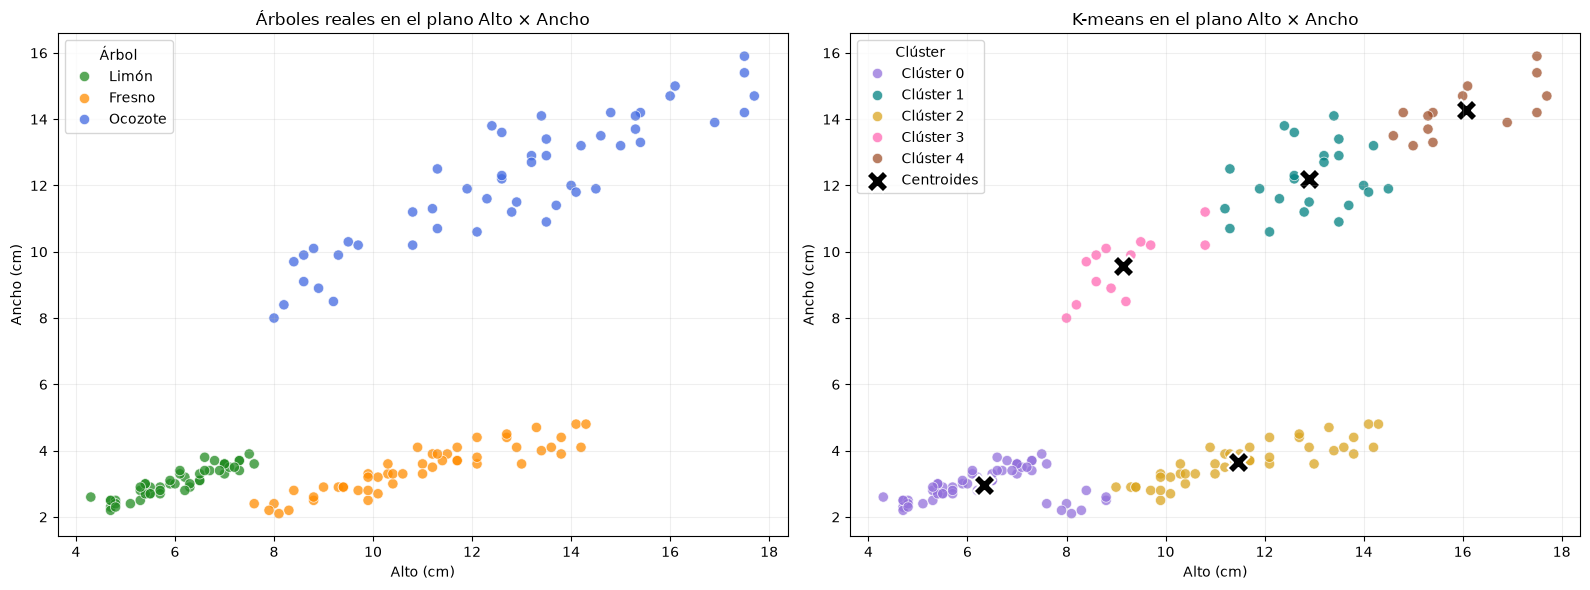

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Árboles reales
sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=arboles_reales,
    hue_order=CLASES,
    palette=COLORES_CLASE,
    alpha=0.75,
    s=55,
    ax=axes[0]
)

axes[0].set_title("Árboles reales en el plano Alto × Ancho")
axes[0].set_xlabel("Alto (cm)")
axes[0].set_ylabel("Ancho (cm)")
axes[0].legend(title="Árbol")
axes[0].grid(alpha=0.2)

# Clústeres obtenidos con K-means
sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=nombres_cluster_kmeans,
    hue_order=orden_cluster_kmeans,
    palette=paleta_cluster_kmeans,
    alpha=0.75,
    s=55,
    ax=axes[1]
)

axes[1].scatter(
    centroides_kmeans_cm[:, 0],
    centroides_kmeans_cm[:, 1],
    marker="X",
    s=250,
    color="black",
    edgecolor="white",
    linewidth=1.5,
    label="Centroides"
)

axes[1].set_title("K-means en el plano Alto × Ancho")
axes[1].set_xlabel("Alto (cm)")
axes[1].set_ylabel("Ancho (cm)")
axes[1].legend(title="Clúster")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Comparación visual con las etiquetas reales

Al comparar ambas gráficas se observa una correspondencia clara entre los grupos obtenidos mediante K-means y los árboles reales. La separación entre hojas anchas y angostas coincide exactamente con la separación entre Ocozote y las otras dos clases.

Las diferencias aparecen en dos zonas:

1. **Ocozote:** sus hojas se reparten en tres clústeres a lo largo de la diagonal. No se trata de un error de asignación entre clases, sino de una división de una misma clase en grupos de distinto tamaño de hoja.
2. **Frontera entre Limón y Fresno:** 8 hojas de Fresno quedaron en el clúster de Limón. Son hojas de Fresno cortas que se encuentran cerca de las de Limón, en la zona donde ambas clases casi se tocan en el alto y tienen anchos similares.

El clustering se ajustó en el espacio de las dos características originales estandarizadas y se graficó en ese mismo espacio expresado en centímetros, sin PCA.

---

# Modelos supervisados

A continuación, se entrenarán y evaluarán modelos de clasificación utilizando las etiquetas reales del corpus de hojas.

La evaluación principal se realizará con las 2 características originales (alto y ancho) mediante validación cruzada estratificada de 10 particiones. Las mismas particiones se utilizarán para todos los algoritmos. Dentro de cada partición externa se buscarán los hiperparámetros con una validación interna de 5 particiones (validación cruzada anidada), seleccionando la configuración con mayor F1-score macro. Cuando el algoritmo lo requiere, el escalado se incluye dentro de un `Pipeline`, por lo que se ajusta únicamente con los datos de entrenamiento de cada partición.

Se reportan accuracy, precision, recall y F1-score con **promedio macro** (las tres clases pesan lo mismo), así como el MAE, cada uno con su promedio y desviación estándar en los 10 folds. La matriz de confusión se construye con las predicciones fuera de muestra de los 10 folds.

**Nota sobre el MAE:** las clases se codificaron como Limón = 0, Fresno = 1 y Ocozote = 2. El MAE trata estos códigos como números, por lo que confundir Limón con Ocozote cuenta como un error de 2, mientras que confundir Limón con Fresno cuenta como un error de 1. Como los tipos de árbol no tienen un orden natural, el MAE depende de esta codificación y no tiene una interpretación ordinal en este problema. Se reporta porque lo solicita el enunciado.

Las búsquedas se ejecutan de forma secuencial (`n_jobs=1`), excepto Random Forest. En el equipo donde se desarrolló el notebook, ejecutar en paralelo modelos tan pequeños resultó más lento que ejecutarlos uno por uno, porque crear procesos cuesta más que entrenar cada modelo. Random Forest es la excepción: cada configuración entrena cientos de árboles, y ahí sí conviene repartir el trabajo entre procesos (`n_jobs=-1`). El valor de `n_jobs` no modifica los resultados, porque todos los modelos usan una semilla fija. Al final de cada validación anidada se imprime su tiempo de ejecución.

Como el corpus solo tiene dos características, las fronteras de decisión se grafican directamente con los modelos evaluados en el plano Alto × Ancho, sin entrenar modelos adicionales ni aplicar PCA.

---

In [33]:
import time

from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from matplotlib.colors import ListedColormap

# Estas serán las mismas particiones externas
# para todos los modelos supervisados
cv_externa = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# Validación interna para buscar hiperparámetros
cv_interna = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

columnas_metricas = [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "mae"
]

print("Validación externa: 10 particiones estratificadas")
print("Validación interna: 5 particiones para buscar hiperparámetros")

Validación externa: 10 particiones estratificadas
Validación interna: 5 particiones para buscar hiperparámetros


Las siguientes funciones se utilizan con los seis clasificadores, para que todos se evalúen exactamente con el mismo procedimiento:

- `criterio_desempate`: cuando varias configuraciones obtienen el mismo F1 macro, elige la más simple según un orden de preferencias definido para cada modelo, en lugar de quedarse con la primera de la lista.
- `evaluar_cv_anidada`: ejecuta la validación cruzada anidada y guarda las métricas de cada fold, la mejor configuración interna y las predicciones fuera de muestra.
- `resumir_metricas`: calcula el promedio y la desviación estándar de las métricas.
- `graficar_matriz_confusion`: dibuja la matriz de confusión de 3 × 3 y lista las hojas mal clasificadas.
- `buscar_configuracion_final`: repite la búsqueda de hiperparámetros con todas las hojas para obtener el modelo final.
- `graficar_frontera`: dibuja las regiones de decisión del modelo final en el plano Alto × Ancho (cm).

In [34]:
def criterio_desempate(preferencias):
    # preferencias: lista de (parámetro, función); un valor mayor indica un modelo más simple
    # si una configuración no usa el parámetro, la función recibe None
    def elegir(cv_results):
        puntajes = np.round(cv_results["mean_test_score"], 6)
        empatados = np.flatnonzero(puntajes == puntajes.max())

        def clave(indice):
            return tuple(
                funcion(cv_results["params"][indice].get(parametro))
                for parametro, funcion in preferencias
            )

        return max(empatados, key=clave)

    return elegir


def numero_empatados(busqueda):
    puntajes = np.round(busqueda.cv_results_["mean_test_score"], 6)
    return int((puntajes == puntajes.max()).sum())


def evaluar_cv_anidada(pipeline, parametros, nombre_modelo, desempate=True, n_jobs=1):
    # Verificar que seguimos utilizando el corpus de hojas
    if X.shape != (150, 2):
        raise ValueError(
            "X ya no contiene el corpus de hojas. "
            "Vuelve a ejecutar la celda donde se carga hojasRazonamiento.csv."
        )

    # Espacio para guardar las predicciones fuera de muestra
    predicciones = np.empty_like(y)
    inicio = time.perf_counter()

    resultados_folds = []
    mejores_parametros_folds = []

    for numero_fold, (indices_train, indices_test) in enumerate(
        cv_externa.split(X, y),
        start=1
    ):
        X_train = X[indices_train]
        X_test = X[indices_test]
        y_train = y[indices_train]
        y_test = y[indices_test]

        # Búsqueda de hiperparámetros usando únicamente el entrenamiento
        busqueda = GridSearchCV(
            estimator=pipeline,
            param_grid=parametros,
            scoring="f1_macro",
            cv=cv_interna,
            n_jobs=n_jobs,
            refit=desempate
        )

        busqueda.fit(X_train, y_train)

        # Predicciones de las hojas reservadas del fold externo
        y_pred = busqueda.predict(X_test)
        predicciones[indices_test] = y_pred

        resultados_folds.append({
            "fold": numero_fold,
            "accuracy": accuracy_score(y_test, y_pred),
            "precision_macro": precision_score(
                y_test, y_pred,
                average="macro",
                zero_division=0
            ),
            "recall_macro": recall_score(
                y_test, y_pred,
                average="macro",
                zero_division=0
            ),
            "f1_macro": f1_score(
                y_test, y_pred,
                average="macro",
                zero_division=0
            ),
            "mae": mean_absolute_error(y_test, y_pred)
        })

        mejores_parametros_folds.append({
            "fold": numero_fold,
            "mejor_f1_interno": busqueda.cv_results_["mean_test_score"][busqueda.best_index_],
            "configuraciones_empatadas": numero_empatados(busqueda),
            **busqueda.best_params_
        })

        print(
            f"{nombre_modelo} — fold {numero_fold}/10 terminado — "
            f"mejor configuración: {busqueda.best_params_}"
        )

    print(f"Tiempo de la validación anidada de {nombre_modelo}: {time.perf_counter() - inicio:.1f} s")

    return (
        pd.DataFrame(resultados_folds),
        pd.DataFrame(mejores_parametros_folds),
        predicciones
    )


def resumir_metricas(resultados_folds_df):
    resumen = (
        resultados_folds_df[columnas_metricas]
        .agg(["mean", "std"])
        .T
        .reset_index()
    )

    resumen.columns = [
        "metrica",
        "promedio",
        "desviacion_estandar"
    ]

    return resumen


def graficar_matriz_confusion(predicciones, nombre_modelo):
    matriz = confusion_matrix(
        y,
        predicciones,
        labels=range(len(CLASES))
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=CLASES
    )

    disp.plot(
        cmap="Blues",
        values_format="d",
        ax=ax,
        colorbar=False
    )

    plt.title(
        f"Matriz de confusión de {nombre_modelo}\n"
        "Predicciones fuera de muestra de 10 folds"
    )
    plt.xlabel("Árbol predicho")
    plt.ylabel("Árbol real")
    plt.show()

    print("Predicciones correctas:", np.trace(matriz))
    print("Predicciones incorrectas:", matriz.sum() - np.trace(matriz))

    # Hojas mal clasificadas fuera de muestra
    errores = datos.loc[predicciones != y, ["ID hoja", columna_clase] + caracteristicas].copy()
    errores["Árbol predicho"] = np.array(CLASES)[predicciones[predicciones != y]]

    if len(errores) > 0:
        print("Hojas mal clasificadas:")
        display(errores.reset_index(drop=True))

    return matriz


def buscar_configuracion_final(pipeline, parametros, desempate=True, n_jobs=1):
    busqueda_final = GridSearchCV(
        estimator=pipeline,
        param_grid=parametros,
        scoring="f1_macro",
        cv=cv_externa,
        n_jobs=n_jobs,
        refit=desempate
    )

    busqueda_final.fit(X, y)

    print("Mejores parámetros finales:")
    print(busqueda_final.best_params_)

    print(
        "F1 macro promedio durante la búsqueda:",
        round(busqueda_final.cv_results_["mean_test_score"][busqueda_final.best_index_], 4)
    )

    print(
        "Configuraciones empatadas con el mejor F1 macro:",
        numero_empatados(busqueda_final)
    )

    resultados_busqueda = pd.DataFrame(busqueda_final.cv_results_)

    columnas_busqueda = [
        c for c in resultados_busqueda.columns if c.startswith("param_")
    ] + ["mean_test_score", "std_test_score", "rank_test_score"]

    top_configuraciones = (
        resultados_busqueda[columnas_busqueda]
        .sort_values("rank_test_score", kind="stable")
        .head(10)
        .reset_index(drop=True)
    )

    display(top_configuraciones.round({
        "mean_test_score": 4,
        "std_test_score": 4
    }))

    return busqueda_final


# Malla en centímetros sobre el plano Alto × Ancho
alto_min, alto_max = X[:, 0].min() - 1, X[:, 0].max() + 1
ancho_min, ancho_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(alto_min, alto_max, 400),
    np.linspace(ancho_min, ancho_max, 400)
)

puntos_malla = np.c_[xx.ravel(), yy.ravel()]

# Regiones con los mismos colores de cada clase
colores_fondo = ListedColormap([COLORES_CLASE[clase] for clase in CLASES])


def graficar_frontera(modelo, nombre_modelo, predicciones_oos=None, ax=None):
    # El Pipeline incluye el escalado, por lo que la malla se pasa en cm
    predicciones_malla = modelo.predict(puntos_malla).reshape(xx.shape)

    mostrar = ax is None
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 7))

    ax.contourf(
        xx,
        yy,
        predicciones_malla,
        levels=[-0.5, 0.5, 1.5, 2.5],
        alpha=0.2,
        cmap=colores_fondo
    )

    ax.contour(
        xx,
        yy,
        predicciones_malla,
        levels=[0.5, 1.5],
        colors="dimgray",
        linewidths=0.8
    )

    # Dibujar las hojas reales
    for clase, nombre in enumerate(CLASES):
        mascara = y == clase

        ax.scatter(
            X[mascara, 0],
            X[mascara, 1],
            color=COLORES_CLASE[nombre],
            label=nombre,
            edgecolor="white",
            linewidth=0.4,
            alpha=0.85,
            s=50
        )

    # Marcar las hojas mal clasificadas en la validación cruzada anidada
    if predicciones_oos is not None and (predicciones_oos != y).any():
        errores = predicciones_oos != y

        ax.scatter(
            X[errores, 0],
            X[errores, 1],
            facecolor="none",
            edgecolor="black",
            linewidth=1.5,
            s=160,
            label="Error fuera de muestra"
        )

    ax.set_title(f"Frontera de decisión de {nombre_modelo}")
    ax.set_xlabel("Alto (cm)")
    ax.set_ylabel("Ancho (cm)")
    ax.legend(title="Árbol", loc="upper left")
    ax.grid(alpha=0.2)

    if mostrar:
        plt.show()

    return predicciones_malla

---

## Modelo 3: K-Nearest Neighbors (k-NN)

k-NN clasifica cada hoja según la clase mayoritaria de sus vecinos más cercanos en el plano Alto × Ancho. Como se basa en distancias, las variables se estandarizan dentro del `Pipeline`.

Se probarán diferentes números de vecinos, métricas de distancia y esquemas de ponderación. La configuración final se seleccionará utilizando el F1-score macro promedio. Si varias configuraciones empatan, se prefiere la ponderación uniforme, después el mayor número de vecinos y finalmente la distancia euclidiana (p = 2). Estas configuraciones producen fronteras más suaves y menos sensibles a una sola hoja, lo cual es conveniente porque las medidas pueden tener errores pequeños.

In [35]:
from sklearn.neighbors import KNeighborsClassifier

# Pipeline: el escalado se ajustará dentro de cada partición
pipeline_knn = Pipeline([
    ("escalado", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# Configuraciones que se probarán
parametros_knn = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["minkowski"],
    "knn__p": [1, 2, 3]
}

numero_configuraciones = (
    len(parametros_knn["knn__n_neighbors"])
    * len(parametros_knn["knn__weights"])
    * len(parametros_knn["knn__p"])
)

print("Número de configuraciones:", numero_configuraciones)
print("Vecinos:", parametros_knn["knn__n_neighbors"])
print("Ponderaciones:", parametros_knn["knn__weights"])
print("Valores de p:", parametros_knn["knn__p"])

# Desempate: ponderación uniforme, más vecinos y distancia euclidiana
desempate_knn = criterio_desempate([
    ("knn__weights", lambda ponderacion: ponderacion == "uniform"),
    ("knn__n_neighbors", lambda vecinos: vecinos),
    ("knn__p", lambda p: p == 2)
])

Número de configuraciones: 54
Vecinos: [1, 3, 5, 7, 9, 11, 15, 21, 31]
Ponderaciones: ['uniform', 'distance']
Valores de p: [1, 2, 3]


In [36]:
resultados_folds_knn_df, mejores_parametros_folds_knn_df, predicciones_knn = evaluar_cv_anidada(
    pipeline_knn,
    parametros_knn,
    "k-NN",
    desempate_knn
)

k-NN — fold 1/10 terminado — mejor configuración: {'knn__metric': 'minkowski', 'knn__n_neighbors': 9, 'knn__p': 1, 'knn__weights': 'uniform'}


k-NN — fold 2/10 terminado — mejor configuración: {'knn__metric': 'minkowski', 'knn__n_neighbors': 5, 'knn__p': 2, 'knn__weights': 'uniform'}


k-NN — fold 3/10 terminado — mejor configuración: {'knn__metric': 'minkowski', 'knn__n_neighbors': 9, 'knn__p': 1, 'knn__weights': 'uniform'}


k-NN — fold 4/10 terminado — mejor configuración: {'knn__metric': 'minkowski', 'knn__n_neighbors': 11, 'knn__p': 1, 'knn__weights': 'uniform'}


k-NN — fold 5/10 terminado — mejor configuración: {'knn__metric': 'minkowski', 'knn__n_neighbors': 11, 'knn__p': 1, 'knn__weights': 'uniform'}


k-NN — fold 6/10 terminado — mejor configuración: {'knn__metric': 'minkowski', 'knn__n_neighbors': 9, 'knn__p': 2, 'knn__weights': 'uniform'}


k-NN — fold 7/10 terminado — mejor configuración: {'knn__metric': 'minkowski', 'knn__n_neighbors': 11, 'knn__p': 1, 'knn__weights': 'uniform'}


k-NN — fold 8/10 terminado — mejor configuración: {'knn__metric': 'minkowski', 'knn__n_neighbors': 5, 'knn__p': 2, 'knn__weights': 'uniform'}


k-NN — fold 9/10 terminado — mejor configuración: {'knn__metric': 'minkowski', 'knn__n_neighbors': 11, 'knn__p': 1, 'knn__weights': 'uniform'}


k-NN — fold 10/10 terminado — mejor configuración: {'knn__metric': 'minkowski', 'knn__n_neighbors': 9, 'knn__p': 1, 'knn__weights': 'uniform'}
Tiempo de la validación anidada de k-NN: 29.9 s


In [37]:
# Mostrar las métricas obtenidas en cada fold
display(
    resultados_folds_knn_df.round(4)
)

resumen_knn = resumir_metricas(resultados_folds_knn_df)

print("Resumen de k-NN con validación cruzada anidada:")
display(
    resumen_knn.round(4)
)

print("Mejor configuración interna en cada fold:")
display(
    mejores_parametros_folds_knn_df.round(4)
)

,fold,accuracy,precision_macro,recall_macro,f1_macro,mae
0,1,1.0000,1.0000,1.0000,1.0000,0.0000
1,2,1.0000,1.0000,1.0000,1.0000,0.0000
2,3,1.0000,1.0000,1.0000,1.0000,0.0000
3,4,1.0000,1.0000,1.0000,1.0000,0.0000
4,5,1.0000,1.0000,1.0000,1.0000,0.0000
5,6,1.0000,1.0000,1.0000,1.0000,0.0000
6,7,0.9333,0.9444,0.9333,0.9327,0.0667
7,8,1.0000,1.0000,1.0000,1.0000,0.0000
8,9,1.0000,1.0000,1.0000,1.0000,0.0000
9,10,1.0000,1.0000,1.0000,1.0000,0.0000


Resumen de k-NN con validación cruzada anidada:


,metrica,promedio,desviacion_estandar
0,accuracy,0.9933,0.0211
1,precision_macro,0.9944,0.0176
2,recall_macro,0.9933,0.0211
3,f1_macro,0.9933,0.0213
4,mae,0.0067,0.0211


Mejor configuración interna en cada fold:


,fold,mejor_f1_interno,configuraciones_empatadas,knn__metric,knn__n_neighbors,knn__p,knn__weights
0,1,1.0,30,minkowski,9,1,uniform
1,2,1.0,19,minkowski,5,2,uniform
2,3,1.0,32,minkowski,9,1,uniform
3,4,1.0,34,minkowski,11,1,uniform
4,5,1.0,37,minkowski,11,1,uniform
5,6,1.0,37,minkowski,9,2,uniform
6,7,1.0,40,minkowski,11,1,uniform
7,8,1.0,25,minkowski,5,2,uniform
8,9,1.0,31,minkowski,11,1,uniform
9,10,1.0,31,minkowski,9,1,uniform


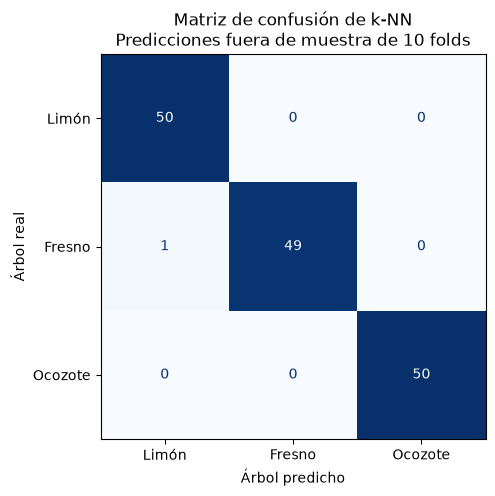

Predicciones correctas: 149
Predicciones incorrectas: 1
Hojas mal clasificadas:


,ID hoja,Árbol,Alto (cm),Ancho (cm),Árbol predicho
0,123,Fresno,7.6,2.4,Limón


In [38]:
# Matriz de confusión con las predicciones fuera de muestra
matriz_confusion_knn = graficar_matriz_confusion(
    predicciones_knn,
    "k-NN"
)

### Matriz de confusión de k-NN

La matriz de confusión se construyó con las predicciones fuera de muestra de los 10 folds externos, por lo que cada hoja se clasificó con un modelo que no la utilizó durante el entrenamiento.

k-NN clasificó correctamente 149 de las 150 hojas. Todas las hojas de Limón y de Ocozote fueron clasificadas correctamente. El único error corresponde a la hoja **123**, de Fresno, con 7.6 cm de alto y 2.4 cm de ancho, que fue clasificada como Limón. Esta hoja se encuentra justo en la zona donde Limón y Fresno se tocan: 7.6 cm es el alto máximo de Limón y el alto mínimo de Fresno, y su ancho también está dentro del rango de Limón. El error ocurrió en el fold 7, por lo que solamente ese fold tiene métricas menores a 1.

Con validación cruzada anidada, k-NN obtuvo un accuracy de **0.9933 ± 0.0211**, precision macro de **0.9944 ± 0.0176**, recall macro de **0.9933 ± 0.0211**, F1 macro de **0.9933 ± 0.0213** y MAE de **0.0067 ± 0.0211**. El MAE coincide con la proporción de errores porque el único error confunde dos clases con códigos consecutivos (Fresno = 1 y Limón = 0).

In [39]:
# Búsqueda de la configuración final utilizando todos los datos
busqueda_final_knn = buscar_configuracion_final(
    pipeline_knn,
    parametros_knn,
    desempate_knn
)

# F1 macro promedio de todas las configuraciones evaluadas
display(
    pd.DataFrame(busqueda_final_knn.cv_results_)
    .pivot_table(
        index="param_knn__n_neighbors",
        columns=["param_knn__p", "param_knn__weights"],
        values="mean_test_score"
    )
    .round(4)
)

# Modelo final ya ajustado con las 150 hojas
mejor_modelo_knn = busqueda_final_knn.best_estimator_

Mejores parámetros finales:
{'knn__metric': 'minkowski', 'knn__n_neighbors': 9, 'knn__p': 1, 'knn__weights': 'uniform'}
F1 macro promedio durante la búsqueda: 1.0
Configuraciones empatadas con el mejor F1 macro: 32


,param_knn__metric,param_knn__n_neighbors,param_knn__p,param_knn__weights,mean_test_score,std_test_score,rank_test_score
0,minkowski,1,1,uniform,1.0,0.0,1
1,minkowski,1,1,distance,1.0,0.0,1
2,minkowski,1,2,uniform,1.0,0.0,1
3,minkowski,1,2,distance,1.0,0.0,1
4,minkowski,1,3,uniform,1.0,0.0,1
5,minkowski,1,3,distance,1.0,0.0,1
6,minkowski,3,1,uniform,1.0,0.0,1
7,minkowski,3,1,distance,1.0,0.0,1
8,minkowski,3,2,uniform,1.0,0.0,1
9,minkowski,3,2,distance,1.0,0.0,1


param_knn__p                  1                2                3        
param_knn__weights     distance uniform distance uniform distance uniform
param_knn__n_neighbors                                                   
1                        1.0000  1.0000   1.0000  1.0000   1.0000  1.0000
3                        1.0000  1.0000   1.0000  1.0000   1.0000  1.0000
5                        1.0000  1.0000   1.0000  1.0000   1.0000  1.0000
7                        1.0000  1.0000   1.0000  1.0000   1.0000  1.0000
9                        1.0000  1.0000   1.0000  0.9933   1.0000  0.9933
11                       1.0000  0.9933   1.0000  0.9933   1.0000  0.9933
15                       1.0000  0.9933   0.9933  0.9865   0.9933  0.9865
21                       0.9933  0.9865   0.9933  0.9731   0.9933  0.9731
31                       0.9933  0.9462   0.9933  0.9529   0.9933  0.9529

### Selección de la configuración final de k-NN

Se evaluaron 54 configuraciones mediante distintas combinaciones del número de vecinos, el esquema de ponderación y la distancia de Minkowski. La selección se realizó utilizando el F1-score macro promedio.

Al buscar con las 150 hojas, **32 configuraciones empataron** con un F1 macro promedio de **1.0**. Todas las configuraciones con 1 a 7 vecinos clasificaron perfectamente las particiones de validación. El desempeño solo disminuye con más vecinos y, sobre todo, con ponderación uniforme: con 31 vecinos y ponderación uniforme el F1 macro baja a 0.9462 con p = 1. Con muchos vecinos, las hojas de Limón y Fresno cercanas a la frontera empiezan a ser superadas en número por vecinos de la otra clase.

Con tantos empates, la selección por F1 no distingue entre configuraciones. Por ello se aplicó el criterio de desempate definido antes de entrenar: ponderación uniforme, mayor número de vecinos y distancia euclidiana. La configuración seleccionada utiliza **9 vecinos**, ponderación **uniforme** y distancia de Minkowski con **p = 1**, equivalente a la distancia Manhattan. Con 9 vecinos, la ponderación uniforme solo obtiene F1 de 1.0 con p = 1, por lo que el criterio no llegó a la preferencia por p = 2.

En la validación anidada se aplicó el mismo criterio dentro de cada fold. Las configuraciones seleccionadas usaron entre 5 y 11 vecinos, siempre con ponderación uniforme. El número de configuraciones empatadas en cada fold fue de entre 19 y 40, lo que confirma que este problema es fácil para k-NN y que el resultado depende poco de los hiperparámetros.

El criterio de desempate tiene un costo pequeño en la evaluación: en el fold 7, la configuración elegida (11 vecinos) clasificó mal la hoja 123, mientras que configuraciones con menos vecinos también empataban en la búsqueda interna. Se conservó el criterio porque se definió antes de ver los resultados de la evaluación externa. Cambiarlo después para obtener un 1.0 sería ajustar el procedimiento con los datos de prueba.

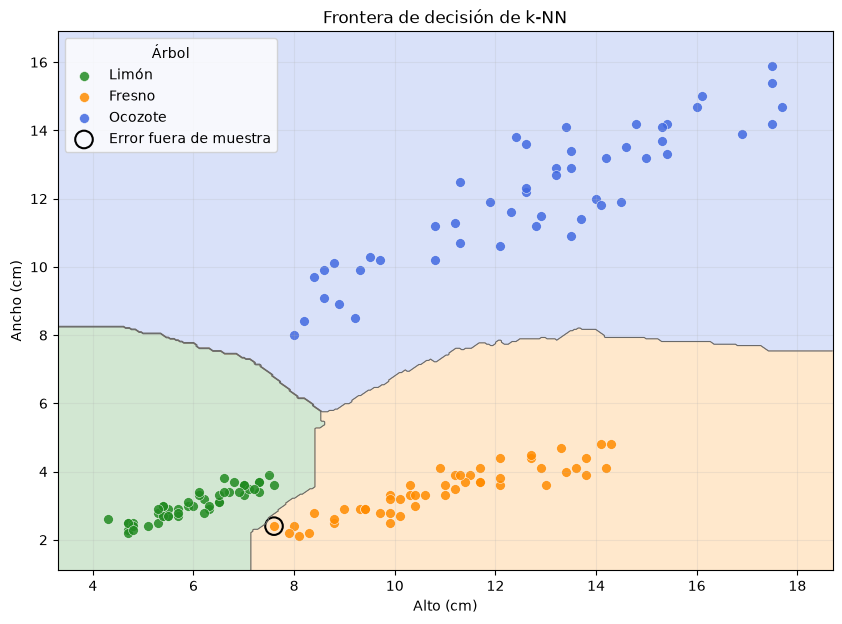

In [40]:
# Frontera de decisión del modelo final de k-NN en el plano Alto × Ancho
malla_knn = graficar_frontera(
    mejor_modelo_knn,
    "k-NN",
    predicciones_knn
)

### Frontera de decisión de k-NN

La frontera de decisión corresponde al modelo final de k-NN, entrenado con las 150 hojas. Como el corpus solo tiene dos características, este es el mismo modelo evaluado y la gráfica lo representa sin aproximaciones. El círculo negro marca la hoja que fue mal clasificada en la validación cruzada anidada.

El plano queda dividido en tres regiones:

- **Ocozote** ocupa toda la parte superior del plano. Su frontera con las otras dos clases se ubica, según la gráfica, en anchos de aproximadamente 6 a 8 cm, en el espacio vacío entre los anchos de Ocozote (8.0 cm o más) y los de Limón y Fresno (4.8 cm o menos).
- **Limón** ocupa la región inferior izquierda.
- **Fresno** ocupa la región inferior derecha.

La frontera entre Limón y Fresno es casi vertical, aproximadamente entre 7 y 8.5 cm de alto. Esto confirma que el alto es la variable que separa a estas dos clases, ya que sus anchos se traslapan. La hoja 123 se ubica sobre esta frontera, en la zona donde ambas clases se tocan.

La frontera tiene una forma irregular, característica de k-NN, porque el algoritmo decide con base en los 9 vecinos más cercanos y no supone ninguna forma para las regiones. En las zonas sin hojas, como la parte superior izquierda o la inferior derecha, la frontera es una extrapolación del modelo y no debe interpretarse como información del corpus.

---

## Modelo 4: Naive Bayes

Se utilizará la variante **Gaussian Naive Bayes**, debido a que el alto y el ancho son variables numéricas continuas. Este modelo estima, para cada clase, una distribución normal por característica y supone que las características son **independientes dentro de cada clase**.

Se probarán distintos valores del parámetro `var_smoothing` y la configuración final se seleccionará utilizando el F1-score macro. Si varios valores empatan, se prefiere el `var_smoothing` más pequeño, porque es el que menos modifica las varianzas estimadas a partir de los datos. La evaluación principal se realizará mediante validación cruzada estratificada anidada, utilizando las mismas 10 particiones externas empleadas en k-NN.

In [41]:
from sklearn.naive_bayes import GaussianNB

# Pipeline para que el escalado se ajuste
# únicamente con los datos de entrenamiento de cada fold
pipeline_nb = Pipeline([
    ("escalado", StandardScaler()),
    ("nb", GaussianNB())
])

# Rango amplio desde 10^-12 hasta 10^0
# para que var_smoothing produzca cambios reales
valores_var_smoothing = np.logspace(
    -12,
    0,
    13
)

parametros_nb = {
    "nb__var_smoothing": valores_var_smoothing
}

# Desempate: menor var_smoothing
desempate_nb = criterio_desempate([
    ("nb__var_smoothing", lambda valor: -valor)
])

print(
    "Número de configuraciones:",
    len(valores_var_smoothing)
)

print("Valores de var_smoothing:")

for valor in valores_var_smoothing:
    print(f"{valor:.0e}")

Número de configuraciones: 13
Valores de var_smoothing:
1e-12
1e-11
1e-10
1e-09
1e-08
1e-07
1e-06
1e-05
1e-04
1e-03
1e-02
1e-01
1e+00


In [42]:
resultados_folds_nb_df, mejores_parametros_folds_nb_df, predicciones_nb = evaluar_cv_anidada(
    pipeline_nb,
    parametros_nb,
    "Naive Bayes",
    desempate_nb
)

Naive Bayes — fold 1/10 terminado — mejor configuración: {'nb__var_smoothing': np.float64(1e-12)}


Naive Bayes — fold 2/10 terminado — mejor configuración: {'nb__var_smoothing': np.float64(0.01)}


Naive Bayes — fold 3/10 terminado — mejor configuración: {'nb__var_smoothing': np.float64(1e-12)}


Naive Bayes — fold 4/10 terminado — mejor configuración: {'nb__var_smoothing': np.float64(1e-12)}


Naive Bayes — fold 5/10 terminado — mejor configuración: {'nb__var_smoothing': np.float64(0.01)}


Naive Bayes — fold 6/10 terminado — mejor configuración: {'nb__var_smoothing': np.float64(1e-12)}


Naive Bayes — fold 7/10 terminado — mejor configuración: {'nb__var_smoothing': np.float64(0.01)}


Naive Bayes — fold 8/10 terminado — mejor configuración: {'nb__var_smoothing': np.float64(1e-12)}


Naive Bayes — fold 9/10 terminado — mejor configuración: {'nb__var_smoothing': np.float64(0.01)}


Naive Bayes — fold 10/10 terminado — mejor configuración: {'nb__var_smoothing': np.float64(0.001)}
Tiempo de la validación anidada de Naive Bayes: 6.3 s


In [43]:
# Mostrar las métricas obtenidas en cada fold
display(
    resultados_folds_nb_df.round(4)
)

resumen_nb = resumir_metricas(resultados_folds_nb_df)

print("Resumen de Naive Bayes con validación cruzada anidada:")
display(
    resumen_nb.round(4)
)

print("Mejor configuración interna en cada fold:")
display(
    mejores_parametros_folds_nb_df
)

,fold,accuracy,precision_macro,recall_macro,f1_macro,mae
0,1,1.0000,1.0000,1.0000,1.0000,0.0000
1,2,0.9333,0.9444,0.9333,0.9327,0.0667
2,3,1.0000,1.0000,1.0000,1.0000,0.0000
3,4,1.0000,1.0000,1.0000,1.0000,0.0000
4,5,1.0000,1.0000,1.0000,1.0000,0.0000
5,6,1.0000,1.0000,1.0000,1.0000,0.0000
6,7,0.9333,0.9444,0.9333,0.9327,0.0667
7,8,1.0000,1.0000,1.0000,1.0000,0.0000
8,9,0.9333,0.9444,0.9333,0.9327,0.0667
9,10,1.0000,1.0000,1.0000,1.0000,0.0000


Resumen de Naive Bayes con validación cruzada anidada:


,metrica,promedio,desviacion_estandar
0,accuracy,0.9800,0.0322
1,precision_macro,0.9833,0.0268
2,recall_macro,0.9800,0.0322
3,f1_macro,0.9798,0.0325
4,mae,0.0200,0.0322


Mejor configuración interna en cada fold:


,fold,mejor_f1_interno,configuraciones_empatadas,nb__var_smoothing
0,1,0.977570,10,1.000000e-12
1,2,0.985000,1,1.000000e-02
2,3,0.985139,10,1.000000e-12
3,4,0.992570,10,1.000000e-12
4,5,0.977709,1,1.000000e-02
5,6,0.977709,10,1.000000e-12
6,7,0.985139,1,1.000000e-02
7,8,0.977709,11,1.000000e-12
8,9,0.985139,1,1.000000e-02
9,10,0.977570,1,1.000000e-03


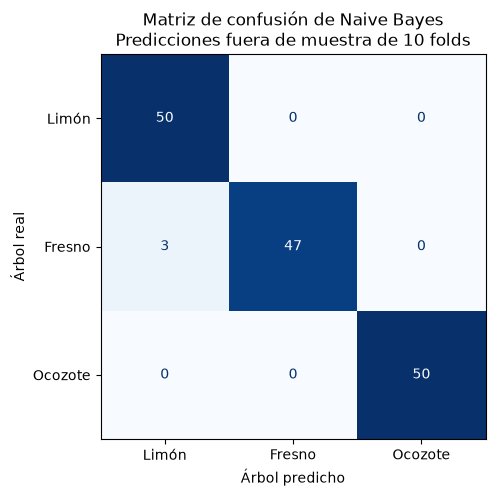

Predicciones correctas: 147
Predicciones incorrectas: 3
Hojas mal clasificadas:


,ID hoja,Árbol,Alto (cm),Ancho (cm),Árbol predicho
0,103,Fresno,8.0,2.4,Limón
1,123,Fresno,7.6,2.4,Limón
2,144,Fresno,7.9,2.2,Limón


In [44]:
# Matriz de confusión con las predicciones fuera de muestra
matriz_confusion_nb = graficar_matriz_confusion(
    predicciones_nb,
    "Naive Bayes"
)

### Matriz de confusión de Naive Bayes

Gaussian Naive Bayes clasificó correctamente 147 de las 150 hojas. Todas las hojas de Limón y de Ocozote fueron clasificadas correctamente. Los tres errores son hojas de Fresno clasificadas como Limón: la hoja **103** (8.0 × 2.4 cm), la **123** (7.6 × 2.4 cm) y la **144** (7.9 × 2.2 cm). Las tres son hojas de Fresno cortas y muy angostas, ubicadas en la zona donde Fresno se acerca a Limón. La hoja 123 también fue el único error de k-NN.

Con validación cruzada anidada, Naive Bayes obtuvo un accuracy de **0.9800 ± 0.0322**, precision macro de **0.9833 ± 0.0268**, recall macro de **0.9800 ± 0.0322**, F1 macro de **0.9798 ± 0.0325** y MAE de **0.0200 ± 0.0322**. Los errores se repartieron en los folds 2, 7 y 9, con un error en cada uno.

In [45]:
# Búsqueda de la configuración final de Naive Bayes
busqueda_final_nb = buscar_configuracion_final(
    pipeline_nb,
    parametros_nb,
    desempate_nb
)

# Modelo final ajustado con todas las hojas
mejor_modelo_nb = busqueda_final_nb.best_estimator_

# F1 macro promedio de todos los valores evaluados
tabla_var_smoothing = pd.DataFrame({
    "var_smoothing": [
        f"{valor:.0e}" for valor in busqueda_final_nb.cv_results_["param_nb__var_smoothing"]
    ],
    "f1_macro_promedio": busqueda_final_nb.cv_results_["mean_test_score"],
    "desviacion_estandar": busqueda_final_nb.cv_results_["std_test_score"]
}).round(4)

display(tabla_var_smoothing)

Mejores parámetros finales:
{'nb__var_smoothing': np.float64(1e-12)}
F1 macro promedio durante la búsqueda: 0.9798
Configuraciones empatadas con el mejor F1 macro: 10


,param_nb__var_smoothing,mean_test_score,std_test_score,rank_test_score
0,1.000000e-12,0.9798,0.0309,1
1,1.000000e-11,0.9798,0.0309,1
2,1.000000e-10,0.9798,0.0309,1
3,1.000000e-09,0.9798,0.0309,1
4,1.000000e-08,0.9798,0.0309,1
5,1.000000e-07,0.9798,0.0309,1
6,1.000000e-06,0.9798,0.0309,1
7,1.000000e-05,0.9798,0.0309,1
8,1.000000e-04,0.9798,0.0309,1
9,1.000000e-03,0.9798,0.0309,1


,var_smoothing,f1_macro_promedio,desviacion_estandar
0,1e-12,0.9798,0.0309
1,1e-11,0.9798,0.0309
2,1e-10,0.9798,0.0309
3,1e-09,0.9798,0.0309
4,1e-08,0.9798,0.0309
5,1e-07,0.9798,0.0309
6,1e-06,0.9798,0.0309
7,1e-05,0.9798,0.0309
8,1e-04,0.9798,0.0309
9,1e-03,0.9798,0.0309


In [46]:
# Parámetros estimados por el modelo final, regresados a centímetros
escalado_nb = mejor_modelo_nb.named_steps["escalado"]
modelo_gnb = mejor_modelo_nb.named_steps["nb"]

medias_nb_cm = escalado_nb.inverse_transform(modelo_gnb.theta_)
desviaciones_nb_cm = np.sqrt(modelo_gnb.var_) * escalado_nb.scale_

parametros_gaussianos_nb = pd.DataFrame(
    np.hstack([medias_nb_cm, desviaciones_nb_cm]),
    index=CLASES,
    columns=[
        "Media Alto (cm)",
        "Media Ancho (cm)",
        "Desv. Alto (cm)",
        "Desv. Ancho (cm)"
    ]
).round(2)

parametros_gaussianos_nb

,Media Alto (cm),Media Ancho (cm),Desv. Alto (cm),Desv. Ancho (cm)
Limón,6.02,3.05,0.88,0.45
Fresno,10.94,3.45,1.83,0.72
Ocozote,12.81,12.10,2.72,1.95


### Selección de la configuración final de Gaussian Naive Bayes

Se probaron 13 valores de `var_smoothing`, comprendidos entre \(10^{-12}\) y \(10^{0}\). Este parámetro suma a todas las varianzas una fracción de la varianza más grande de las características, lo cual mejora la estabilidad numérica y, con valores grandes, hace más anchas las distribuciones gaussianas.

Al buscar con las 150 hojas, los 10 valores entre \(10^{-12}\) y \(10^{-3}\) empataron con un F1 macro promedio de **0.9798**. A partir de \(10^{-2}\) el desempeño disminuye (0.9731 con \(10^{-2}\), 0.9659 con \(10^{-1}\) y 0.9391 con \(10^{0}\)), porque las varianzas infladas hacen que las distribuciones de Limón y Fresno se traslapen más. Siguiendo el criterio de desempate, se seleccionó `var_smoothing` = \(10^{-12}\), que deja las varianzas prácticamente iguales a las estimadas con los datos.

Dentro de la validación anidada, la búsqueda interna eligió \(10^{-12}\) en 5 folds, \(10^{-2}\) en 4 folds y \(10^{-3}\) en 1 fold. En los folds donde ganó \(10^{-2}\), ese valor fue el único con el mejor F1 interno, por lo que su elección no dependió del desempate.

La tabla de parámetros del modelo final muestra las medias y desviaciones estándar que Naive Bayes estimó para cada clase, regresadas a centímetros. Coinciden con las estadísticas descriptivas del análisis exploratorio. Las desviaciones son ligeramente menores porque el modelo divide entre n y no entre n − 1 al calcular la varianza.

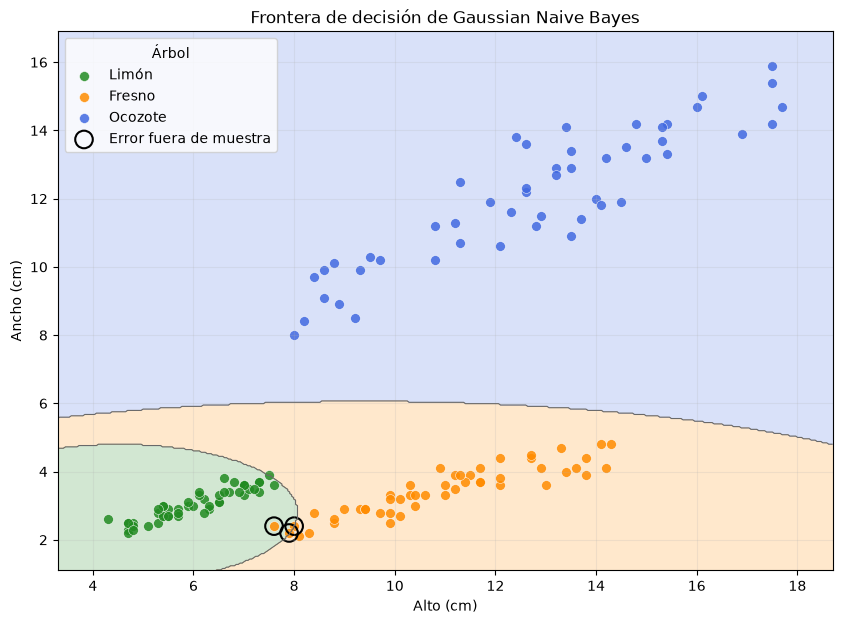

In [47]:
# Frontera de decisión del modelo final de Naive Bayes en el plano Alto × Ancho
malla_nb = graficar_frontera(
    mejor_modelo_nb,
    "Gaussian Naive Bayes",
    predicciones_nb
)

### Interpretación de la frontera de decisión

La frontera de decisión corresponde al modelo final de Gaussian Naive Bayes, entrenado con las 150 hojas. Los círculos negros marcan las tres hojas mal clasificadas en la validación cruzada anidada.

A diferencia de k-NN, la frontera es suave y curva, porque cada región se obtiene comparando distribuciones normales. Cada clase se representa con una elipse alineada con los ejes:

- **Ocozote** ocupa la parte superior del plano. Su frontera con Fresno es una curva que se ubica, según la gráfica, alrededor de los 6 cm de ancho y baja en los extremos del alto.
- **Limón** ocupa una región elíptica en la parte inferior izquierda.
- **Fresno** rodea a la región de Limón por la derecha y por arriba.

Los tres errores se explican por el supuesto de independencia de Naive Bayes. En el análisis exploratorio, el alto y el ancho de Limón presentaron una correlación de 0.92: las hojas de Limón más angostas también son las más cortas. Naive Bayes ignora esta relación y modela el alto y el ancho de Limón por separado. Por ello, la región de Limón se extiende hacia hojas angostas con alto cercano a 8 cm, una combinación que no aparece en las hojas reales de Limón. Las hojas de Fresno cortas y angostas (103, 123 y 144) caen justamente en esa zona.

En las zonas sin hojas, como la esquina inferior derecha o la parte izquierda del plano, la frontera es una extrapolación de las distribuciones normales y no debe interpretarse como información del corpus.

---

## Modelo 5: Support Vector Machine (SVM)

SVM busca la frontera que separa las clases con el mayor margen posible. Con kernels no lineales (RBF, polinomial o sigmoide), la frontera puede ser curva en el plano Alto × Ancho. Como el modelo depende de distancias y productos entre las características, las variables se estandarizan dentro del `Pipeline`. Para las tres clases, `SVC` entrena un clasificador por cada par de clases (esquema uno contra uno).

Se probarán los kernels lineal, RBF, polinomial y sigmoide, variando `C`, `gamma` y, para el kernel polinomial, `degree`. La configuración final se seleccionará utilizando el F1-score macro. Si varias configuraciones empatan, se prefiere el kernel más sencillo (lineal, después RBF, polinomial y sigmoide), luego el menor `C` (mayor margen y más regularización), el menor `gamma` (frontera más suave) y el menor grado.

In [48]:
from sklearn.svm import SVC
from sklearn.model_selection import ParameterGrid

# Pipeline para evitar fugas de información
pipeline_svm = Pipeline([
    ("escalado", StandardScaler()),
    ("svm", SVC())
])

# Configuraciones que se probarán
parametros_svm = [
    # Kernel lineal: gamma no se utiliza
    {
        "svm__kernel": ["linear"],
        "svm__C": [0.1, 1, 10, 100]
    },

    # Kernel radial
    {
        "svm__kernel": ["rbf"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", 0.001, 0.01, 0.1, 1]
    },

    # Kernel polinomial
    {
        "svm__kernel": ["poly"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", 0.01, 0.1],
        "svm__degree": [2, 3]
    },

    # Kernel sigmoide
    {
        "svm__kernel": ["sigmoid"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", 0.001, 0.01, 0.1, 1]
    }
]

# Con 2 variables estandarizadas, gamma="scale" equivale a 1 / (2 · 1) = 0.5
gamma_scale = 1 / (X.shape[1] * 1.0)

# Desempate: kernel más sencillo, menor C, menor gamma y menor grado
orden_kernels = {"linear": 3, "rbf": 2, "poly": 1, "sigmoid": 0}

desempate_svm = criterio_desempate([
    ("svm__kernel", lambda kernel: orden_kernels[kernel]),
    ("svm__C", lambda c: -c),
    ("svm__gamma", lambda gamma: 0 if gamma is None else -(gamma_scale if gamma == "scale" else gamma)),
    ("svm__degree", lambda grado: 0 if grado is None else -grado)
])

numero_configuraciones = len(list(ParameterGrid(parametros_svm)))

print("Número de configuraciones de SVM:", numero_configuraciones)
print("Valor equivalente de gamma='scale':", gamma_scale)

Número de configuraciones de SVM: 68
Valor equivalente de gamma='scale': 0.5


In [49]:
resultados_folds_svm_df, mejores_parametros_folds_svm_df, predicciones_svm = evaluar_cv_anidada(
    pipeline_svm,
    parametros_svm,
    "SVM",
    desempate_svm
)

SVM — fold 1/10 terminado — mejor configuración: {'svm__C': 10, 'svm__kernel': 'linear'}


SVM — fold 2/10 terminado — mejor configuración: {'svm__C': 10, 'svm__kernel': 'linear'}


SVM — fold 3/10 terminado — mejor configuración: {'svm__C': 10, 'svm__kernel': 'linear'}


SVM — fold 4/10 terminado — mejor configuración: {'svm__C': 10, 'svm__kernel': 'linear'}


SVM — fold 5/10 terminado — mejor configuración: {'svm__C': 10, 'svm__kernel': 'linear'}


SVM — fold 6/10 terminado — mejor configuración: {'svm__C': 1, 'svm__kernel': 'linear'}


SVM — fold 7/10 terminado — mejor configuración: {'svm__C': 1, 'svm__kernel': 'linear'}


SVM — fold 8/10 terminado — mejor configuración: {'svm__C': 10, 'svm__kernel': 'linear'}


SVM — fold 9/10 terminado — mejor configuración: {'svm__C': 10, 'svm__kernel': 'linear'}


SVM — fold 10/10 terminado — mejor configuración: {'svm__C': 10, 'svm__kernel': 'linear'}
Tiempo de la validación anidada de SVM: 30.9 s


In [50]:
# Mostrar las métricas obtenidas en cada fold
display(
    resultados_folds_svm_df.round(4)
)

resumen_svm = resumir_metricas(resultados_folds_svm_df)

print("Resumen de SVM con validación cruzada anidada:")
display(
    resumen_svm.round(4)
)

print("Mejor configuración interna en cada fold:")
display(
    mejores_parametros_folds_svm_df.round(4)
)

,fold,accuracy,precision_macro,recall_macro,f1_macro,mae
0,1,1.0000,1.0000,1.0000,1.0000,0.0000
1,2,1.0000,1.0000,1.0000,1.0000,0.0000
2,3,1.0000,1.0000,1.0000,1.0000,0.0000
3,4,1.0000,1.0000,1.0000,1.0000,0.0000
4,5,1.0000,1.0000,1.0000,1.0000,0.0000
5,6,1.0000,1.0000,1.0000,1.0000,0.0000
6,7,0.9333,0.9444,0.9333,0.9327,0.0667
7,8,1.0000,1.0000,1.0000,1.0000,0.0000
8,9,1.0000,1.0000,1.0000,1.0000,0.0000
9,10,1.0000,1.0000,1.0000,1.0000,0.0000


Resumen de SVM con validación cruzada anidada:


,metrica,promedio,desviacion_estandar
0,accuracy,0.9933,0.0211
1,precision_macro,0.9944,0.0176
2,recall_macro,0.9933,0.0211
3,f1_macro,0.9933,0.0213
4,mae,0.0067,0.0211


Mejor configuración interna en cada fold:


,fold,mejor_f1_interno,configuraciones_empatadas,svm__C,svm__kernel
0,1,1.0,14,10,linear
1,2,1.0,10,10,linear
2,3,1.0,14,10,linear
3,4,1.0,15,10,linear
4,5,1.0,15,10,linear
5,6,1.0,18,1,linear
6,7,1.0,19,1,linear
7,8,1.0,11,10,linear
8,9,1.0,15,10,linear
9,10,1.0,12,10,linear


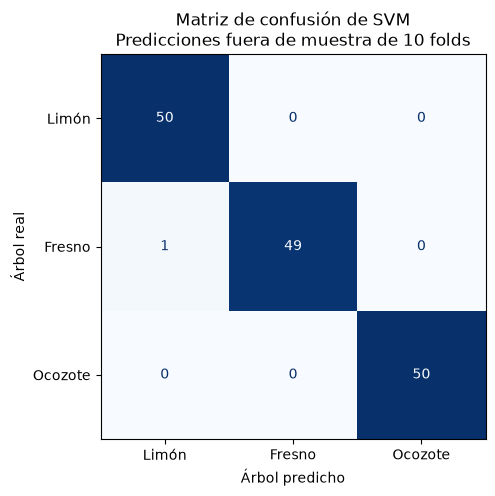

Predicciones correctas: 149
Predicciones incorrectas: 1
Hojas mal clasificadas:


,ID hoja,Árbol,Alto (cm),Ancho (cm),Árbol predicho
0,123,Fresno,7.6,2.4,Limón


In [51]:
# Matriz de confusión con las predicciones fuera de muestra
matriz_confusion_svm = graficar_matriz_confusion(
    predicciones_svm,
    "SVM"
)

### Matriz de confusión de SVM

SVM clasificó correctamente 149 de las 150 hojas. Al igual que k-NN, su único error fue la hoja **123** de Fresno (7.6 × 2.4 cm), clasificada como Limón en el fold 7. Todas las hojas de Limón y de Ocozote se clasificaron correctamente.

Con validación cruzada anidada, SVM obtuvo un accuracy de **0.9933 ± 0.0211**, precision macro de **0.9944 ± 0.0176**, recall macro de **0.9933 ± 0.0211**, F1 macro de **0.9933 ± 0.0213** y MAE de **0.0067 ± 0.0211**. Son los mismos valores de k-NN, porque ambos modelos se equivocaron únicamente en la misma hoja.

In [52]:
# Búsqueda final utilizando todas las hojas
busqueda_final_svm = buscar_configuracion_final(
    pipeline_svm,
    parametros_svm,
    desempate_svm
)

mejor_modelo_svm = busqueda_final_svm.best_estimator_

# Mejor F1 macro alcanzado por cada kernel
resultados_busqueda_svm = pd.DataFrame(busqueda_final_svm.cv_results_)

display(
    resultados_busqueda_svm
    .groupby("param_svm__kernel")["mean_test_score"]
    .agg(["max", "mean", "min"])
    .rename(columns={
        "max": "F1 máximo",
        "mean": "F1 promedio",
        "min": "F1 mínimo"
    })
    .round(4)
)

# F1 macro del kernel lineal para cada valor de C
display(
    resultados_busqueda_svm[resultados_busqueda_svm["param_svm__kernel"] == "linear"]
    [["param_svm__C", "mean_test_score", "std_test_score"]]
    .reset_index(drop=True)
    .round(4)
)

Mejores parámetros finales:
{'svm__C': 10, 'svm__kernel': 'linear'}
F1 macro promedio durante la búsqueda: 1.0
Configuraciones empatadas con el mejor F1 macro: 15


,param_svm__C,param_svm__kernel,param_svm__gamma,param_svm__degree,mean_test_score,std_test_score,rank_test_score
0,10.0,linear,NaN,NaN,1.0,0.0,1
1,100.0,linear,NaN,NaN,1.0,0.0,1
2,1.0,rbf,1,NaN,1.0,0.0,1
3,10.0,rbf,scale,NaN,1.0,0.0,1
4,10.0,rbf,0.1,NaN,1.0,0.0,1
5,10.0,rbf,1,NaN,1.0,0.0,1
6,100.0,rbf,scale,NaN,1.0,0.0,1
7,100.0,rbf,0.01,NaN,1.0,0.0,1
8,100.0,rbf,0.1,NaN,1.0,0.0,1
9,100.0,rbf,1,NaN,1.0,0.0,1


,F1 máximo,F1 promedio,F1 mínimo
param_svm__kernel,,,
linear,1.0,0.9898,0.9659
poly,1.0,0.7249,0.4806
rbf,1.0,0.9608,0.8577
sigmoid,1.0,0.9319,0.8502


,param_svm__C,mean_test_score,std_test_score
0,0.1,0.9659,0.0461
1,1.0,0.9933,0.0202
2,10.0,1.0000,0.0000
3,100.0,1.0000,0.0000


In [53]:
# Vectores de soporte del modelo final
modelo_svc = mejor_modelo_svm.named_steps["svm"]

vectores_soporte = pd.Series(
    modelo_svc.n_support_,
    index=CLASES,
    name="Vectores de soporte"
)

print("Total de vectores de soporte:", modelo_svc.n_support_.sum())
vectores_soporte.to_frame()

Total de vectores de soporte: 10


,Vectores de soporte
Limón,4
Fresno,4
Ocozote,2


### Selección de la configuración final de SVM

Se evaluaron **68 configuraciones** de los kernels lineal, RBF, polinomial y sigmoide, variando `C`, `gamma` y, para el kernel polinomial, `degree`. La selección se realizó mediante el F1 macro promedio.

Al buscar con las 150 hojas, **15 configuraciones empataron** con un F1 macro de **1.0**, y los cuatro kernels alcanzaron ese valor con al menos una configuración. Sin embargo, su estabilidad ante los hiperparámetros fue muy distinta. El F1 promedio sobre todas las configuraciones fue de 0.9898 para el kernel lineal, 0.9608 para RBF, 0.9319 para sigmoide y solamente 0.7249 para el polinomial, cuyo peor resultado fue de 0.4806. Es decir, el kernel lineal funciona bien con casi cualquier valor de `C`, mientras que los kernels no lineales requieren una búsqueda más cuidadosa.

Por el criterio de desempate se eligió el kernel **lineal**. Dentro de este kernel, el F1 macro fue de 0.9659 con `C=0.1`, 0.9933 con `C=1` y 1.0 con `C=10` y `C=100`. Con `C` pequeño, el margen es más amplio y el modelo tolera más errores de entrenamiento, por lo que algunas hojas de Fresno cercanas a Limón quedan del lado incorrecto. La configuración seleccionada fue **kernel lineal con `C=10`**, el menor valor que alcanzó el F1 máximo.

En la validación anidada, la búsqueda interna también eligió el kernel lineal en los 10 folds: `C=10` en 8 folds y `C=1` en los folds 6 y 7. En cada fold empataron entre 10 y 19 configuraciones.

El modelo final utiliza **10 vectores de soporte**: 4 de Limón, 4 de Fresno y 2 de Ocozote. Son las únicas hojas que determinan la posición de las fronteras; el resto podría moverse sin cambiarlas mientras no cruce el margen.

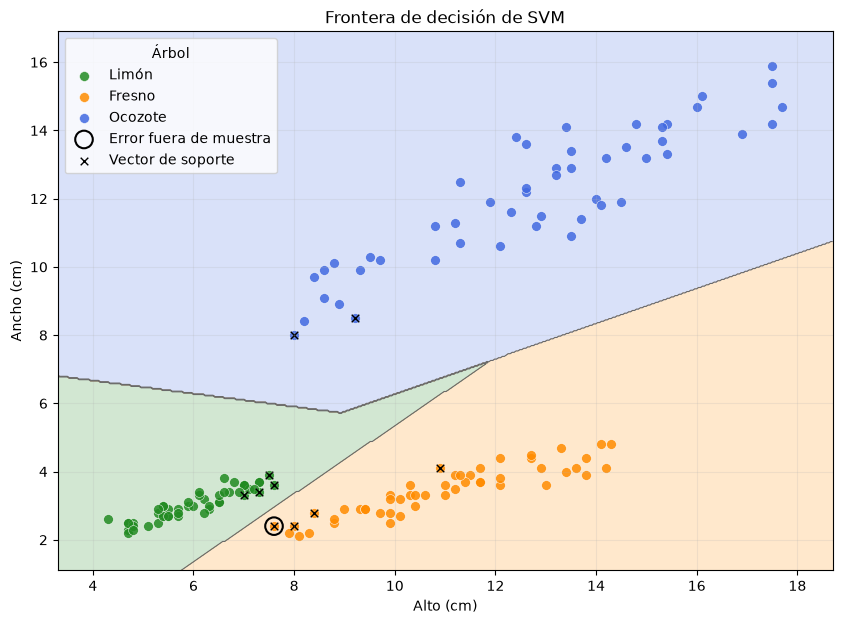

In [54]:
# Frontera de decisión del modelo final de SVM en el plano Alto × Ancho
fig, ax = plt.subplots(figsize=(10, 7))

malla_svm = graficar_frontera(
    mejor_modelo_svm,
    "SVM",
    predicciones_svm,
    ax=ax
)

# Marcar los vectores de soporte
indices_soporte = modelo_svc.support_

ax.scatter(
    X[indices_soporte, 0],
    X[indices_soporte, 1],
    marker="x",
    color="black",
    s=30,
    linewidth=1,
    label="Vector de soporte"
)

ax.legend(title="Árbol", loc="upper left")
plt.show()

### Interpretación del modelo Support Vector Machine

La frontera de decisión corresponde al modelo final de SVM con kernel lineal, entrenado con las 150 hojas. Las cruces marcan los vectores de soporte y el círculo negro marca la hoja mal clasificada en la validación cruzada anidada.

Como el kernel es lineal, cada par de clases se separa con una recta en el espacio estandarizado, que también es una recta en centímetros. Las tres rectas de los clasificadores uno contra uno forman las regiones:

- **Ocozote** ocupa la parte superior. Su frontera se apoya en 2 hojas de Ocozote de la parte inferior de su grupo, con anchos cercanos a 8 cm según la gráfica, que son las más cercanas a las otras clases.
- **Limón** y **Fresno** se separan con una recta diagonal y no vertical, como en k-NN. Esto significa que SVM combina ambas variables: una hoja se clasifica como Fresno cuando es larga en relación con su ancho. Esta frontera coincide con la diferencia de proporciones observada en el análisis exploratorio, donde Fresno tiene hojas más alargadas que Limón.

La mayoría de los vectores de soporte de Limón y Fresno se concentran en la zona donde ambas clases se acercan, aproximadamente entre 7 y 8.5 cm de alto según la gráfica. La hoja 123 es uno de ellos. Al quedar sobre el margen, su clasificación depende de las demás hojas presentes en el entrenamiento, y por eso falló en el fold 7.

La recta entre Limón y Fresno se prolonga hacia la parte inferior y la región de Fresno se extiende por la derecha hasta zonas sin hojas. Esas regiones son extrapolaciones del modelo lineal y no deben interpretarse como información del corpus.

SVM con kernel lineal y k-NN obtuvieron el mismo desempeño, pero con fronteras de distinta naturaleza: k-NN separa Limón y Fresno principalmente por el alto con una frontera irregular, mientras que SVM utiliza una recta que combina el alto y el ancho. Con solo una hoja ambigua en el corpus, la validación cruzada no permite distinguir cuál de las dos fronteras generaliza mejor.

---

## Modelo 6: Árbol de decisión

El árbol de decisión clasifica cada hoja mediante una secuencia de reglas del tipo *"¿el alto es menor o igual a cierto valor?"*. No se utiliza escalado, porque el árbol solo compara cada variable con un umbral y no depende de distancias. Por ello, los umbrales del modelo quedan expresados directamente en centímetros.

Se probarán distintos criterios de impureza, profundidades máximas y números mínimos de hojas para dividir un nodo y para formar una hoja terminal. La configuración final se seleccionará utilizando el F1-score macro. Si varias configuraciones empatan, se prefiere el árbol más sencillo: menor profundidad máxima, mayor número mínimo de muestras por hoja, mayor número mínimo de muestras para dividir y, por último, el criterio Gini.

In [55]:
from sklearn.tree import DecisionTreeClassifier

# Pipeline sin escalado:
# los árboles no dependen de las distancias entre variables
pipeline_arbol = Pipeline([
    (
        "arbol",
        DecisionTreeClassifier(
            random_state=42
        )
    )
])

# Hiperparámetros requeridos por el proyecto
parametros_arbol = {
    "arbol__criterion": [
        "gini",
        "entropy",
        "log_loss"
    ],

    "arbol__max_depth": [
        None,
        2,
        3,
        4,
        5,
        6,
        8,
        10
    ],

    "arbol__min_samples_split": [
        2,
        5,
        10
    ],

    "arbol__min_samples_leaf": [
        1,
        2,
        5,
        10
    ]
}

# Desempate: árbol más sencillo
orden_criterios = {"gini": 2, "entropy": 1, "log_loss": 0}

desempate_arbol = criterio_desempate([
    ("arbol__max_depth", lambda profundidad: -(np.inf if profundidad is None else profundidad)),
    ("arbol__min_samples_leaf", lambda minimo: minimo),
    ("arbol__min_samples_split", lambda minimo: minimo),
    ("arbol__criterion", lambda criterio: orden_criterios[criterio])
])

numero_configuraciones_arbol = len(
    list(ParameterGrid(parametros_arbol))
)

print(
    "Número de configuraciones del árbol:",
    numero_configuraciones_arbol
)

print(
    "Escalado: no se utiliza porque "
    "el árbol trabaja con reglas y umbrales"
)

Número de configuraciones del árbol: 288
Escalado: no se utiliza porque el árbol trabaja con reglas y umbrales


In [56]:
resultados_folds_arbol_df, mejores_parametros_folds_arbol_df, predicciones_arbol = evaluar_cv_anidada(
    pipeline_arbol,
    parametros_arbol,
    "Árbol de decisión",
    desempate_arbol
)

Árbol de decisión — fold 1/10 terminado — mejor configuración: {'arbol__criterion': 'gini', 'arbol__max_depth': 2, 'arbol__min_samples_leaf': 10, 'arbol__min_samples_split': 10}


Árbol de decisión — fold 2/10 terminado — mejor configuración: {'arbol__criterion': 'gini', 'arbol__max_depth': 2, 'arbol__min_samples_leaf': 10, 'arbol__min_samples_split': 10}


Árbol de decisión — fold 3/10 terminado — mejor configuración: {'arbol__criterion': 'gini', 'arbol__max_depth': 3, 'arbol__min_samples_leaf': 2, 'arbol__min_samples_split': 10}


Árbol de decisión — fold 4/10 terminado — mejor configuración: {'arbol__criterion': 'gini', 'arbol__max_depth': 2, 'arbol__min_samples_leaf': 10, 'arbol__min_samples_split': 10}


Árbol de decisión — fold 5/10 terminado — mejor configuración: {'arbol__criterion': 'gini', 'arbol__max_depth': 2, 'arbol__min_samples_leaf': 10, 'arbol__min_samples_split': 10}


Árbol de decisión — fold 6/10 terminado — mejor configuración: {'arbol__criterion': 'gini', 'arbol__max_depth': 3, 'arbol__min_samples_leaf': 2, 'arbol__min_samples_split': 10}


Árbol de decisión — fold 7/10 terminado — mejor configuración: {'arbol__criterion': 'gini', 'arbol__max_depth': 2, 'arbol__min_samples_leaf': 10, 'arbol__min_samples_split': 10}


Árbol de decisión — fold 8/10 terminado — mejor configuración: {'arbol__criterion': 'gini', 'arbol__max_depth': 3, 'arbol__min_samples_leaf': 2, 'arbol__min_samples_split': 10}


Árbol de decisión — fold 9/10 terminado — mejor configuración: {'arbol__criterion': 'gini', 'arbol__max_depth': 2, 'arbol__min_samples_leaf': 10, 'arbol__min_samples_split': 10}


Árbol de decisión — fold 10/10 terminado — mejor configuración: {'arbol__criterion': 'gini', 'arbol__max_depth': 3, 'arbol__min_samples_leaf': 2, 'arbol__min_samples_split': 10}
Tiempo de la validación anidada de Árbol de decisión: 39.7 s


In [57]:
# Mostrar las métricas obtenidas en cada fold
display(
    resultados_folds_arbol_df.round(4)
)

resumen_arbol = resumir_metricas(resultados_folds_arbol_df)

print("Resumen del árbol de decisión con validación cruzada anidada:")
display(
    resumen_arbol.round(4)
)

print("Mejor configuración interna en cada fold:")
display(
    mejores_parametros_folds_arbol_df.round(4)
)

,fold,accuracy,precision_macro,recall_macro,f1_macro,mae
0,1,1.0000,1.0000,1.0000,1.0000,0.0000
1,2,1.0000,1.0000,1.0000,1.0000,0.0000
2,3,1.0000,1.0000,1.0000,1.0000,0.0000
3,4,0.9333,0.9444,0.9333,0.9327,0.0667
4,5,1.0000,1.0000,1.0000,1.0000,0.0000
5,6,1.0000,1.0000,1.0000,1.0000,0.0000
6,7,0.9333,0.9444,0.9333,0.9327,0.0667
7,8,1.0000,1.0000,1.0000,1.0000,0.0000
8,9,0.9333,0.9444,0.9333,0.9327,0.0667
9,10,1.0000,1.0000,1.0000,1.0000,0.0000


Resumen del árbol de decisión con validación cruzada anidada:


,metrica,promedio,desviacion_estandar
0,accuracy,0.9800,0.0322
1,precision_macro,0.9833,0.0268
2,recall_macro,0.9800,0.0322
3,f1_macro,0.9798,0.0325
4,mae,0.0200,0.0322


Mejor configuración interna en cada fold:


,fold,mejor_f1_interno,configuraciones_empatadas,arbol__criterion,arbol__max_depth,arbol__min_samples_leaf,arbol__min_samples_split
0,1,0.9851,288,gini,2,10,10
1,2,0.9776,288,gini,2,10,10
2,3,0.9851,126,gini,3,2,10
3,4,0.9851,288,gini,2,10,10
4,5,0.9851,288,gini,2,10,10
5,6,0.9851,126,gini,3,2,10
6,7,1.0000,288,gini,2,10,10
7,8,0.9851,126,gini,3,2,10
8,9,0.9851,288,gini,2,10,10
9,10,0.9851,126,gini,3,2,10


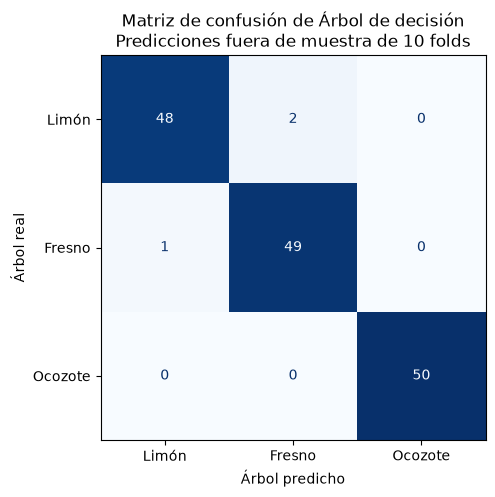

Predicciones correctas: 147
Predicciones incorrectas: 3
Hojas mal clasificadas:


,ID hoja,Árbol,Alto (cm),Ancho (cm),Árbol predicho
0,10,Limón,7.6,3.6,Fresno
1,37,Limón,7.5,3.9,Fresno
2,123,Fresno,7.6,2.4,Limón


In [58]:
# Matriz de confusión con las predicciones fuera de muestra
matriz_confusion_arbol = graficar_matriz_confusion(
    predicciones_arbol,
    "Árbol de decisión"
)

### Matriz de confusión del árbol de decisión

El árbol de decisión clasificó correctamente 147 de las 150 hojas. Todas las hojas de Ocozote fueron clasificadas correctamente. Los errores se concentran en la frontera entre Limón y Fresno, en los dos sentidos:

- Las hojas **10** (7.6 × 3.6 cm) y **37** (7.5 × 3.9 cm), de Limón, fueron clasificadas como Fresno. Están entre las hojas de Limón más largas (el alto máximo de Limón es 7.6 cm).
- La hoja **123** (7.6 × 2.4 cm), de Fresno, fue clasificada como Limón, igual que en los modelos anteriores.

El árbol separa Limón y Fresno con un umbral sobre el alto, que se ubica entre las hojas de entrenamiento más cercanas de cada clase. Por ello, el umbral cambia ligeramente según qué hojas queden en el entrenamiento de cada fold, y las hojas con alto de 7.5 a 7.6 cm quedan de un lado o del otro.

Con validación cruzada anidada, el árbol de decisión obtuvo un accuracy de **0.9800 ± 0.0322**, precision macro de **0.9833 ± 0.0268**, recall macro de **0.9800 ± 0.0322**, F1 macro de **0.9798 ± 0.0325** y MAE de **0.0200 ± 0.0322**, con un error en cada uno de los folds 4, 7 y 9.

In [59]:
# Búsqueda final de hiperparámetros con toda la base
busqueda_final_arbol = buscar_configuracion_final(
    pipeline_arbol,
    parametros_arbol,
    desempate_arbol
)

mejor_modelo_arbol = busqueda_final_arbol.best_estimator_

# Mejor F1 macro según la profundidad máxima
resultados_busqueda_arbol = pd.DataFrame(busqueda_final_arbol.cv_results_)

display(
    resultados_busqueda_arbol
    .assign(profundidad=resultados_busqueda_arbol["param_arbol__max_depth"].map(
        lambda valor: "Sin límite" if valor is None or pd.isna(valor) else str(int(valor))
    ))
    .groupby("profundidad", sort=False)["mean_test_score"]
    .agg(["max", "mean"])
    .rename(columns={"max": "F1 máximo", "mean": "F1 promedio"})
    .round(4)
)

Mejores parámetros finales:
{'arbol__criterion': 'gini', 'arbol__max_depth': 3, 'arbol__min_samples_leaf': 2, 'arbol__min_samples_split': 10}
F1 macro promedio durante la búsqueda: 0.9865
Configuraciones empatadas con el mejor F1 macro: 126


,param_arbol__criterion,param_arbol__max_depth,param_arbol__min_samples_leaf,param_arbol__min_samples_split,mean_test_score,std_test_score,rank_test_score
0,gini,None,1,2,0.9865,0.0269,1
1,gini,None,1,5,0.9865,0.0269,1
2,gini,None,1,10,0.9865,0.0269,1
3,gini,None,2,2,0.9865,0.0269,1
4,gini,None,2,5,0.9865,0.0269,1
5,gini,None,2,10,0.9865,0.0269,1
6,gini,3,1,2,0.9865,0.0269,1
7,gini,3,1,5,0.9865,0.0269,1
8,gini,3,1,10,0.9865,0.0269,1
9,gini,3,2,2,0.9865,0.0269,1


,F1 máximo,F1 promedio
profundidad,,
Sin límite,0.9865,0.9832
2,0.9798,0.9798
3,0.9865,0.9832
4,0.9865,0.9832
5,0.9865,0.9832
6,0.9865,0.9832
8,0.9865,0.9832
10,0.9865,0.9832


Profundidad real del árbol: 3
Número de hojas terminales: 4

Reglas del árbol (umbrales en cm):
|--- Ancho (cm) <= 6.40
|   |--- Alto (cm) <= 7.55
|   |   |--- class: Limón
|   |--- Alto (cm) >  7.55
|   |   |--- Alto (cm) <= 7.75
|   |   |   |--- class: Limón
|   |   |--- Alto (cm) >  7.75
|   |   |   |--- class: Fresno
|--- Ancho (cm) >  6.40
|   |--- class: Ocozote

Contenido de cada hoja terminal:


Árbol,Limón,Fresno,Ocozote
hoja_terminal,,,
2,49,0,0
4,1,1,0
5,0,49,0
6,0,0,50


,ID hoja,Árbol,Alto (cm),Ancho (cm)
9,10,Limón,7.6,3.6
122,123,Fresno,7.6,2.4


,Importancia
Alto (cm),0.4949
Ancho (cm),0.5051


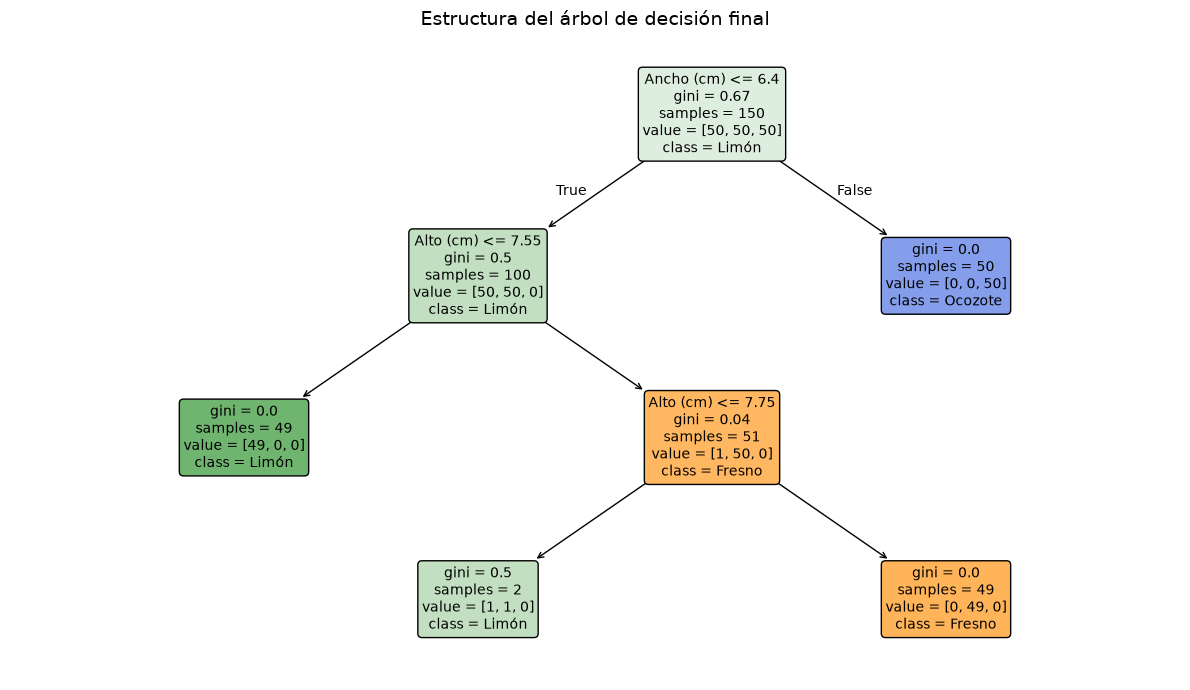

In [60]:
from sklearn.tree import plot_tree, export_text

# Extraer el clasificador del Pipeline
arbol_final = mejor_modelo_arbol.named_steps[
    "arbol"
]

print(
    "Profundidad real del árbol:",
    arbol_final.get_depth()
)

print(
    "Número de hojas terminales:",
    arbol_final.get_n_leaves()
)

print()
print("Reglas del árbol (umbrales en cm):")
print(export_text(arbol_final, feature_names=caracteristicas, class_names=CLASES))

# Hojas del corpus que caen en cada hoja terminal del árbol
hoja_terminal = arbol_final.apply(X)
contenido_hojas = (
    datos.assign(hoja_terminal=hoja_terminal)
    .groupby("hoja_terminal")[columna_clase]
    .value_counts()
    .unstack(fill_value=0)
    .reindex(columns=CLASES, fill_value=0)
)

print("Contenido de cada hoja terminal:")
display(contenido_hojas)

# Hojas del corpus en la hoja terminal más pequeña
hoja_mas_pequena = contenido_hojas.sum(axis=1).idxmin()
display(datos.loc[hoja_terminal == hoja_mas_pequena])

importancias_arbol = pd.Series(
    arbol_final.feature_importances_,
    index=caracteristicas,
    name="Importancia"
).round(4)

display(importancias_arbol.to_frame())

plt.figure(
    figsize=(12, 7)
)

nodos = plot_tree(
    arbol_final,
    feature_names=caracteristicas,
    class_names=CLASES,
    filled=True,
    rounded=True,
    proportion=False,
    precision=2,
    fontsize=10
)

# Colorear cada nodo con el color de su clase mayoritaria
# (más intenso cuanto más puro es el nodo)
from matplotlib.colors import to_rgba

# plot_tree también devuelve las etiquetas True/False de las flechas, que no tienen recuadro
recuadros = [nodo for nodo in nodos if nodo.get_bbox_patch() is not None]
assert len(recuadros) == arbol_final.tree_.node_count

for indice_nodo, nodo in enumerate(recuadros):
    conteos = arbol_final.tree_.value[indice_nodo][0]
    proporciones = conteos / conteos.sum()
    clase_mayoritaria = CLASES[np.argmax(proporciones)]
    pureza = 1 - arbol_final.tree_.impurity[indice_nodo] / (1 - 1 / len(CLASES))

    # Mezcla opaca con blanco para que las flechas no se vean a través del recuadro
    intensidad = 0.15 + 0.5 * pureza
    color_nodo = np.array(to_rgba(COLORES_CLASE[clase_mayoritaria]))
    color_nodo[:3] = 1 - intensidad * (1 - color_nodo[:3])

    nodo.get_bbox_patch().set_facecolor(color_nodo)

plt.title(
    "Estructura del árbol de decisión final",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Selección de la configuración final del árbol de decisión

Se probaron **288 configuraciones**, variando el criterio de impureza, la profundidad máxima, el número mínimo de muestras necesarias para dividir un nodo y el número mínimo de muestras permitido en una hoja terminal. La configuración se seleccionó mediante F1 macro.

Al buscar con las 150 hojas, **126 configuraciones empataron** con un F1 macro de **0.9865**. Todas las profundidades a partir de 3 (y la profundidad sin límite) alcanzaron ese valor, mientras que la profundidad 2 llegó como máximo a 0.9798. Aplicando el criterio de desempate, se eligió la configuración más sencilla entre las empatadas: criterio **Gini**, profundidad máxima de **3**, al menos **2** muestras por hoja terminal y al menos **10** muestras para dividir un nodo.

En la validación anidada, la búsqueda interna eligió profundidad 2 en 6 folds y profundidad 3 en 4 folds. En los 6 folds con profundidad 2, las 288 configuraciones empataron, es decir, ningún hiperparámetro cambió el resultado de la validación interna.

El árbol final tiene profundidad 3 y 4 hojas terminales:

1. La raíz separa por **Ancho ≤ 6.4 cm**. Las 50 hojas con un ancho mayor son todas de Ocozote. El umbral queda a la mitad del espacio vacío entre el ancho máximo de Limón y Fresno (4.8 cm) y el ancho mínimo de Ocozote (8.0 cm).
2. Entre las hojas angostas, **Alto ≤ 7.55 cm** forma una hoja terminal con 49 hojas de Limón.
3. Las hojas angostas con alto mayor a 7.75 cm forman una hoja terminal con 49 hojas de Fresno.
4. La hoja terminal restante, con alto entre 7.55 y 7.75 cm, contiene solamente 2 hojas: la **10** (Limón) y la **123** (Fresno), ambas con 7.6 cm de alto. Como hay empate, el árbol asigna la clase con el código menor, que es Limón. Esta decisión depende del orden en que se codificaron las clases y no de los datos.

En la práctica, el árbol equivale a una regla sencilla: una hoja angosta es Limón si su alto es menor o igual a 7.75 cm y Fresno en caso contrario. La tercera división solo existe porque los umbrales 7.55 y 7.75 producen la misma impureza en el segundo nivel y el algoritmo eligió el primero.

La importancia de las características fue de 0.5051 para el ancho y 0.4949 para el alto. El ancho se utiliza una sola vez, para separar a Ocozote; el alto se utiliza para separar a Limón de Fresno.

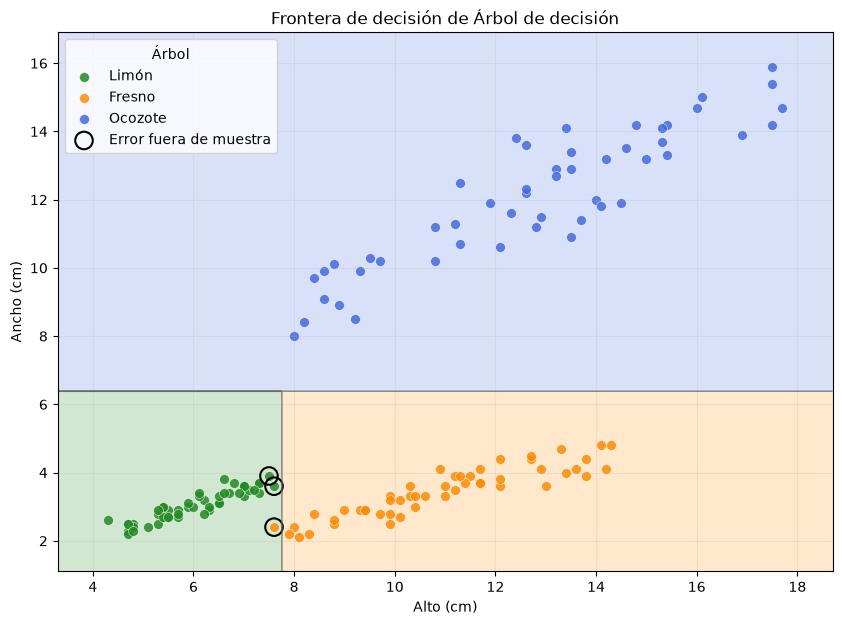

In [61]:
# Frontera de decisión del modelo final del árbol en el plano Alto × Ancho
malla_arbol = graficar_frontera(
    mejor_modelo_arbol,
    "Árbol de decisión",
    predicciones_arbol
)

### Interpretación del árbol de decisión

La frontera de decisión corresponde al árbol final, entrenado con las 150 hojas. Los círculos negros marcan las tres hojas mal clasificadas en la validación cruzada anidada.

Como cada regla compara una sola variable con un umbral, las fronteras son líneas rectas paralelas a los ejes y las regiones son rectángulos:

- **Ocozote** ocupa toda la franja con ancho mayor a 6.4 cm, sin importar el alto.
- **Limón** ocupa el rectángulo con ancho de hasta 6.4 cm y alto de hasta 7.75 cm.
- **Fresno** ocupa el rectángulo con ancho de hasta 6.4 cm y alto mayor a 7.75 cm.

La frontera entre Limón y Fresno es vertical: el árbol ignora el ancho en esta decisión, a diferencia de SVM, que utilizó una recta diagonal. Las tres hojas mal clasificadas en la validación anidada están pegadas a esta línea vertical.

El árbol es el modelo más fácil de interpretar de los evaluados hasta ahora: sus dos reglas principales, en centímetros, coinciden con las conclusiones del análisis exploratorio. Su desventaja es que las fronteras rectangulares dependen de pocos umbrales, y esos umbrales cambian con pequeñas variaciones en los datos de entrenamiento, como se observó en los folds 4, 7 y 9.

---

## Modelo 7: Random Forest

Random Forest combina muchos árboles de decisión. Cada árbol se entrena con una muestra bootstrap de las hojas y, en cada división, solo considera un subconjunto aleatorio de las características; la predicción final es el voto de todos los árboles. Al promediar árboles distintos, las fronteras se vuelven más estables que las de un solo árbol. Igual que en el árbol de decisión, no se utiliza escalado.

Se probarán distintos números de árboles, profundidades máximas, números de características por división y criterios de impureza. La configuración final se seleccionará utilizando el F1-score macro. Si varias configuraciones empatan, se prefiere el bosque más sencillo: menos árboles, menor profundidad máxima, menos características por división y, por último, el criterio Gini.

In [62]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest no necesita estandarización
pipeline_bosque = Pipeline([
    (
        "bosque",
        RandomForestClassifier(
            bootstrap=True,
            random_state=42,
            n_jobs=1
        )
    )
])

# Hiperparámetros requeridos por el proyecto
parametros_bosque = {
    # Número de árboles
    "bosque__n_estimators": [
        100,
        300,
        500
    ],

    # Profundidad de los árboles
    "bosque__max_depth": [
        None,
        5,
        10
    ],

    # Características consideradas en cada división
    "bosque__max_features": [
        "sqrt",
        "log2",
        None
    ],

    # Criterio de calidad de las divisiones
    "bosque__criterion": [
        "gini",
        "entropy"
    ]
}

# Con 2 características, sqrt y log2 consideran 1 característica por división
print(
    "Características por división — sqrt:", max(1, int(np.sqrt(X.shape[1]))),
    "| log2:", max(1, int(np.log2(X.shape[1]))),
    "| None:", X.shape[1]
)

# Desempate: bosque más sencillo
orden_max_features = {"sqrt": 2, "log2": 1, None: 0}

desempate_bosque = criterio_desempate([
    ("bosque__n_estimators", lambda arboles: -arboles),
    ("bosque__max_depth", lambda profundidad: -(np.inf if profundidad is None else profundidad)),
    ("bosque__max_features", lambda caracteristicas_division: orden_max_features[caracteristicas_division]),
    ("bosque__criterion", lambda criterio: criterio == "gini")
])

numero_configuraciones_bosque = len(
    list(ParameterGrid(parametros_bosque))
)

print(
    "Número de configuraciones de Random Forest:",
    numero_configuraciones_bosque
)

print(
    "Escalado: no se utiliza porque "
    "Random Forest trabaja con reglas y umbrales"
)

Características por división — sqrt: 1 | log2: 1 | None: 2
Número de configuraciones de Random Forest: 54
Escalado: no se utiliza porque Random Forest trabaja con reglas y umbrales


In [63]:
resultados_folds_bosque_df, mejores_parametros_folds_bosque_df, predicciones_bosque = evaluar_cv_anidada(
    pipeline_bosque,
    parametros_bosque,
    "Random Forest",
    desempate_bosque,
    n_jobs=-1
)

Random Forest — fold 1/10 terminado — mejor configuración: {'bosque__criterion': 'gini', 'bosque__max_depth': 5, 'bosque__max_features': 'sqrt', 'bosque__n_estimators': 100}


Random Forest — fold 2/10 terminado — mejor configuración: {'bosque__criterion': 'gini', 'bosque__max_depth': 5, 'bosque__max_features': 'sqrt', 'bosque__n_estimators': 100}


Random Forest — fold 3/10 terminado — mejor configuración: {'bosque__criterion': 'gini', 'bosque__max_depth': 5, 'bosque__max_features': 'sqrt', 'bosque__n_estimators': 100}


Random Forest — fold 4/10 terminado — mejor configuración: {'bosque__criterion': 'gini', 'bosque__max_depth': 5, 'bosque__max_features': 'sqrt', 'bosque__n_estimators': 100}


Random Forest — fold 5/10 terminado — mejor configuración: {'bosque__criterion': 'gini', 'bosque__max_depth': 5, 'bosque__max_features': 'sqrt', 'bosque__n_estimators': 100}


Random Forest — fold 6/10 terminado — mejor configuración: {'bosque__criterion': 'gini', 'bosque__max_depth': 5, 'bosque__max_features': 'sqrt', 'bosque__n_estimators': 100}


Random Forest — fold 7/10 terminado — mejor configuración: {'bosque__criterion': 'gini', 'bosque__max_depth': 5, 'bosque__max_features': 'sqrt', 'bosque__n_estimators': 100}


Random Forest — fold 8/10 terminado — mejor configuración: {'bosque__criterion': 'gini', 'bosque__max_depth': 5, 'bosque__max_features': 'sqrt', 'bosque__n_estimators': 100}


Random Forest — fold 9/10 terminado — mejor configuración: {'bosque__criterion': 'gini', 'bosque__max_depth': 5, 'bosque__max_features': 'sqrt', 'bosque__n_estimators': 100}


Random Forest — fold 10/10 terminado — mejor configuración: {'bosque__criterion': 'gini', 'bosque__max_depth': 5, 'bosque__max_features': 'sqrt', 'bosque__n_estimators': 100}
Tiempo de la validación anidada de Random Forest: 115.8 s


In [64]:
# Mostrar las métricas obtenidas en cada fold
display(
    resultados_folds_bosque_df.round(4)
)

resumen_bosque = resumir_metricas(resultados_folds_bosque_df)

print("Resumen de Random Forest con validación cruzada anidada:")
display(
    resumen_bosque.round(4)
)

print("Mejor configuración interna en cada fold:")
display(
    mejores_parametros_folds_bosque_df.round(4)
)

,fold,accuracy,precision_macro,recall_macro,f1_macro,mae
0,1,1.0000,1.0000,1.0000,1.0000,0.0000
1,2,1.0000,1.0000,1.0000,1.0000,0.0000
2,3,1.0000,1.0000,1.0000,1.0000,0.0000
3,4,0.9333,0.9444,0.9333,0.9327,0.0667
4,5,1.0000,1.0000,1.0000,1.0000,0.0000
5,6,1.0000,1.0000,1.0000,1.0000,0.0000
6,7,0.9333,0.9444,0.9333,0.9327,0.0667
7,8,1.0000,1.0000,1.0000,1.0000,0.0000
8,9,1.0000,1.0000,1.0000,1.0000,0.0000
9,10,1.0000,1.0000,1.0000,1.0000,0.0000


Resumen de Random Forest con validación cruzada anidada:


,metrica,promedio,desviacion_estandar
0,accuracy,0.9867,0.0281
1,precision_macro,0.9889,0.0234
2,recall_macro,0.9867,0.0281
3,f1_macro,0.9865,0.0284
4,mae,0.0133,0.0281


Mejor configuración interna en cada fold:


,fold,mejor_f1_interno,configuraciones_empatadas,bosque__criterion,bosque__max_depth,bosque__max_features,bosque__n_estimators
0,1,0.9851,54,gini,5,sqrt,100
1,2,0.9776,54,gini,5,sqrt,100
2,3,0.9851,54,gini,5,sqrt,100
3,4,0.9851,54,gini,5,sqrt,100
4,5,0.9851,54,gini,5,sqrt,100
5,6,0.9851,54,gini,5,sqrt,100
6,7,1.0000,54,gini,5,sqrt,100
7,8,0.9851,54,gini,5,sqrt,100
8,9,0.9851,54,gini,5,sqrt,100
9,10,0.9851,54,gini,5,sqrt,100


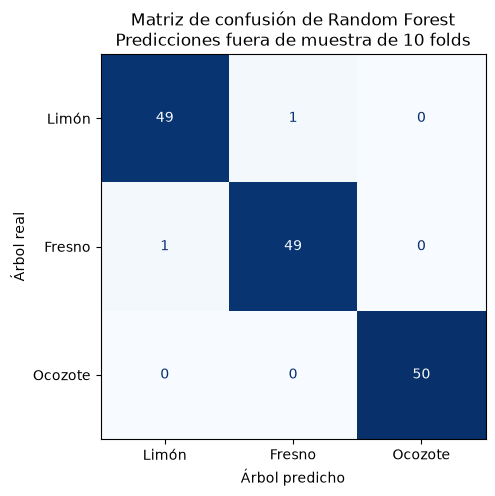

Predicciones correctas: 148
Predicciones incorrectas: 2
Hojas mal clasificadas:


,ID hoja,Árbol,Alto (cm),Ancho (cm),Árbol predicho
0,10,Limón,7.6,3.6,Fresno
1,123,Fresno,7.6,2.4,Limón


In [65]:
# Matriz de confusión con las predicciones fuera de muestra
matriz_confusion_bosque = graficar_matriz_confusion(
    predicciones_bosque,
    "Random Forest"
)

### Matriz de confusión de Random Forest

Random Forest clasificó correctamente 148 de las 150 hojas. Todas las hojas de Ocozote fueron clasificadas correctamente. Los dos errores son las dos hojas que tienen exactamente 7.6 cm de alto, una de cada clase:

- La hoja **10** de Limón (7.6 × 3.6 cm), clasificada como Fresno en el fold 4.
- La hoja **123** de Fresno (7.6 × 2.4 cm), clasificada como Limón en el fold 7.

Comparado con el árbol de decisión individual, Random Forest corrigió la hoja 37 (7.5 × 3.9 cm), que el árbol clasificaba como Fresno.

Con validación cruzada anidada, Random Forest obtuvo un accuracy de **0.9867 ± 0.0281**, precision macro de **0.9889 ± 0.0234**, recall macro de **0.9867 ± 0.0281**, F1 macro de **0.9865 ± 0.0284** y MAE de **0.0133 ± 0.0281**.

In [66]:
# Modelo final de Random Forest
busqueda_final_bosque = buscar_configuracion_final(
    pipeline_bosque,
    parametros_bosque,
    desempate_bosque,
    n_jobs=-1
)

mejor_modelo_bosque = busqueda_final_bosque.best_estimator_

# F1 macro según cada hiperparámetro
resultados_busqueda_bosque = pd.DataFrame(busqueda_final_bosque.cv_results_)

for parametro in [
    "param_bosque__n_estimators",
    "param_bosque__max_depth",
    "param_bosque__max_features",
    "param_bosque__criterion"
]:
    display(
        resultados_busqueda_bosque
        .assign(valor=resultados_busqueda_bosque[parametro].map(
            lambda valor: "None" if valor is None or (isinstance(valor, float) and np.isnan(valor)) else str(valor)
        ))
        .groupby("valor", sort=False)["mean_test_score"]
        .agg(["max", "mean", "min"])
        .rename(columns={"max": "F1 máximo", "mean": "F1 promedio", "min": "F1 mínimo"})
        .rename_axis(parametro.replace("param_bosque__", ""))
        .round(4)
    )

Mejores parámetros finales:
{'bosque__criterion': 'gini', 'bosque__max_depth': 5, 'bosque__max_features': 'sqrt', 'bosque__n_estimators': 100}
F1 macro promedio durante la búsqueda: 0.9865
Configuraciones empatadas con el mejor F1 macro: 54


,param_bosque__criterion,param_bosque__max_depth,param_bosque__max_features,param_bosque__n_estimators,mean_test_score,std_test_score,rank_test_score
0,gini,None,sqrt,100,0.9865,0.0269,1
1,gini,None,sqrt,300,0.9865,0.0269,1
2,gini,None,sqrt,500,0.9865,0.0269,1
3,gini,None,log2,100,0.9865,0.0269,1
4,gini,None,log2,300,0.9865,0.0269,1
5,gini,None,log2,500,0.9865,0.0269,1
6,gini,None,NaN,100,0.9865,0.0269,1
7,gini,None,NaN,300,0.9865,0.0269,1
8,gini,None,NaN,500,0.9865,0.0269,1
9,gini,5,sqrt,100,0.9865,0.0269,1


,F1 máximo,F1 promedio,F1 mínimo
n_estimators,,,
100,0.9865,0.9865,0.9865
300,0.9865,0.9865,0.9865
500,0.9865,0.9865,0.9865


,F1 máximo,F1 promedio,F1 mínimo
max_depth,,,
None,0.9865,0.9865,0.9865
5,0.9865,0.9865,0.9865
10,0.9865,0.9865,0.9865


,F1 máximo,F1 promedio,F1 mínimo
max_features,,,
sqrt,0.9865,0.9865,0.9865
log2,0.9865,0.9865,0.9865
None,0.9865,0.9865,0.9865


,F1 máximo,F1 promedio,F1 mínimo
criterion,,,
gini,0.9865,0.9865,0.9865
entropy,0.9865,0.9865,0.9865


In [67]:
# Importancia de las características del Random Forest final
modelo_final_bosque = mejor_modelo_bosque.named_steps["bosque"]

importancias_bosque = pd.Series(
    modelo_final_bosque.feature_importances_,
    index=caracteristicas,
    name="Importancia"
).round(4)

display(importancias_bosque.to_frame())

# Profundidad y número de hojas terminales de los árboles del bosque
estructura_arboles = pd.DataFrame({
    "profundidad": [arbol.get_depth() for arbol in modelo_final_bosque.estimators_],
    "hojas_terminales": [arbol.get_n_leaves() for arbol in modelo_final_bosque.estimators_]
})

print("Estructura de los árboles del bosque:")
display(estructura_arboles.describe().loc[["mean", "min", "max"]].round(2))

,Importancia
Alto (cm),0.5091
Ancho (cm),0.4909


Estructura de los árboles del bosque:


,profundidad,hojas_terminales
mean,3.46,5.46
min,2.00,3.00
max,5.00,13.00


### Selección de la configuración final de Random Forest

Se evaluaron **54 configuraciones**, combinando el número de árboles, la profundidad máxima, el número de características consideradas en cada división y el criterio de impureza. Con solo dos características, las opciones `sqrt` y `log2` consideran una sola característica por división, por lo que son equivalentes; la opción `None` considera las dos.

Las **54 configuraciones empataron** con un F1 macro de **0.9865** al buscar con las 150 hojas, y también empataron todas dentro de cada uno de los 10 folds de la validación anidada. Las tablas por hiperparámetro muestran que el F1 máximo, promedio y mínimo es el mismo para todos los valores. Es decir, en este corpus el desempeño de Random Forest no depende de sus hiperparámetros: la separación entre clases es tan clara que incluso los bosques más pequeños y menos profundos de la rejilla encuentran la misma solución.

Por el criterio de desempate se eligió el bosque más sencillo de la rejilla: **100 árboles**, profundidad máxima de **5**, **una característica por división** (`sqrt`) y criterio **Gini**. Esta misma configuración se seleccionó en los 10 folds de la validación anidada. Los árboles del bosque final tienen en promedio una profundidad de 3.46 (entre 2 y 5) y 5.46 hojas terminales (entre 3 y 13). Por eso el límite de profundidad de 5 casi no restringe a los árboles.

La importancia de las características fue de 0.5091 para el alto y 0.4909 para el ancho. Ambas variables son necesarias: el ancho separa a Ocozote y el alto separa a Limón de Fresno.

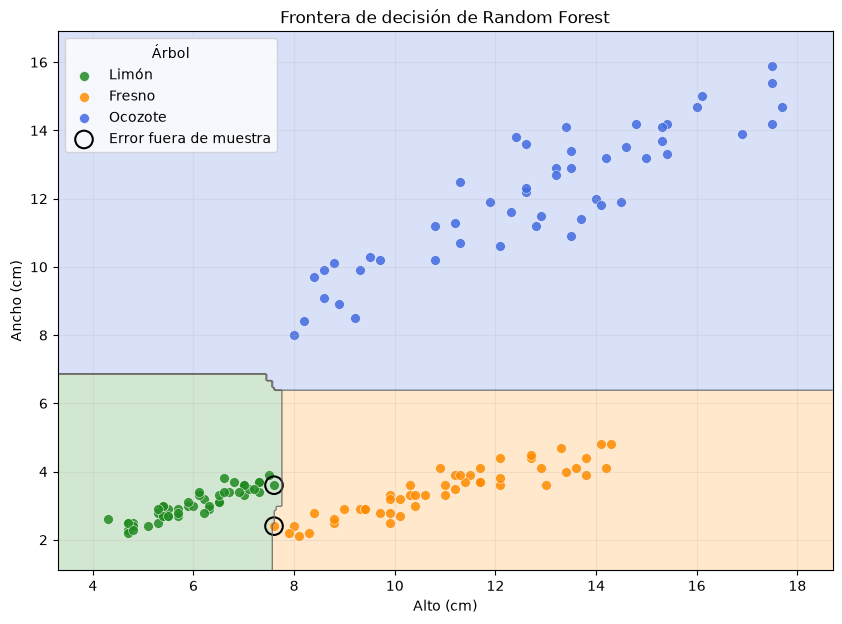

In [68]:
# Frontera de decisión del modelo final de Random Forest en el plano Alto × Ancho
malla_bosque = graficar_frontera(
    mejor_modelo_bosque,
    "Random Forest",
    predicciones_bosque
)

### Interpretación de Random Forest

La frontera de decisión corresponde al Random Forest final, entrenado con las 150 hojas. Los círculos negros marcan las dos hojas mal clasificadas en la validación cruzada anidada.

Como cada árbol utiliza umbrales paralelos a los ejes, la frontera del bosque también está formada por segmentos horizontales y verticales. Sin embargo, al combinar el voto de 100 árboles, aparecen pequeños escalones que un solo árbol no produce:

- **Ocozote** ocupa la parte superior. Su frontera horizontal se ubica, según la gráfica, entre 6.4 y 6.9 cm de ancho, en el espacio vacío entre las clases.
- **Limón** y **Fresno** se separan con una frontera casi vertical alrededor de los 7.6 cm de alto. Esta frontera tiene un escalón: con anchos pequeños, el límite se desplaza ligeramente hacia la izquierda.

Por ese escalón, el modelo final clasifica correctamente las dos hojas de 7.6 cm: la hoja 10 de Limón, más ancha (3.6 cm), queda en la región de Limón, y la hoja 123 de Fresno, más angosta (2.4 cm), queda en la de Fresno. En la validación anidada esto no ocurrió, porque cada una de estas hojas estaba fuera del entrenamiento en su fold, y sin ella el bosque no tenía información para trazar el escalón. Por lo tanto, el escalón refleja dos hojas individuales y no un patrón general que pueda esperarse en hojas nuevas.

En comparación con el árbol de decisión, Random Forest produce una frontera más estable entre los folds: su único error en Limón fue la hoja 10, y no la 37. Las regiones alejadas de las hojas, como la esquina superior izquierda o la parte derecha bajo los 6 cm de ancho, son extrapolaciones del modelo y no deben interpretarse como información del corpus.

---

## Modelo 8: Multilayer Perceptron (MLP)

El Multilayer Perceptron es una red neuronal con una o más capas ocultas. Cada neurona combina las entradas con pesos aprendidos y aplica una función de activación no lineal, por lo que la red puede construir fronteras curvas. El entrenamiento es sensible a la escala de las variables, así que el escalado se incluye dentro del `Pipeline`.

Se probarán distintas arquitecturas (capas ocultas y neuronas), funciones de activación, valores de regularización L2 (`alpha`) y tasas de aprendizaje iniciales, con el optimizador Adam. La configuración final se seleccionará utilizando el F1-score macro. Si varias configuraciones empatan, se prefiere la red más sencilla: menos neuronas en total, menos capas, mayor regularización, activación ReLU (después tanh y logística) y mayor tasa de aprendizaje.

**Diferencias con el notebook de cáncer de mama:**

- En cáncer de mama se utilizó `RandomizedSearchCV` con 8 configuraciones aleatorias por fold. Aquí se utiliza `GridSearchCV` con una rejilla fija, igual que en los otros cinco clasificadores, para aplicar el mismo procedimiento de evaluación y el mismo criterio de desempate.
- En cáncer de mama se activó el early stopping, que reserva el 10 % del entrenamiento para decidir cuándo detenerse. Con este corpus, ese 10 % serían unas 12 hojas, una señal demasiado ruidosa. Por ello se desactivó y se permitieron hasta 3000 iteraciones, suficientes para que todas las configuraciones converjan.
- La configuración final se obtiene con la misma búsqueda sobre todas las hojas que en los demás modelos, en lugar de tomar la configuración más frecuente entre los folds.

In [69]:
from sklearn.neural_network import MLPClassifier

# El escalado es indispensable para entrenar correctamente una red neuronal
pipeline_mlp = Pipeline([
    ("escalado", StandardScaler()),
    ("mlp", MLPClassifier(
        solver="adam",
        max_iter=3000,
        early_stopping=False,
        random_state=42
    ))
])

# Espacio de hiperparámetros
parametros_mlp = {
    # Arquitectura: capas ocultas y neuronas
    "mlp__hidden_layer_sizes": [
        (5,),
        (10,),
        (50,),
        (10, 5)
    ],

    # Función de activación
    "mlp__activation": [
        "relu",
        "tanh",
        "logistic"
    ],

    # Regularización L2
    "mlp__alpha": [
        1e-4,
        1e-2
    ],

    # Tasa de aprendizaje inicial
    "mlp__learning_rate_init": [
        1e-3,
        1e-2
    ]
}

# Desempate: red más sencilla
orden_activaciones = {"relu": 2, "tanh": 1, "logistic": 0}

desempate_mlp = criterio_desempate([
    ("mlp__hidden_layer_sizes", lambda capas: -sum(capas)),
    ("mlp__hidden_layer_sizes", lambda capas: -len(capas)),
    ("mlp__alpha", lambda alpha: alpha),
    ("mlp__activation", lambda activacion: orden_activaciones[activacion]),
    ("mlp__learning_rate_init", lambda tasa: tasa)
])

print(
    "Número de configuraciones de MLP:",
    len(list(ParameterGrid(parametros_mlp)))
)

Número de configuraciones de MLP: 48


In [70]:
resultados_folds_mlp_df, mejores_parametros_folds_mlp_df, predicciones_mlp = evaluar_cv_anidada(
    pipeline_mlp,
    parametros_mlp,
    "MLP",
    desempate_mlp
)

MLP — fold 1/10 terminado — mejor configuración: {'mlp__activation': 'relu', 'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (10, 5), 'mlp__learning_rate_init': 0.01}


MLP — fold 2/10 terminado — mejor configuración: {'mlp__activation': 'relu', 'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (10, 5), 'mlp__learning_rate_init': 0.01}


MLP — fold 3/10 terminado — mejor configuración: {'mlp__activation': 'relu', 'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (10,), 'mlp__learning_rate_init': 0.01}


MLP — fold 4/10 terminado — mejor configuración: {'mlp__activation': 'relu', 'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (10,), 'mlp__learning_rate_init': 0.01}


MLP — fold 5/10 terminado — mejor configuración: {'mlp__activation': 'relu', 'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (10,), 'mlp__learning_rate_init': 0.01}


MLP — fold 6/10 terminado — mejor configuración: {'mlp__activation': 'relu', 'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (10,), 'mlp__learning_rate_init': 0.01}


MLP — fold 7/10 terminado — mejor configuración: {'mlp__activation': 'relu', 'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (5,), 'mlp__learning_rate_init': 0.01}


MLP — fold 8/10 terminado — mejor configuración: {'mlp__activation': 'relu', 'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (10, 5), 'mlp__learning_rate_init': 0.01}


MLP — fold 9/10 terminado — mejor configuración: {'mlp__activation': 'relu', 'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (10, 5), 'mlp__learning_rate_init': 0.01}


MLP — fold 10/10 terminado — mejor configuración: {'mlp__activation': 'relu', 'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (10, 5), 'mlp__learning_rate_init': 0.01}
Tiempo de la validación anidada de MLP: 349.1 s


In [71]:
# Mostrar las métricas obtenidas en cada fold
display(
    resultados_folds_mlp_df.round(4)
)

resumen_mlp = resumir_metricas(resultados_folds_mlp_df)

print("Resumen de MLP con validación cruzada anidada:")
display(
    resumen_mlp.round(4)
)

print("Mejor configuración interna en cada fold:")
display(
    mejores_parametros_folds_mlp_df.round(4)
)

,fold,accuracy,precision_macro,recall_macro,f1_macro,mae
0,1,1.0000,1.0000,1.0000,1.0000,0.0000
1,2,1.0000,1.0000,1.0000,1.0000,0.0000
2,3,1.0000,1.0000,1.0000,1.0000,0.0000
3,4,1.0000,1.0000,1.0000,1.0000,0.0000
4,5,1.0000,1.0000,1.0000,1.0000,0.0000
5,6,1.0000,1.0000,1.0000,1.0000,0.0000
6,7,0.9333,0.9444,0.9333,0.9327,0.0667
7,8,1.0000,1.0000,1.0000,1.0000,0.0000
8,9,1.0000,1.0000,1.0000,1.0000,0.0000
9,10,1.0000,1.0000,1.0000,1.0000,0.0000


Resumen de MLP con validación cruzada anidada:


,metrica,promedio,desviacion_estandar
0,accuracy,0.9933,0.0211
1,precision_macro,0.9944,0.0176
2,recall_macro,0.9933,0.0211
3,f1_macro,0.9933,0.0213
4,mae,0.0067,0.0211


Mejor configuración interna en cada fold:


,fold,mejor_f1_interno,configuraciones_empatadas,mlp__activation,mlp__alpha,mlp__hidden_layer_sizes,mlp__learning_rate_init
0,1,1.0,6,relu,0.01,"(10, 5)",0.01
1,2,1.0,3,relu,0.01,"(10, 5)",0.01
2,3,1.0,18,relu,0.01,"(10,)",0.01
3,4,1.0,22,relu,0.01,"(10,)",0.01
4,5,1.0,20,relu,0.01,"(10,)",0.01
5,6,1.0,20,relu,0.01,"(10,)",0.01
6,7,1.0,38,relu,0.01,"(5,)",0.01
7,8,1.0,10,relu,0.01,"(10, 5)",0.01
8,9,1.0,12,relu,0.01,"(10, 5)",0.01
9,10,1.0,9,relu,0.01,"(10, 5)",0.01


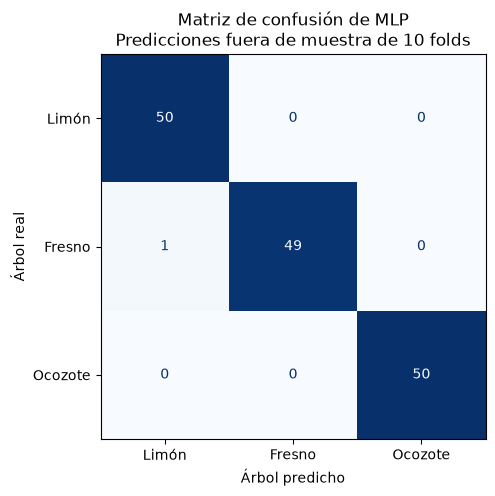

Predicciones correctas: 149
Predicciones incorrectas: 1
Hojas mal clasificadas:


,ID hoja,Árbol,Alto (cm),Ancho (cm),Árbol predicho
0,123,Fresno,7.6,2.4,Limón


In [72]:
# Matriz de confusión del MLP con las predicciones fuera de muestra
matriz_confusion_mlp = graficar_matriz_confusion(
    predicciones_mlp,
    "MLP"
)

### Matriz de confusión del MLP

El MLP clasificó correctamente 149 de las 150 hojas. Igual que k-NN y SVM, su único error fue la hoja **123** de Fresno (7.6 × 2.4 cm), clasificada como Limón en el fold 7. Todas las hojas de Limón y de Ocozote se clasificaron correctamente.

Con validación cruzada anidada, el MLP obtuvo un accuracy de **0.9933 ± 0.0211**, precision macro de **0.9944 ± 0.0176**, recall macro de **0.9933 ± 0.0211**, F1 macro de **0.9933 ± 0.0213** y MAE de **0.0067 ± 0.0211**.

In [73]:
# Búsqueda final utilizando todas las hojas
busqueda_final_mlp = buscar_configuracion_final(
    pipeline_mlp,
    parametros_mlp,
    desempate_mlp
)

mejor_modelo_mlp = busqueda_final_mlp.best_estimator_

# F1 macro según cada hiperparámetro
resultados_busqueda_mlp = pd.DataFrame(busqueda_final_mlp.cv_results_)

for parametro in [
    "param_mlp__hidden_layer_sizes",
    "param_mlp__activation",
    "param_mlp__alpha",
    "param_mlp__learning_rate_init"
]:
    display(
        resultados_busqueda_mlp
        .assign(valor=resultados_busqueda_mlp[parametro].astype(str))
        .groupby("valor", sort=False)["mean_test_score"]
        .agg(["max", "mean", "min"])
        .rename(columns={"max": "F1 máximo", "mean": "F1 promedio", "min": "F1 mínimo"})
        .rename_axis(parametro.replace("param_mlp__", ""))
        .round(4)
    )

Mejores parámetros finales:
{'mlp__activation': 'relu', 'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (10, 5), 'mlp__learning_rate_init': 0.01}
F1 macro promedio durante la búsqueda: 1.0
Configuraciones empatadas con el mejor F1 macro: 13


,param_mlp__activation,param_mlp__alpha,param_mlp__hidden_layer_sizes,param_mlp__learning_rate_init,mean_test_score,std_test_score,rank_test_score
0,relu,0.0001,"(50,)",0.010,1.0,0.0,1
1,relu,0.0001,"(10, 5)",0.001,1.0,0.0,1
2,relu,0.0001,"(10, 5)",0.010,1.0,0.0,1
3,relu,0.0100,"(50,)",0.010,1.0,0.0,1
4,relu,0.0100,"(10, 5)",0.001,1.0,0.0,1
5,relu,0.0100,"(10, 5)",0.010,1.0,0.0,1
6,tanh,0.0001,"(50,)",0.010,1.0,0.0,1
7,tanh,0.0001,"(10, 5)",0.001,1.0,0.0,1
8,tanh,0.0001,"(10, 5)",0.010,1.0,0.0,1
9,tanh,0.0100,"(50,)",0.010,1.0,0.0,1


,F1 máximo,F1 promedio,F1 mínimo
hidden_layer_sizes,,,
"(5,)",0.9933,0.9933,0.9933
"(10,)",0.9933,0.9921,0.9865
"(50,)",1.0000,0.9961,0.9933
"(10, 5)",1.0000,0.9978,0.9933


,F1 máximo,F1 promedio,F1 mínimo
activation,,,
relu,1.0,0.9958,0.9933
tanh,1.0,0.9958,0.9933
logistic,1.0,0.9928,0.9865


,F1 máximo,F1 promedio,F1 mínimo
alpha,,,
0.0001,1.0,0.9949,0.9865
0.01,1.0,0.9947,0.9865


,F1 máximo,F1 promedio,F1 mínimo
learning_rate_init,,,
0.001,1.0,0.9938,0.9865
0.01,1.0,0.9958,0.9933


Iteraciones utilizadas: 404
Pérdida final: 0.0237
Número de parámetros (pesos y sesgos): 103


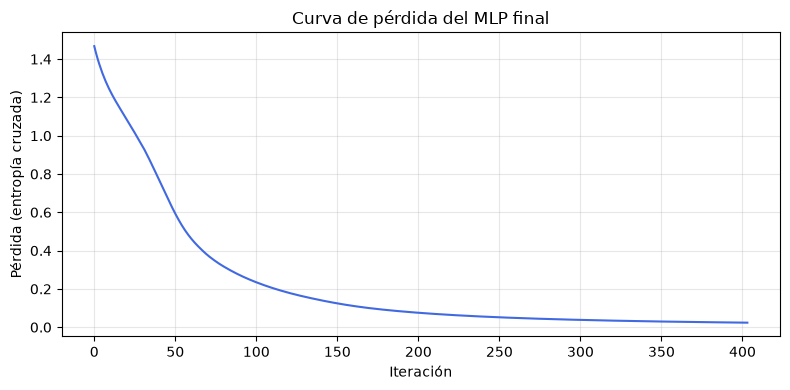

In [74]:
# Curva de pérdida del MLP final
modelo_final_mlp = mejor_modelo_mlp.named_steps["mlp"]

print("Iteraciones utilizadas:", modelo_final_mlp.n_iter_)
print("Pérdida final:", round(modelo_final_mlp.loss_, 4))
print(
    "Número de parámetros (pesos y sesgos):",
    sum(w.size for w in modelo_final_mlp.coefs_)
    + sum(b.size for b in modelo_final_mlp.intercepts_)
)

plt.figure(figsize=(8, 4))
plt.plot(modelo_final_mlp.loss_curve_, color="royalblue")
plt.title("Curva de pérdida del MLP final")
plt.xlabel("Iteración")
plt.ylabel("Pérdida (entropía cruzada)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Selección de la configuración final del MLP

Se evaluaron **48 configuraciones**, combinando 4 arquitecturas, 3 funciones de activación, 2 valores de regularización L2 y 2 tasas de aprendizaje iniciales.

Al buscar con las 150 hojas, **13 configuraciones empataron** con un F1 macro de **1.0**. Ninguna red con una sola capa de 5 o 10 neuronas alcanzó ese valor: su F1 máximo fue de 0.9933. Las arquitecturas (50,) y (10, 5) sí llegaron a 1.0. El resto de los hiperparámetros tuvo poco efecto: todas las configuraciones obtuvieron un F1 de al menos 0.9865.

Siguiendo el criterio de desempate, se eligió la red con menos neuronas entre las empatadas: **dos capas ocultas de 10 y 5 neuronas**, activación **ReLU**, `alpha` de **0.01** y tasa de aprendizaje inicial de **0.01**. Esta red tiene 15 neuronas ocultas, menos que la de una capa de 50, y 103 parámetros entrenables (pesos y sesgos).

En la validación anidada, todos los folds eligieron activación ReLU, `alpha` de 0.01 y tasa de aprendizaje de 0.01. La arquitectura varió entre (5,), (10,) y (10, 5), y en cada fold empataron entre 3 y 38 configuraciones.

La curva de pérdida del modelo final desciende rápidamente durante las primeras 100 iteraciones y después se estabiliza. El entrenamiento convergió en 404 iteraciones, con una pérdida final de 0.0237, por debajo del límite de 3000 iteraciones.

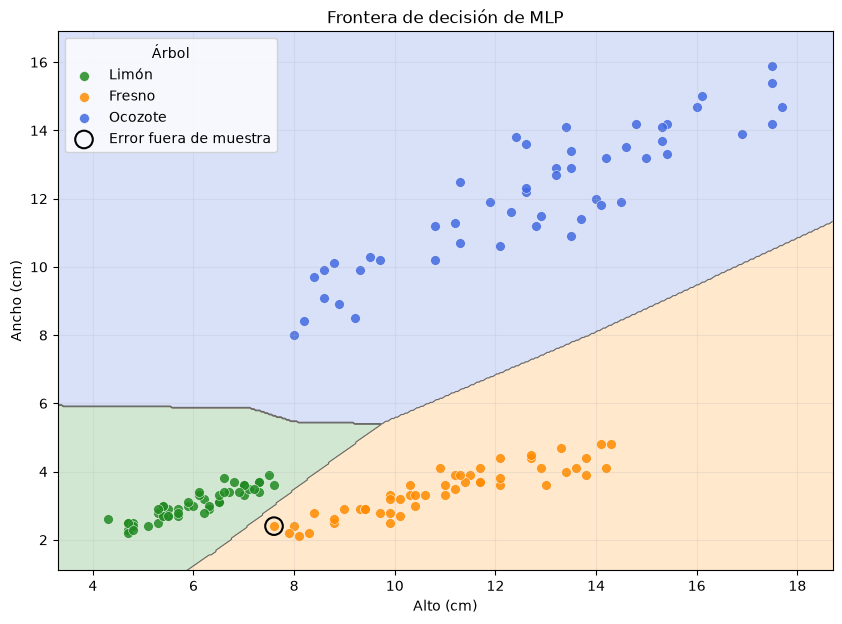

In [75]:
# Frontera de decisión del MLP final en el plano Alto × Ancho
malla_mlp = graficar_frontera(
    mejor_modelo_mlp,
    "MLP",
    predicciones_mlp
)

### Interpretación de Multilayer Perceptron

La frontera de decisión corresponde al MLP final, entrenado con las 150 hojas. El círculo negro marca la hoja mal clasificada en la validación cruzada anidada.

Con activación ReLU, cada neurona aplica una función lineal por tramos, por lo que la frontera de la red está formada por segmentos rectos unidos en ángulos:

- **Ocozote** ocupa la parte superior. Su frontera con Limón es casi horizontal, alrededor de 6 cm de ancho según la gráfica, y su frontera con Fresno sube en diagonal hacia la derecha.
- **Limón** y **Fresno** se separan con una recta diagonal, de forma parecida a SVM con kernel lineal: una hoja se clasifica como Fresno cuando es larga en relación con su ancho.

La hoja 123 está prácticamente sobre la frontera entre Limón y Fresno, igual que en los demás modelos.

La frontera diagonal entre Fresno y Ocozote se acerca a las hojas de Ocozote del lado derecho, aunque todas quedan dentro de su región. En las zonas sin hojas, la posición de las fronteras depende de la inicialización y de la regularización de la red, por lo que no debe interpretarse como información del corpus.

El MLP alcanzó el mismo desempeño que k-NN y SVM, pero es el modelo más costoso de entrenar y el menos interpretable. Con solo dos características y clases casi separables, su capacidad para aprender fronteras complejas no aporta una ventaja medible.

---

## Comparación y ranking de los modelos supervisados

Los seis clasificadores se comparan utilizando las métricas obtenidas mediante validación cruzada anidada con las 2 características originales y las mismas 10 particiones externas. El ranking principal se construye con el F1-score macro promedio. La tabla se genera directamente a partir de los resúmenes calculados en cada modelo, sin escribir valores a mano.

In [76]:
# Comparación de los seis clasificadores del corpus de hojas
modelos_supervisados = {
    "k-NN": (resumen_knn, predicciones_knn, busqueda_final_knn),
    "Naive Bayes": (resumen_nb, predicciones_nb, busqueda_final_nb),
    "SVM": (resumen_svm, predicciones_svm, busqueda_final_svm),
    "Árbol de decisión": (resumen_arbol, predicciones_arbol, busqueda_final_arbol),
    "Random Forest": (resumen_bosque, predicciones_bosque, busqueda_final_bosque),
    "MLP": (resumen_mlp, predicciones_mlp, busqueda_final_mlp)
}

filas_comparacion = []

for nombre_modelo, (resumen, predicciones, busqueda) in modelos_supervisados.items():
    fila = {"modelo": nombre_modelo}

    for _, metrica in resumen.iterrows():
        fila[f"{metrica['metrica']}_promedio"] = metrica["promedio"]
        fila[f"{metrica['metrica']}_desv"] = metrica["desviacion_estandar"]

    fila["errores_fuera_de_muestra"] = int((predicciones != y).sum())
    filas_comparacion.append(fila)

comparacion_supervisados = pd.DataFrame(filas_comparacion)

# Ranking por F1 macro promedio; los empates comparten posición
comparacion_supervisados["ranking_f1"] = (
    comparacion_supervisados["f1_macro_promedio"]
    .round(4)
    .rank(method="min", ascending=False)
    .astype(int)
)

comparacion_supervisados = (
    comparacion_supervisados
    .sort_values(["ranking_f1", "modelo"])
    .reset_index(drop=True)
)

# Tabla para presentar: promedio ± desviación estándar
tabla_ranking = pd.DataFrame({
    "Ranking": comparacion_supervisados["ranking_f1"],
    "Modelo": comparacion_supervisados["modelo"]
})

for metrica, nombre in [
    ("f1_macro", "F1 macro"),
    ("accuracy", "Accuracy"),
    ("precision_macro", "Precision macro"),
    ("recall_macro", "Recall macro"),
    ("mae", "MAE")
]:
    tabla_ranking[nombre] = [
        f"{promedio:.4f} ± {desviacion:.4f}"
        for promedio, desviacion in zip(
            comparacion_supervisados[f"{metrica}_promedio"],
            comparacion_supervisados[f"{metrica}_desv"]
        )
    ]

tabla_ranking["Errores (de 150)"] = comparacion_supervisados["errores_fuera_de_muestra"]

display(tabla_ranking)

,Ranking,Modelo,F1 macro,Accuracy,Precision macro,Recall macro,MAE,Errores (de 150)
0,1,MLP,0.9933 ± 0.0213,0.9933 ± 0.0211,0.9944 ± 0.0176,0.9933 ± 0.0211,0.0067 ± 0.0211,1
1,1,SVM,0.9933 ± 0.0213,0.9933 ± 0.0211,0.9944 ± 0.0176,0.9933 ± 0.0211,0.0067 ± 0.0211,1
2,1,k-NN,0.9933 ± 0.0213,0.9933 ± 0.0211,0.9944 ± 0.0176,0.9933 ± 0.0211,0.0067 ± 0.0211,1
3,4,Random Forest,0.9865 ± 0.0284,0.9867 ± 0.0281,0.9889 ± 0.0234,0.9867 ± 0.0281,0.0133 ± 0.0281,2
4,5,Naive Bayes,0.9798 ± 0.0325,0.9800 ± 0.0322,0.9833 ± 0.0268,0.9800 ± 0.0322,0.0200 ± 0.0322,3
5,5,Árbol de decisión,0.9798 ± 0.0325,0.9800 ± 0.0322,0.9833 ± 0.0268,0.9800 ± 0.0322,0.0200 ± 0.0322,3


In [77]:
# Configuración final seleccionada para cada clasificador
configuraciones_finales = pd.DataFrame([
    {
        "Modelo": nombre_modelo,
        "Configuración final": ", ".join(
            f"{parametro.split('__')[1]}={valor}"
            for parametro, valor in busqueda.best_params_.items()
            if parametro.split("__")[1] != "metric"
        ),
        "Configuraciones empatadas": numero_empatados(busqueda)
    }
    for nombre_modelo, (_, _, busqueda) in modelos_supervisados.items()
])

pd.set_option("display.max_colwidth", None)
display(configuraciones_finales)

,Modelo,Configuración final,Configuraciones empatadas
0,k-NN,"n_neighbors=9, p=1, weights=uniform",32
1,Naive Bayes,var_smoothing=1e-12,10
2,SVM,"C=10, kernel=linear",15
3,Árbol de decisión,"criterion=gini, max_depth=3, min_samples_leaf=2, min_samples_split=10",126
4,Random Forest,"criterion=gini, max_depth=5, max_features=sqrt, n_estimators=100",54
5,MLP,"activation=relu, alpha=0.01, hidden_layer_sizes=(10, 5), learning_rate_init=0.01",13


In [78]:
# Hojas mal clasificadas por al menos un modelo (predicciones fuera de muestra)
errores_por_modelo = pd.DataFrame({
    nombre_modelo: np.where(predicciones != y, np.array(CLASES)[predicciones], "")
    for nombre_modelo, (_, predicciones, _) in modelos_supervisados.items()
})

hojas_con_error = errores_por_modelo.ne("").any(axis=1)

tabla_errores = pd.concat([
    datos.loc[hojas_con_error, ["ID hoja", columna_clase] + caracteristicas].reset_index(drop=True),
    errores_por_modelo.loc[hojas_con_error].reset_index(drop=True)
], axis=1)

print("Hojas mal clasificadas por algún modelo (se muestra la clase predicha):")
display(tabla_errores)

print(
    "Modelos que se equivocaron en cada hoja:",
    errores_por_modelo.loc[hojas_con_error].ne("").sum(axis=1).tolist()
)

Hojas mal clasificadas por algún modelo (se muestra la clase predicha):


,ID hoja,Árbol,Alto (cm),Ancho (cm),k-NN,Naive Bayes,SVM,Árbol de decisión,Random Forest,MLP
0,10,Limón,7.6,3.6,,,,Fresno,Fresno,
1,37,Limón,7.5,3.9,,,,Fresno,,
2,103,Fresno,8.0,2.4,,Limón,,,,
3,123,Fresno,7.6,2.4,Limón,Limón,Limón,Limón,Limón,Limón
4,144,Fresno,7.9,2.2,,Limón,,,,


Modelos que se equivocaron en cada hoja: [2, 1, 1, 6, 1]


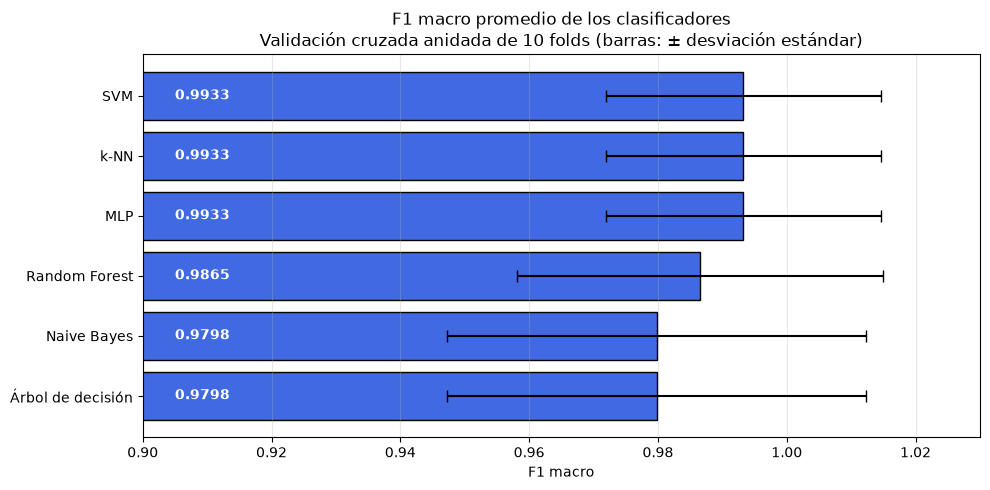

In [79]:
# Gráfica del F1 macro promedio con su desviación estándar
fig, ax = plt.subplots(figsize=(10, 5))

orden_grafica = comparacion_supervisados.sort_values("f1_macro_promedio")

ax.barh(
    orden_grafica["modelo"],
    orden_grafica["f1_macro_promedio"],
    xerr=orden_grafica["f1_macro_desv"],
    color="royalblue",
    edgecolor="black",
    capsize=4
)

for posicion, valor in enumerate(orden_grafica["f1_macro_promedio"]):
    ax.text(0.905, posicion, f"{valor:.4f}", va="center", color="white", fontweight="bold")

ax.set_xlim(0.9, 1.03)
ax.set_title("F1 macro promedio de los clasificadores\nValidación cruzada anidada de 10 folds (barras: ± desviación estándar)")
ax.set_xlabel("F1 macro")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Fronteras de decisión de los seis clasificadores

Para comparar visualmente los modelos, se reúnen las seis fronteras de decisión en una sola figura. Todas corresponden a los modelos finales entrenados con las 150 hojas en el plano Alto × Ancho (cm). Los círculos negros marcan las hojas mal clasificadas en la validación cruzada anidada de cada modelo.

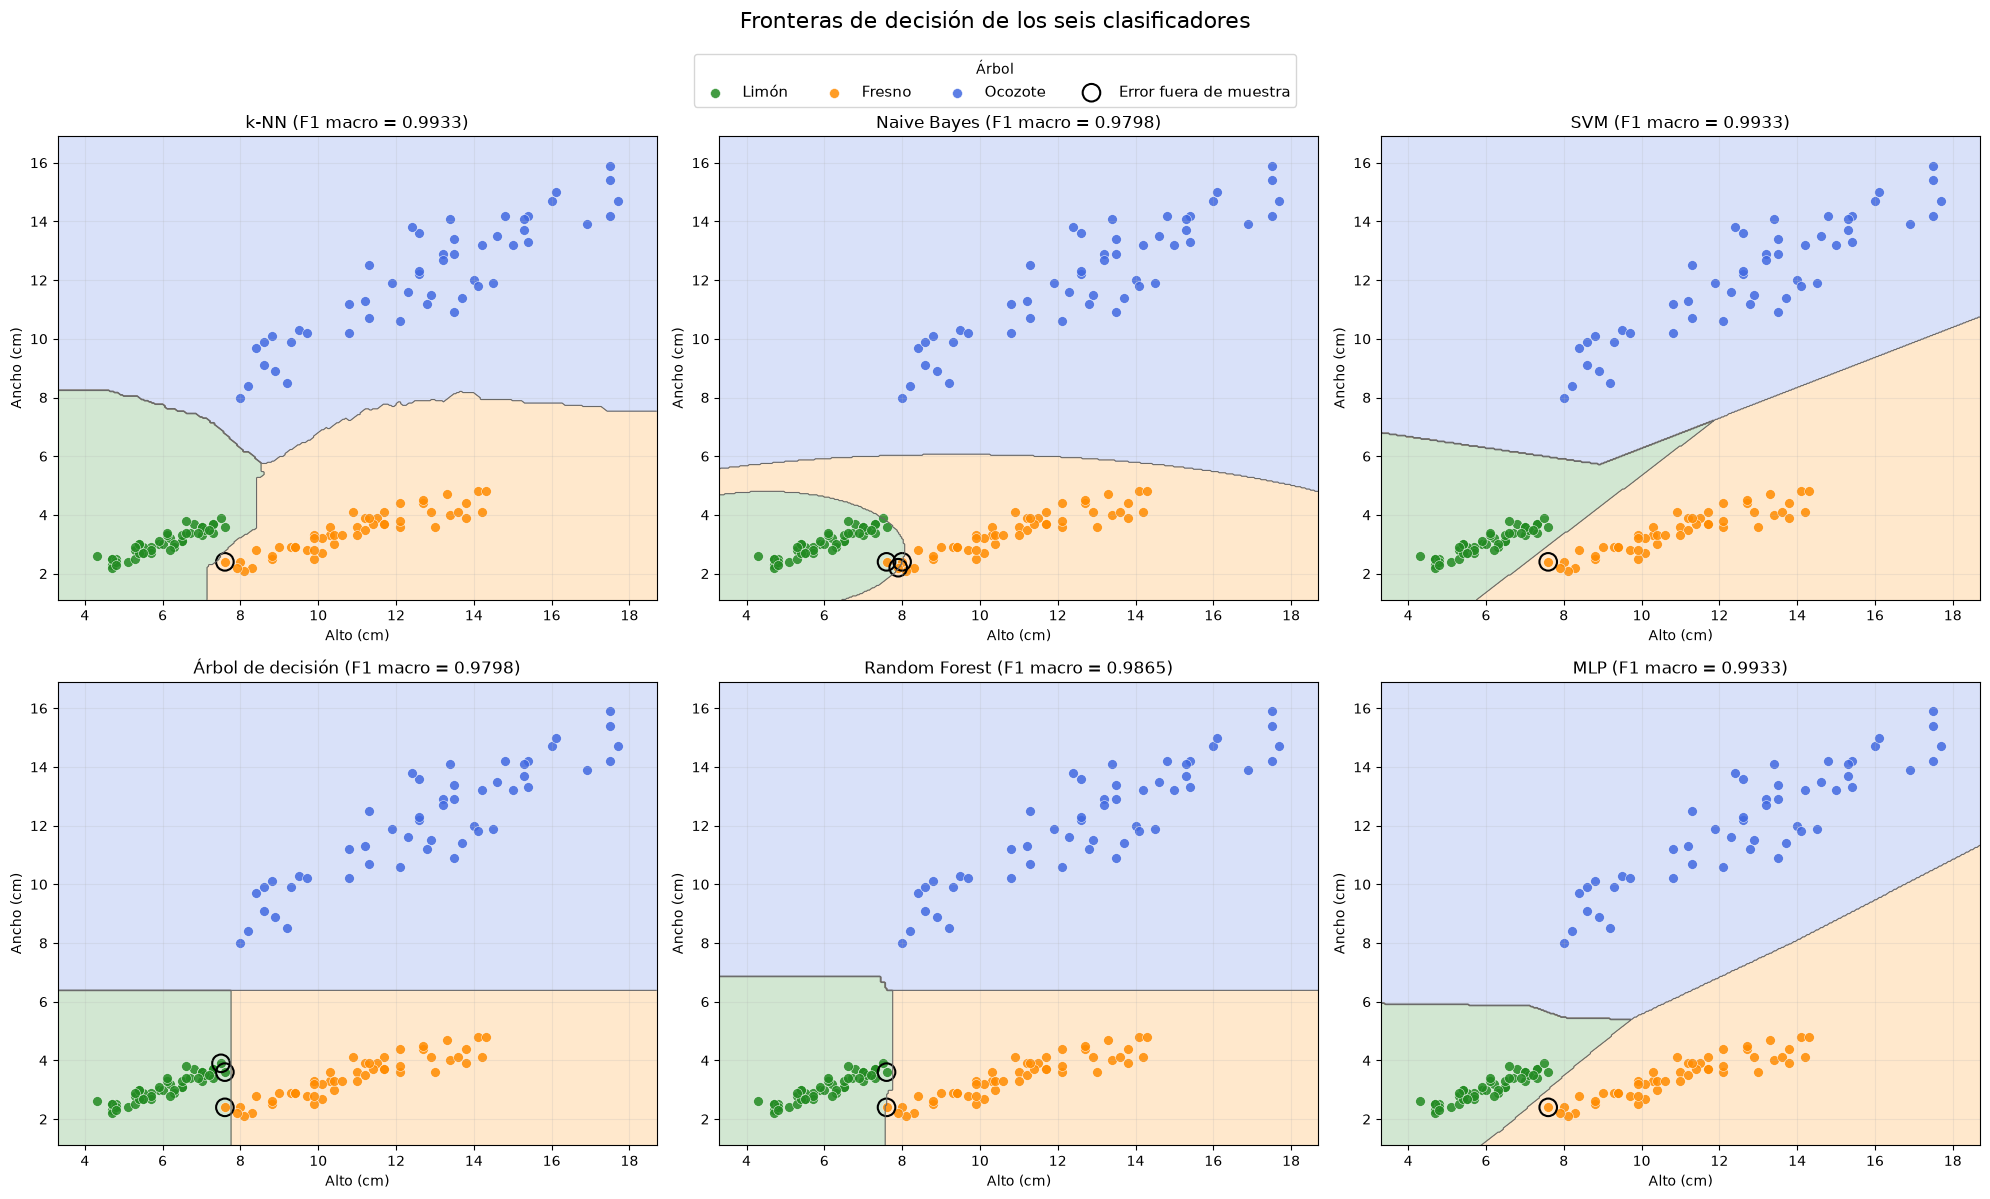

In [80]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

modelos_finales = {
    "k-NN": (mejor_modelo_knn, predicciones_knn),
    "Naive Bayes": (mejor_modelo_nb, predicciones_nb),
    "SVM": (mejor_modelo_svm, predicciones_svm),
    "Árbol de decisión": (mejor_modelo_arbol, predicciones_arbol),
    "Random Forest": (mejor_modelo_bosque, predicciones_bosque),
    "MLP": (mejor_modelo_mlp, predicciones_mlp)
}

for ax, (nombre_modelo, (modelo, predicciones)) in zip(axes.ravel(), modelos_finales.items()):
    graficar_frontera(modelo, nombre_modelo, predicciones, ax=ax)

    f1_modelo = comparacion_supervisados.loc[
        comparacion_supervisados["modelo"] == nombre_modelo, "f1_macro_promedio"
    ].iloc[0]

    ax.set_title(f"{nombre_modelo} (F1 macro = {f1_modelo:.4f})")

# Una sola leyenda para toda la figura
manejadores, etiquetas = axes[0, 0].get_legend_handles_labels()
for ax in axes.ravel():
    ax.get_legend().remove()

plt.tight_layout(rect=(0, 0, 1, 0.92))
fig.suptitle("Fronteras de decisión de los seis clasificadores", fontsize=16, y=0.995)
fig.legend(
    manejadores, etiquetas, title="Árbol",
    loc="upper center", bbox_to_anchor=(0.5, 0.965), ncol=4, fontsize=11
)
plt.show()

### Análisis comparativo de los clasificadores

**k-NN, SVM y MLP comparten el primer lugar** con un F1 macro de **0.9933 ± 0.0213**. Los tres se equivocaron únicamente en una hoja, la misma: la **123** de Fresno (7.6 × 2.4 cm). Random Forest ocupó el cuarto lugar con **0.9865 ± 0.0284** (2 errores), y Naive Bayes y el árbol de decisión comparten el quinto lugar con **0.9798 ± 0.0325** (3 errores cada uno). Las demás métricas siguen el mismo orden. El MAE coincide con la proporción de errores en todos los modelos, porque todos los errores confunden Limón con Fresno, cuyos códigos son consecutivos.

Las diferencias entre los modelos son de **una o dos hojas** de 150. Las desviaciones estándar entre folds (de 0.0213 a 0.0325) son mayores que la distancia entre el primero y el último lugar, por lo que este ranking no permite afirmar que un modelo sea superior a otro con este tamaño de muestra. En la gráfica de barras, el eje inicia en 0.90 para hacer visibles las diferencias, y las barras de desviación superan el valor de 1.0 solamente porque se dibujan como media ± desviación; el F1 no puede ser mayor que 1.

La tabla de errores muestra que, entre los seis modelos, solo **5 hojas** fueron mal clasificadas alguna vez, y todas están en la frontera entre Limón y Fresno, con alto de 7.5 a 8.0 cm. **Ninguna hoja de Ocozote fue mal clasificada por ningún modelo.** La hoja 123 fue mal clasificada por los seis modelos: tiene el alto máximo de Limón y un ancho que también corresponde a Limón, por lo que con estas dos características es prácticamente indistinguible de una hoja de Limón.

Los errores restantes revelan el sesgo de cada modelo:

- **Naive Bayes** clasificó como Limón tres hojas de Fresno cortas y angostas (103, 123 y 144), porque su supuesto de independencia ignora la correlación entre alto y ancho dentro de Limón.
- **El árbol de decisión** falló en ambos sentidos (10 y 37 de Limón, y 123 de Fresno), porque su frontera depende de un único umbral sobre el alto que se mueve según las hojas de entrenamiento.
- **Random Forest** estabilizó ese umbral al promediar 100 árboles y corrigió la hoja 37, pero mantuvo los errores en las dos hojas de 7.6 cm.
- **k-NN, SVM y MLP** construyen fronteras que combinan ambas variables o que se adaptan localmente, y solo fallaron en la hoja 123.

La figura comparativa muestra que todos los modelos coinciden en lo esencial: Ocozote se separa por el ancho y Limón y Fresno por el alto. Las fronteras difieren sobre todo en las zonas sin hojas, donde cada modelo extrapola de forma distinta: k-NN produce bordes irregulares, Naive Bayes regiones elípticas, el árbol y Random Forest rectángulos, y SVM y MLP rectas diagonales. Como no hay hojas en esas zonas, la validación cruzada no puede indicar cuál extrapolación es la correcta.

En la búsqueda de hiperparámetros, todos los modelos presentaron muchas configuraciones empatadas (desde 10 en Naive Bayes hasta 126 en el árbol de decisión; en Random Forest empataron las 54 configuraciones evaluadas). Esto indica que el desempeño depende poco de los hiperparámetros en este corpus. La excepción relevante fue SVM con kernel polinomial, cuyo F1 varió mucho entre configuraciones.

Finalmente, el costo computacional fue muy distinto. En esta ejecución, la validación anidada tardó 2.0 s con Naive Bayes, 9.9 s con k-NN y 33.6 s con SVM, frente a 126.9 s con el árbol de decisión, 667.3 s con Random Forest y 863.7 s con MLP. Los modelos más costosos no obtuvieron mejores resultados que k-NN o SVM.

---

## Comparación de los métodos no supervisados

K-means y el clustering jerárquico se comparan principalmente mediante el coeficiente de silueta, calculado en ambos casos con la distancia euclidiana sobre las variables estandarizadas. Las etiquetas reales no se utilizaron durante el entrenamiento; únicamente se emplearon después para interpretar los agrupamientos mediante ARI y NMI.

In [81]:
# Comparación de los métodos de clustering
comparacion_clustering = pd.DataFrame([
    {
        "Método": "Clustering jerárquico",
        "Configuración": (
            f"{mejor_config_jerarquico['linkage']} + {mejor_config_jerarquico['metrica']}"
        ),
        "Clústeres": k_jerarquico,
        "Tamaños": sorted(np.bincount(clusters_jerarquico).tolist(), reverse=True),
        "Silueta": silueta_jerarquico,
        "ARI": ari_jerarquico,
        "NMI": nmi_jerarquico
    },
    {
        "Método": "K-means",
        "Configuración": (
            f"init={mejor_config_kmeans['init']}, n_init={mejor_config_kmeans['n_init']}"
        ),
        "Clústeres": k_kmeans,
        "Tamaños": sorted(np.bincount(clusters_kmeans).tolist(), reverse=True),
        "Silueta": silueta_kmeans,
        "ARI": ari_kmeans,
        "NMI": nmi_kmeans
    }
]).sort_values("Silueta", ascending=False).reset_index(drop=True)

display(comparacion_clustering.round(4))

# Silueta con 3 clústeres (el número de árboles) para cada método
print("Silueta con 3 clústeres:")
print("  Clustering jerárquico:", round(mejor_por_k_jerarquico.loc[
    mejor_por_k_jerarquico["n_clusters"] == 3, "silueta_euclidiana"
].iloc[0], 4))
print("  K-means:", round(mejor_por_k_kmeans.loc[
    mejor_por_k_kmeans["n_clusters"] == 3, "silueta"
].iloc[0], 4))

,Método,Configuración,Clústeres,Tamaños,Silueta,ARI,NMI
0,Clustering jerárquico,ward + euclidean,4,"[59, 41, 39, 11]",0.6144,0.7407,0.7880
1,K-means,"init=k-means++, n_init=20",5,"[58, 42, 23, 14, 13]",0.6115,0.6711,0.7419


Silueta con 3 clústeres:
  Clustering jerárquico: 0.5704
  K-means: 0.5709


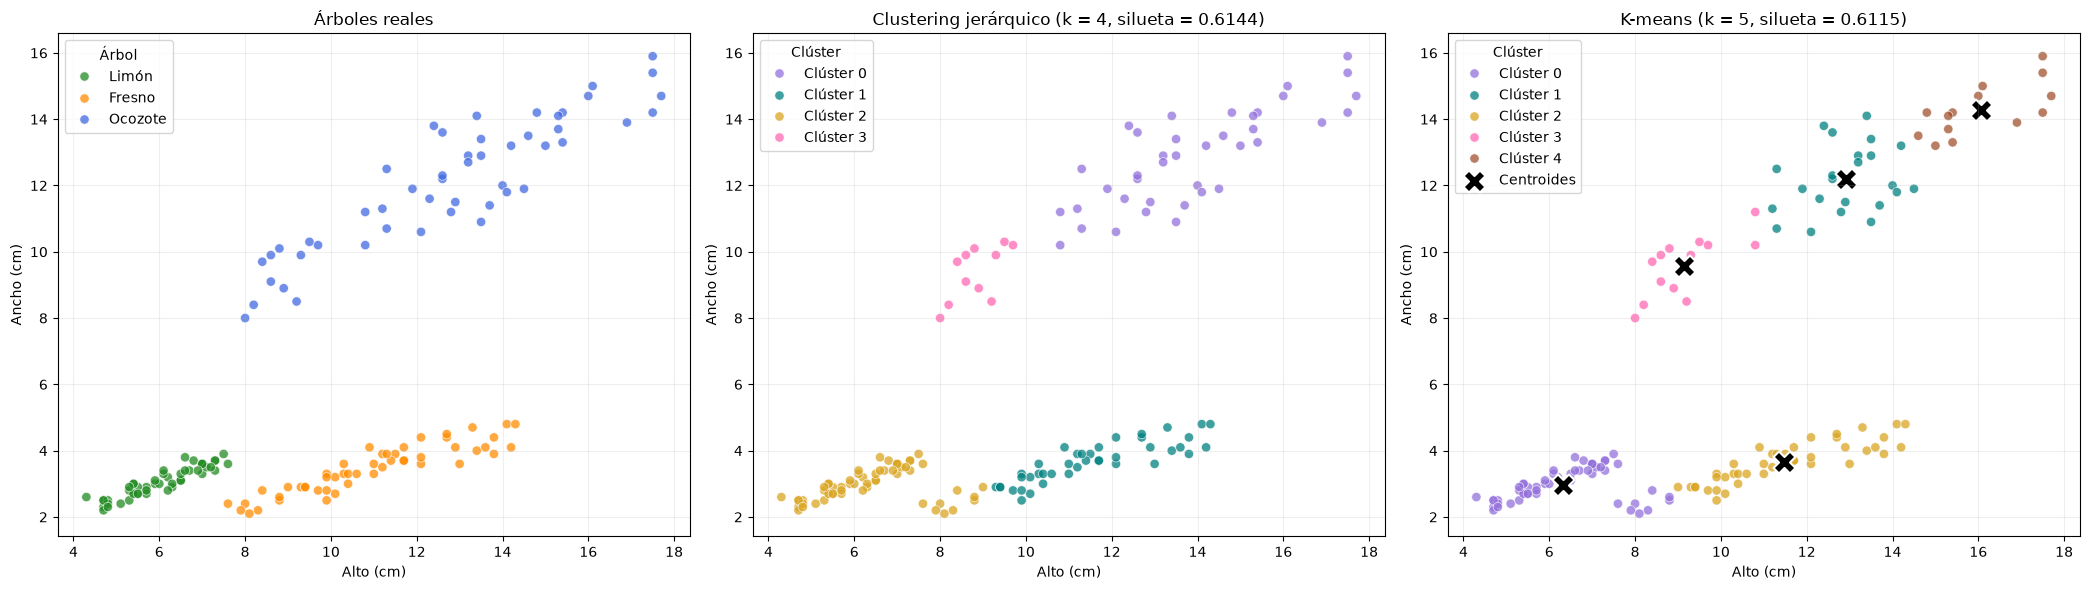

In [82]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# Árboles reales
sns.scatterplot(
    x=X[:, 0], y=X[:, 1],
    hue=np.array(CLASES)[y], hue_order=CLASES, palette=COLORES_CLASE,
    alpha=0.75, s=45, ax=axes[0]
)
axes[0].set_title("Árboles reales")
axes[0].legend(title="Árbol")

# Clustering jerárquico
sns.scatterplot(
    x=X[:, 0], y=X[:, 1],
    hue=nombres_cluster_jerarquico, hue_order=orden_cluster_jerarquico,
    palette=paleta_cluster_jerarquico,
    alpha=0.75, s=45, ax=axes[1]
)
axes[1].set_title(
    f"Clustering jerárquico (k = {k_jerarquico}, silueta = {silueta_jerarquico:.4f})"
)
axes[1].legend(title="Clúster")

# K-means
sns.scatterplot(
    x=X[:, 0], y=X[:, 1],
    hue=nombres_cluster_kmeans, hue_order=orden_cluster_kmeans,
    palette=paleta_cluster_kmeans,
    alpha=0.75, s=45, ax=axes[2]
)
axes[2].scatter(
    centroides_kmeans_cm[:, 0], centroides_kmeans_cm[:, 1],
    marker="X", s=250, color="black", edgecolor="white", linewidth=1.5,
    label="Centroides"
)
axes[2].set_title(f"K-means (k = {k_kmeans}, silueta = {silueta_kmeans:.4f})")
axes[2].legend(title="Clúster")

for ax in axes:
    ax.set_xlabel("Alto (cm)")
    ax.set_ylabel("Ancho (cm)")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Interpretación de los métodos no supervisados

El clustering jerárquico obtuvo un coeficiente de silueta de **0.6144** con 4 clústeres, prácticamente igual al de K-means con 5 clústeres (**0.6115**). Ambos valores se calcularon con la distancia euclidiana sobre las variables estandarizadas, por lo que son comparables entre sí. La diferencia de 0.003 es muy pequeña, por lo que ambos métodos encontraron agrupamientos con una calidad interna similar.

La diferencia está en la correspondencia con los árboles reales. El clustering jerárquico obtuvo un ARI de **0.7407** y un NMI de **0.7880**, superiores a los de K-means (**0.6711** y **0.7419**), porque dividió a Ocozote en 2 grupos en lugar de 3. Ninguno de los dos métodos utilizó las etiquetas para entrenar.

Ambos métodos coinciden en la estructura general del corpus:

1. La separación más fuerte es entre las hojas anchas (Ocozote) y las angostas (Limón y Fresno).
2. Limón y Fresno se separan por el alto, pero los dos métodos agrupan con Limón algunas hojas cortas de Fresno (9 en el jerárquico y 8 en K-means).
3. Ocozote, la clase más dispersa, se divide en varios grupos de hojas de distinto tamaño.

Con 3 clústeres, que es el número de árboles, la silueta fue de 0.5704 en el jerárquico y de 0.5709 en K-means, menor que con 4 o 5 clústeres. Esto indica que los tres árboles no forman tres grupos compactos de forma natural en el espacio de alto y ancho: Ocozote es demasiado disperso y Limón y Fresno quedan contiguos. Por eso, en este corpus, los métodos supervisados resultan mucho más adecuados para identificar el tipo de árbol, mientras que el clustering sirve para describir la estructura de los datos.

---

## Discusión de resultados

**Geometría de los datos y solapamiento de clases.** El corpus es casi separable con solo dos características. Ocozote se separa por completo gracias al ancho, con un espacio vacío de más de 3 cm entre su hoja más angosta y las hojas más anchas de las otras clases. Limón y Fresno se traslapan casi totalmente en el ancho y solo coinciden en el alto en un valor, 7.6 cm. Por ello, todos los clasificadores superaron un F1 macro de 0.97, y todos los errores ocurrieron en una franja estrecha alrededor de los 7.6 cm de alto. El mejor desempeño posible está limitado por hojas como la 123, que con estas dos medidas es indistinguible de una hoja de Limón.

**Ruido de medición.** Las medidas se registraron con una resolución de 0.1 cm y en su mayoría se obtuvieron a partir de fotografías con ayuda de herramientas de inteligencia artificial. En la zona de frontera entre Limón y Fresno, un error de unos pocos milímetros en el alto basta para cambiar la clase predicha. Por ello, las diferencias de una o dos hojas entre los modelos pueden deberse tanto al ruido de medición como a las propiedades de cada algoritmo.

**Escalado.** El alto y el ancho tienen rangos y dispersiones distintas. Los modelos basados en distancias o pesos (k-NN, SVM y MLP) y el clustering se aplicaron sobre las variables estandarizadas, con el escalado ajustado solo con los datos de entrenamiento de cada partición. Los modelos basados en umbrales (árbol de decisión y Random Forest) no lo necesitan, por lo que sus reglas se pudieron expresar directamente en centímetros.

**Complejidad del modelo.** Los modelos más complejos no mejoraron a los más sencillos. SVM con kernel lineal y k-NN alcanzaron el mismo resultado que el MLP, con un costo de entrenamiento mucho menor. Naive Bayes, a pesar de su sencillez, quedó por debajo por un supuesto que no se cumple en estos datos: la independencia entre el alto y el ancho dentro de cada clase. El árbol de decisión es el más fácil de interpretar, pero su frontera depende de un solo umbral, sensible a pequeñas variaciones en los datos de entrenamiento.

**Sensibilidad a los hiperparámetros.** En todos los modelos hubo muchas configuraciones empatadas, por lo que fue necesario definir un criterio de desempate explícito (elegir la configuración más sencilla) antes de evaluar. Este criterio tuvo un costo pequeño en k-NN, donde una configuración con menos vecinos habría evitado el error en la hoja 123. Se mantuvo porque cambiarlo después de ver la evaluación externa sería ajustar el procedimiento con los datos de prueba.

**Dimensionalidad.** Con solo dos características, los modelos se pudieron visualizar sin pérdida de información: cada frontera mostrada es exactamente la del modelo evaluado, sin necesidad de PCA. Esto permitió identificar las hojas concretas que causan los errores. A cambio, dos medidas no alcanzan para distinguir las hojas de Limón y Fresno de tamaño intermedio; características adicionales, como la forma del borde, la nervadura o el color, podrían resolver esos casos.

La comparación de estos resultados con los de la base de cáncer de mama se presenta en el reporte final.

## Conclusiones

- **Supervisados:** los seis clasificadores identificaron el tipo de árbol con un F1 macro de entre 0.9798 y 0.9933 en validación cruzada anidada. k-NN, SVM y MLP compartieron el primer lugar, pero las diferencias entre todos los modelos fueron de una o dos hojas, menores que la variación entre folds.
- **No supervisados:** el clustering jerárquico y K-means encontraron una estructura relacionada con los árboles reales (ARI de 0.7407 y 0.6711), pero la silueta no favoreció 3 clústeres. La separación natural más fuerte es entre hojas anchas y angostas, y Ocozote se divide en grupos de distinto tamaño.
- **Características del corpus:** el ancho separa a Ocozote y el alto separa a Limón de Fresno. Los únicos errores se concentran en la frontera entre Limón y Fresno, alrededor de los 7.6 cm de alto.
- **Limitaciones:** el corpus es pequeño (150 hojas), las medidas tienen una resolución de 0.1 cm y en su mayoría se obtuvieron con herramientas de inteligencia artificial a partir de fotografías, y dos características no bastan para distinguir algunas hojas de Limón y Fresno. Además, el MAE no tiene una interpretación ordinal en este problema, porque depende de cómo se codificaron las clases.
- **Recomendaciones para problemas similares:** en datos de baja dimensión y casi separables conviene empezar por modelos sencillos (SVM lineal o k-NN) y graficar las fronteras en el espacio original. Cuando muchas configuraciones empatan, es necesario definir de antemano un criterio de desempate. Para mejorar la separación entre clases parecidas, es más útil agregar características informativas o medir con mayor precisión que aumentar la complejidad del modelo.

---

## Exportación de resultados para el reporte

Esta celda guarda en `resultados/hojas/` las tablas y figuras que utiliza el reporte en PDF (`reporte/generar_reporte.py`). Todos los valores provienen de las variables calculadas en este notebook, por lo que el reporte se puede regenerar cada vez que se vuelva a ejecutar.

In [83]:
import json
from pathlib import Path

carpeta_resultados = Path("../resultados/hojas")
carpeta_figuras = carpeta_resultados / "figuras"
carpeta_figuras.mkdir(parents=True, exist_ok=True)

# --- Tablas ---
distribucion.to_csv(carpeta_resultados / "distribucion.csv")
estadisticas.to_csv(carpeta_resultados / "estadisticas_por_clase.csv")
relacion.to_csv(carpeta_resultados / "relacion_alto_ancho.csv")
comparacion_supervisados.to_csv(carpeta_resultados / "metricas_supervisados.csv", index=False)
configuraciones_finales.to_csv(carpeta_resultados / "configuraciones_finales.csv", index=False)
tabla_errores.to_csv(carpeta_resultados / "hojas_mal_clasificadas.csv", index=False)
comparacion_clustering.assign(
    Tamaños=comparacion_clustering["Tamaños"].astype(str)
).to_csv(carpeta_resultados / "clustering.csv", index=False)

matrices_confusion = {
    nombre_modelo: confusion_matrix(y, predicciones, labels=range(len(CLASES))).tolist()
    for nombre_modelo, (_, predicciones, _) in modelos_supervisados.items()
}

resumen_hojas = {
    "n_muestras": int(len(y)),
    "n_caracteristicas": int(X.shape[1]),
    "clases": CLASES,
    "conteo_por_clase": {clase: int((y == i).sum()) for i, clase in enumerate(CLASES)},
    "matrices_confusion": matrices_confusion,
    "jerarquico": {
        "linkage": str(mejor_config_jerarquico["linkage"]),
        "metrica": str(mejor_config_jerarquico["metrica"]),
        "k": int(k_jerarquico),
        "silueta": float(silueta_jerarquico),
        "ari": float(ari_jerarquico),
        "nmi": float(nmi_jerarquico),
        "silueta_k3": float(mejor_por_k_jerarquico.loc[
            mejor_por_k_jerarquico["n_clusters"] == 3, "silueta_euclidiana"
        ].iloc[0]),
        "configuraciones": int(len(resultados_df))
    },
    "kmeans": {
        "init": str(mejor_config_kmeans["init"]),
        "n_init": int(mejor_config_kmeans["n_init"]),
        "k": int(k_kmeans),
        "silueta": float(silueta_kmeans),
        "ari": float(ari_kmeans),
        "nmi": float(nmi_kmeans),
        "silueta_k3": float(mejor_por_k_kmeans.loc[
            mejor_por_k_kmeans["n_clusters"] == 3, "silueta"
        ].iloc[0]),
        "configuraciones": int(len(resultados_kmeans_df))
    }
}

with open(carpeta_resultados / "resumen.json", "w", encoding="utf-8") as archivo:
    json.dump(resumen_hojas, archivo, ensure_ascii=False, indent=2)

# --- Figuras ---
def guardar(figura, nombre):
    figura.savefig(carpeta_figuras / nombre, dpi=200, bbox_inches="tight")
    plt.close(figura)

# Dispersograma por clase
figura, ax = plt.subplots(figsize=(7, 4.5))
for i, clase in enumerate(CLASES):
    ax.scatter(X[y == i, 0], X[y == i, 1], color=COLORES_CLASE[clase], label=clase,
               edgecolor="white", linewidth=0.4, alpha=0.85, s=35)
ax.set_xlabel("Alto (cm)")
ax.set_ylabel("Ancho (cm)")
ax.set_title("Corpus de hojas por clase")
ax.legend(title="Árbol")
ax.grid(alpha=0.2)
guardar(figura, "dispersograma.png")

# Matrices de confusión de los seis clasificadores
figura, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (nombre_modelo, matriz) in zip(axes.ravel(), matrices_confusion.items()):
    ConfusionMatrixDisplay(np.array(matriz), display_labels=CLASES).plot(
        cmap="Blues", values_format="d", ax=ax, colorbar=False
    )
    ax.set_title(nombre_modelo)
    ax.set_xlabel("Árbol predicho")
    ax.set_ylabel("Árbol real")
figura.suptitle("Matrices de confusión (predicciones fuera de muestra de 10 folds)", fontsize=14)
figura.tight_layout()
guardar(figura, "matrices_confusion.png")

# Fronteras de decisión de los seis clasificadores
figura, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, (nombre_modelo, (modelo, predicciones)) in zip(axes.ravel(), modelos_finales.items()):
    graficar_frontera(modelo, nombre_modelo, predicciones, ax=ax)
    f1_modelo = comparacion_supervisados.loc[
        comparacion_supervisados["modelo"] == nombre_modelo, "f1_macro_promedio"
    ].iloc[0]
    ax.set_title(f"{nombre_modelo} (F1 macro = {f1_modelo:.4f})")
    ax.get_legend().remove()
manejadores, etiquetas = axes[0, 0].get_legend_handles_labels()
figura.tight_layout(rect=(0, 0, 1, 0.94))
figura.legend(manejadores, etiquetas, title="Árbol", loc="upper center",
              bbox_to_anchor=(0.5, 1.0), ncol=4, fontsize=11)
guardar(figura, "fronteras.png")

# Clustering frente a las clases reales
figura, axes = plt.subplots(1, 3, figsize=(17, 5))
for i, clase in enumerate(CLASES):
    axes[0].scatter(X[y == i, 0], X[y == i, 1], color=COLORES_CLASE[clase], label=clase,
                    edgecolor="white", linewidth=0.4, alpha=0.85, s=30)
axes[0].set_title("Árboles reales")
axes[0].legend(title="Árbol")
for ax, etiquetas_cluster, k, titulo, silueta in [
    (axes[1], clusters_jerarquico, k_jerarquico, "Clustering jerárquico", silueta_jerarquico),
    (axes[2], clusters_kmeans, k_kmeans, "K-means", silueta_kmeans)
]:
    for c in range(k):
        ax.scatter(X[etiquetas_cluster == c, 0], X[etiquetas_cluster == c, 1],
                   color=COLORES_CLUSTER[c], label=f"Clúster {c}",
                   edgecolor="white", linewidth=0.4, alpha=0.85, s=30)
    ax.set_title(f"{titulo} (k = {k}, silueta = {silueta:.4f})")
    ax.legend(title="Clúster", fontsize=8)
axes[2].scatter(centroides_kmeans_cm[:, 0], centroides_kmeans_cm[:, 1], marker="X",
                s=180, color="black", edgecolor="white", linewidth=1.2)
for ax in axes:
    ax.set_xlabel("Alto (cm)")
    ax.set_ylabel("Ancho (cm)")
    ax.grid(alpha=0.2)
figura.tight_layout()
guardar(figura, "clustering.png")

print("Archivos guardados en", carpeta_resultados.resolve())
for archivo in sorted(carpeta_resultados.rglob("*")):
    if archivo.is_file():
        print(" ", archivo.relative_to(carpeta_resultados))

Archivos guardados en C:\Users\jpmm2\Proyectos\proyecto-final-razonamiento\resultados\hojas
  clustering.csv
  configuraciones_finales.csv
  distribucion.csv
  estadisticas_por_clase.csv
  figuras\clustering.png
  figuras\dispersograma.png
  figuras\fronteras.png
  figuras\matrices_confusion.png
  hojas_mal_clasificadas.csv
  metricas_supervisados.csv
  relacion_alto_ancho.csv
  resumen.json
